# Projet Deep Learning — Détection d'anomalies routières (RoadAnomaly)
## Notebook complet : Parties 1 à 10 — trois objectifs + IA explicable (XAI) + export pour l'application

### Les trois objectifs du projet
| # | Objectif | Type de tâche | Question posée | Modèles | Partie |
|---|----------|---------------|----------------|---------|--------|
| **1** | **Segmentation** | segmentation sémantique | Où sont les pixels anormaux ? | U-Net, Autoencodeur, Mask R-CNN | 3, 4, 5 (+ 6 : vue par objet) |
| **2** | **Classification** | classification | De quel type d'anomalie s'agit-il ? (catégorie, et **nom écrit librement par le modèle** : chien, vache, valise...) | ResNet-18 (transfert ImageNet) + BLIP (nom libre) | 7 |
| **3** | **Régression** | régression | Quelle part de l'image l'anomalie occupe-t-elle ? (**gravité**) | ResNet-18 (transfert) ; ou via la segmentation | 8 |
| **XAI** | **Explicabilité** | explication | Pourquoi ces décisions ? Le modèle regarde-t-il la bonne zone ? | Grad-CAM, RISE, saliency, occlusion | 9 |

| Partie | Contenu |
|--------|---------|
| 1 | Exploration du dataset |
| 2 | Prétraitement et DataLoader PyTorch |
| 3 | Modèles : U-Net (CNN), Autoencodeur (non supervisé), Mask R-CNN (détecteur à deux étapes) + entraînement |
| 4 | Évaluation : IoU, Dice, Précision, Rappel, F1, courbes Précision-Rappel |
| 5 | Analyse : meilleures/pires prédictions, cartes d'erreur, conclusions automatiques |
| 6 | Complément de l'objectif 1 : détection par objet, comptage, AP50 |
| 7 | **Objectif 2** : classifieur supervisé ResNet-18 (validation croisée), nom libre de l'objet avec BLIP (aucune liste de noms), comparaison |
| 8 | **Objectif 3** : régression de la gravité (ResNet-18 direct, via segmentation, référence) |
| 9 | **XAI** : Seg-Grad-CAM, erreur et saliency, RISE, Grad-CAM (classifieur, régresseur), occlusion (BLIP) + évaluation quantitative |
| 10 | Export des modèles entraînés pour l'**application de démonstration** (fournie séparément : `app.py`) |

### Avant de lancer (Google Colab recommandé)
1. **Dataset** : `RoadAnomaly.zip` (qui contient le dossier `frames/`) dans *Mon Drive*, ou envoi direct à l'exécution de la première cellule. Sur Kaggle : *Add Input*.
2. **GPU** : *Exécution → Modifier le type d'exécution → GPU T4*.
3. **Internet** : nécessaire pour télécharger les poids COCO (Mask R-CNN), les poids ImageNet (ResNet-18, Parties 7-8) et **BLIP** (Partie 7.2, environ 1,5 Go). Sans internet, les modèles sont initialisés au hasard (résultats mauvais) et CLIP est ignoré.
4. **Rien à modifier** : aucun réglage dans le notebook. Lance simplement *Exécution → Tout exécuter* (entraînement complet, durée d'environ 30 à 45 minutes sur le T4). **N'utilise pas « Rechercher / Remplacer »** dans le notebook.
5. Les résultats sont dans `outputs_345/` (figures, `results_objectives.json`) et l'archive `outputs_345.zip` est téléchargée à la fin.

In [ ]:
# =====================================================================
#  CONFIGURATION (seule cellule à modifier)
# =====================================================================
import os, sys, shutil
from pathlib import Path

QUICK_TEST = os.environ.get("RA_QUICK_TEST") == "1"   # aucun réglage à modifier : entraînement complet (le test rapide est réservé au développement)
print("Entraînement complet des modèles : aucun réglage à modifier, lance « Tout exécuter »." if not QUICK_TEST else "TEST RAPIDE (1 époque) : résultats non représentatifs.")
USE_PRETRAINED_MASKRCNN = os.environ.get("RA_NO_PRETRAINED") != "1"   # poids COCO téléchargés automatiquement (repli automatique si Internet est indisponible)
ZIP_NAME                = "RoadAnomaly.zip"   # Colab uniquement : nom du ZIP placé dans Mon Drive

try:
    import google.colab                      # présent seulement sur Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not Path("/content/RoadAnomaly_data").exists():
    zp = None
    try:                                     # 1) essaie Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        zips = list(Path("/content/drive/MyDrive").glob(ZIP_NAME)) or list(Path("/content/drive/MyDrive").rglob(ZIP_NAME))
        zp = zips[0] if zips else None
    except Exception as e:
        print("Montage de Drive impossible (", type(e).__name__, ") -> envoi direct du ZIP depuis ton PC")
    if zp is None:                           # 2) sinon : envoi direct (fenêtre 'Choisir des fichiers')
        from google.colab import files
        uploaded = files.upload()            # sélectionne RoadAnomaly.zip
        zp = Path(next(iter(uploaded)))
    shutil.unpack_archive(str(zp), "/content/RoadAnomaly_data")
    print("ZIP décompressé :", zp)

def show_tree(root, max_depth=3, max_items=40):
    """Affiche le contenu de root pour diagnostiquer un problème de chemin."""
    n = 0
    for p in sorted(root.rglob("*")):
        depth = len(p.relative_to(root).parts)
        if depth <= max_depth and p.is_dir():
            print("   " * (depth - 1) + "|- " + p.name + "/")
            n += 1
            if n >= max_items:
                print("   ... (liste tronquée)"); break

def find_frames_dir():
    """Trouve le dossier qui contient les .webp ET les sous-dossiers *.labels (peu importe son nom)."""
    roots = [Path("/kaggle/input"), Path("/content/RoadAnomaly_data"), Path("./RoadAnomaly"), Path(r"C:\Users\MSI\Downloads\RoadAnomaly\RoadAnomaly")]
    for root in roots:
        if root.exists():
            for webp in sorted(root.rglob("*.webp")):
                if any(webp.parent.glob("*.labels")):
                    return webp.parent
    kin = Path("/kaggle/input")
    print("Contenu de /kaggle/input :")
    if kin.exists() and any(kin.iterdir()):
        show_tree(kin)
    else:
        print("   (vide) -> le dataset n'est PAS ajouté au notebook : panneau de droite > Add Input > ton dataset")
    raise FileNotFoundError("Aucun dossier contenant des .webp + des dossiers *.labels n'a été trouvé (voir la liste ci-dessus).")

FRAMES_DIR   = find_frames_dir()
DATASET_ROOT = FRAMES_DIR.parent
WORK_DIR     = Path("/kaggle/working") if Path("/kaggle/working").exists() else (Path("/content") if IN_COLAB else Path("."))

print("Dataset  :", DATASET_ROOT)
print("Images   :", len(list(FRAMES_DIR.glob('*.webp'))), "fichiers .webp")
print("Sorties  :", WORK_DIR.resolve())
try:
    import torch
    print("GPU      :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "AUCUN (CPU) -> active le GPU dans Settings > Accelerator")
except ImportError:
    print("PyTorch non installé")

Entraînement complet des modèles : aucun réglage à modifier, lance « Tout exécuter ».
Montage de Drive impossible ( MessageError ) -> envoi direct du ZIP depuis ton PC


Saving RoadAnomaly.zip to RoadAnomaly.zip
ZIP décompressé : RoadAnomaly.zip
Dataset  : /content/RoadAnomaly_data/RoadAnomaly
Images   : 60 fichiers .webp
Sorties  : /content
GPU      : Tesla T4


---
# PARTIE 1 — Exploration du dataset

# Projet Deep Learning — Détection d'Anomalies Routières
## Partie 1 : Exploration du Dataset RoadAnomaly

**Objectif de cette partie :**  
Comprendre la structure du dataset, visualiser les images et leurs annotations pixel-level, et produire des statistiques descriptives qui guideront les choix de modélisation.

---
**Structure du notebook :**
1. Mise en place de l'environnement
2. Chargement et analyse de la structure du dataset
3. Statistiques globales
4. Visualisation des images et des masques d'annotation
5. Analyse des classes et de la distribution des anomalies
6. Synthèse et observations

---
## 1. Mise en place de l'environnement

On commence par importer toutes les bibliothèques nécessaires à l'exploration.  
- **os / pathlib** : navigation dans les dossiers et fichiers
- **json** : lecture des fichiers d'annotation `.json`
- **numpy** : calculs sur les tableaux de pixels
- **PIL (Pillow)** : chargement et manipulation d'images
- **matplotlib / seaborn** : visualisations

In [ ]:
import os
import re
import json
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Affichage haute résolution dans le notebook
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

print("✅ Bibliothèques importées avec succès")

✅ Bibliothèques importées avec succès


### 1.1 Définition du chemin vers le dataset

Adaptez `DATASET_ROOT` selon l'endroit où vous avez extrait le fichier `RoadAnomaly.zip`.

In [ ]:
# ============================================================
#  ADAPTEZ CE CHEMIN selon votre environnement
#  Exemple local  : Path("./RoadAnomaly")
#  Exemple Kaggle : Path("/kaggle/input/road-anomaly/RoadAnomaly")
# ============================================================
# DATASET_ROOT et FRAMES_DIR sont définis dans la cellule de configuration (détection automatique)

# Vérification que le chemin existe
assert DATASET_ROOT.exists(), f"❌ Dataset introuvable : {DATASET_ROOT}"
assert FRAMES_DIR.exists(),   f"❌ Dossier 'frames' introuvable : {FRAMES_DIR}"

print(f"✅ Dataset trouvé : {DATASET_ROOT.resolve()}")
print(f"   Dossier frames : {FRAMES_DIR.resolve()}")

✅ Dataset trouvé : /content/RoadAnomaly_data/RoadAnomaly
   Dossier frames : /content/RoadAnomaly_data/RoadAnomaly/frames


---
## 2. Chargement et analyse de la structure du dataset

### Structure des fichiers

Le dataset RoadAnomaly est organisé ainsi :

```
RoadAnomaly/
├── credits.txt                         ← licences et sources des images
└── frames/
    ├── animals01_nom_de_la_scene.webp   ← image originale (1280×720, RGB)
    ├── animals01_nom_de_la_scene.labels/
    │   ├── index.json                  ← métadonnées par instance
    │   ├── labels_semantic.png         ← masque sémantique (0=normal, 2=anomalie)
    │   ├── labels_semantic_color.png   ← masque colorisé pour visualisation
    │   ├── labels_instance.png         ← masque d'instances (id par objet)
    │   ├── instance_001_gc_mask.png    ← masque individuel de l'instance 1
    │   └── instance_001_gc_state.npy   ← état GrabCut de l'instance 1
    └── ...  (un dossier .labels par image)
```

**Points clés :**
- Chaque image `.webp` possède un dossier `.labels` associé du même nom
- Le masque sémantique (`labels_semantic.png`) est la cible principale : **0 = fond/normal**, **2 = anomalie**
- `index.json` décrit les instances (objets) présents avec leur bounding box

In [ ]:
# ----------------------------------------------------------------
# Collecte de tous les échantillons (image + dossier d'annotations)
# ----------------------------------------------------------------

samples = []  # liste de dicts {name, image_path, labels_dir, category}

for item in sorted(FRAMES_DIR.iterdir()):
    if item.suffix == '.webp':
        name        = item.stem                         # ex: animals01_Guiguinto_...
        labels_dir  = FRAMES_DIR / (name + '.labels')  # dossier d'annotations
        # Extraction de la catégorie : tout ce qui précède le premier chiffre
        category    = re.match(r'([a-z]+)', name).group(1)
        if category == 'lost':  # cas spécial : lost_tires
            category = 'lost_tires'

        if labels_dir.exists():
            samples.append({
                'name'       : name,
                'image_path' : item,
                'labels_dir' : labels_dir,
                'category'   : category
            })

print(f"Nombre total d'échantillons : {len(samples)}")
print()
print("Exemples de noms :")
for s in samples[:5]:
    print(f"  [{s['category']:10}]  {s['name']}")

def load_index(sample_or_dir):
    """Lit index.json si présent (14/60 images n'en ont pas) ; sinon renvoie {'instances': []}."""
    d = sample_or_dir['labels_dir'] if isinstance(sample_or_dir, dict) else sample_or_dir
    p = Path(d) / 'index.json'
    if p.exists():
        with open(p) as f:
            return json.load(f)
    return {'instances': []}

Nombre total d'échantillons : 60

Exemples de noms :
  [animals   ]  animals01_Guiguinto_railway_station_Calves
  [animals   ]  animals02_Zagori_On_the_road_to_Papigko
  [animals   ]  animals03_Zebras_in_the_road
  [animals   ]  animals04_17_animal_casualties_so_far_in_2006
  [animals   ]  animals05_cows_near_Phonsavan_Laos


### 2.1 Exploration d'un fichier `index.json`

Regardons la structure d'un fichier d'annotations pour comprendre les champs disponibles.

In [ ]:
# Lecture du fichier index.json du premier échantillon
# premier échantillon QUI A un index.json
first_sample = next(s for s in samples if (s['labels_dir'] / 'index.json').exists())
index_data   = load_index(first_sample)

print(f"Image : {first_sample['name']}")
print(f"Nombre d'instances annotées : {len(index_data['instances'])}")
print()
print("Exemple — première instance :")
print(json.dumps(index_data['instances'][0], indent=2))
print()
print("Explication des champs :")
print("  id        → identifiant unique de l'instance dans cette image")
print("  cls       → classe sémantique (2 = anomalie)")
print("  crop_rect → rectangle englobant élargi [[col_min, row_min],[col_max, row_max]]")
print("  roi_rect  → région d'intérêt précise (sans marge) [[col_min, row_min],[col_max, row_max]]")

Image : animals01_Guiguinto_railway_station_Calves
Nombre d'instances annotées : 3

Exemple — première instance :
{
  "id": 1,
  "cls": 2,
  "crop_rect": [
    [
      166,
      299
    ],
    [
      572,
      719
    ]
  ],
  "roi_rect": [
    [
      198,
      331
    ],
    [
      540,
      687
    ]
  ]
}

Explication des champs :
  id        → identifiant unique de l'instance dans cette image
  cls       → classe sémantique (2 = anomalie)
  crop_rect → rectangle englobant élargi [[col_min, row_min],[col_max, row_max]]
  roi_rect  → région d'intérêt précise (sans marge) [[col_min, row_min],[col_max, row_max]]


---
## 3. Statistiques globales du dataset

Avant de visualiser, calculons les statistiques importantes sur l'ensemble du dataset.

In [ ]:
# ----------------------------------------------------------------
#  Statistiques générales : tailles d'images, classes, instances
# ----------------------------------------------------------------

stats = defaultdict(list)  # {categorie: [nb_instances, anomaly_ratio, ...]}

total_instances    = 0
total_pixels       = 0
total_anomaly_pix  = 0
image_sizes        = set()
instances_per_img  = []
anomaly_ratios     = []
category_counts    = defaultdict(int)

for s in samples:
    # --- Image ---
    img = Image.open(s['image_path'])
    image_sizes.add(img.size)

    # --- Masque sémantique ---
    sem_mask = np.array(Image.open(s['labels_dir'] / 'labels_semantic.png'))
    n_pix         = sem_mask.size
    n_anom        = (sem_mask == 2).sum()
    ratio         = n_anom / n_pix

    total_pixels       += n_pix
    total_anomaly_pix  += n_anom
    anomaly_ratios.append(ratio)

    # --- Instances ---
    idx = load_index(s)
    n_inst = len(idx.get('instances', []))
    total_instances += n_inst
    instances_per_img.append(n_inst)

    # --- Catégorie ---
    category_counts[s['category']] += 1

# ----------------------------------------------------------------
#  Affichage du résumé
# ----------------------------------------------------------------
print("="*55)
print("   RÉSUMÉ DU DATASET RoadAnomaly")
print("="*55)
print(f"  Nombre d'images          : {len(samples)}")
print(f"  Résolution unique        : {image_sizes}")
print(f"  Instances annotées total : {total_instances}")
print(f"  Instances / image (moy.) : {np.mean(instances_per_img):.1f}")
print(f"  Instances / image (max)  : {max(instances_per_img)}")
print(f"  Instances / image (min)  : {min(instances_per_img)}")
print()
print(f"  Pixels total             : {total_pixels:,}")
print(f"  Pixels anomalie          : {total_anomaly_pix:,}")
print(f"  Ratio anomalie global    : {100*total_anomaly_pix/total_pixels:.2f}%")
print()
print("  Distribution par catégorie :")
for cat, cnt in sorted(category_counts.items(), key=lambda x: -x[1]):
    bar = '█' * cnt
    print(f"    {cat:12} : {cnt:3} images  {bar}")
print("="*55)

   RÉSUMÉ DU DATASET RoadAnomaly
  Nombre d'images          : 60
  Résolution unique        : {(1280, 720)}
  Instances annotées total : 201
  Instances / image (moy.) : 3.4
  Instances / image (max)  : 31
  Instances / image (min)  : 0

  Pixels total             : 55,296,000
  Pixels anomalie          : 5,446,413
  Ratio anomalie global    : 9.85%

  Distribution par catégorie :
    animals      :  31 images  ███████████████████████████████
    obstacles    :  15 images  ███████████████
    cones        :   8 images  ████████
    lost_tires   :   3 images  ███
    vehicle      :   3 images  ███


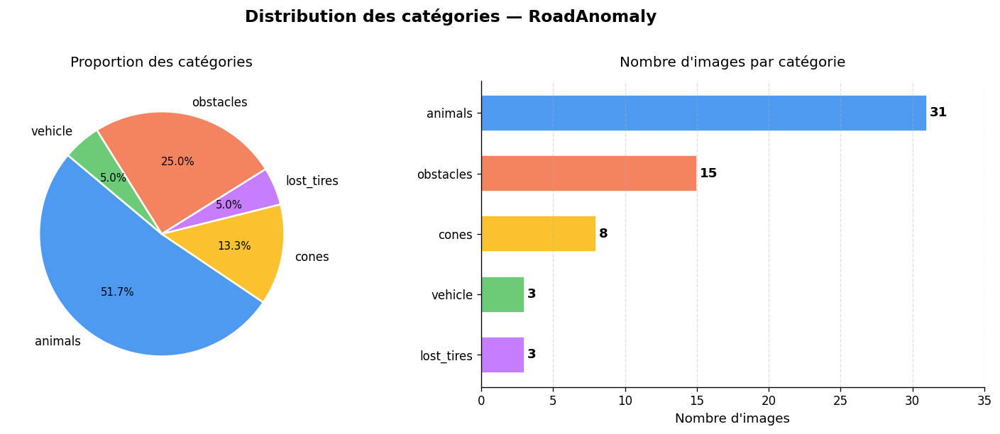


Observation : le dataset est déséquilibré — les animaux représentent plus de 50% des images.
Ce déséquilibre devra être pris en compte lors de l'entraînement des modèles.


In [ ]:
# ----------------------------------------------------------------
#  Figure 1 — Répartition des catégories (pie + bar)
# ----------------------------------------------------------------

categories = list(category_counts.keys())
counts     = list(category_counts.values())

# Palette de couleurs distinctes par catégorie
PALETTE = {
    'animals'   : '#4E9AF1',
    'obstacles' : '#F4845F',
    'cones'     : '#F9C22E',
    'vehicle'   : '#6BCB77',
    'lost_tires': '#C77DFF'
}
colors = [PALETTE.get(c, '#888888') for c in categories]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribution des catégories — RoadAnomaly', fontsize=14, fontweight='bold', y=1.01)

# --- Camembert ---
wedges, texts, autotexts = axes[0].pie(
    counts, labels=categories, colors=colors,
    autopct='%1.1f%%', startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for at in autotexts:
    at.set_fontsize(9)
axes[0].set_title("Proportion des catégories", pad=12)

# --- Barplot horizontal ---
sorted_cats   = sorted(category_counts.items(), key=lambda x: x[1])
s_categories  = [c for c, _ in sorted_cats]
s_counts      = [v for _, v in sorted_cats]
s_colors      = [PALETTE.get(c, '#888888') for c in s_categories]

bars = axes[1].barh(s_categories, s_counts, color=s_colors, edgecolor='white', height=0.6)
for bar, cnt in zip(bars, s_counts):
    axes[1].text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                 str(cnt), va='center', fontsize=11, fontweight='bold')
axes[1].set_xlabel("Nombre d'images", fontsize=11)
axes[1].set_title("Nombre d'images par catégorie", pad=12)
axes[1].set_xlim(0, max(s_counts) + 4)
axes[1].spines[['top','right']].set_visible(False)
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()
print("\nObservation : le dataset est déséquilibré — les animaux représentent plus de 50% des images.")
print("Ce déséquilibre devra être pris en compte lors de l'entraînement des modèles.")

---
## 4. Visualisation des images et des masques d'annotation

### 4.1 Comprendre le masque sémantique

Le masque sémantique (`labels_semantic.png`) est une image en niveaux de gris où :
- **Valeur 0** (noir) → pixels appartenant à la route normale (fond)
- **Valeur 2** (orange-rouge dans la version colorisée) → pixels anomalie

C'est cette carte qui servira de **ground truth** pour entraîner et évaluer les modèles.

In [ ]:
def visualize_sample(sample, ax_row):
    """
    Affiche sur une ligne de 4 axes :
      [0] Image originale
      [1] Masque sémantique (brut)
      [2] Masque colorisé (fourni par le dataset)
      [3] Superposition image + contour d'anomalie
    """
    img_rgb  = np.array(Image.open(sample['image_path']))
    sem_mask = np.array(Image.open(sample['labels_dir'] / 'labels_semantic.png'))
    col_path = sample['labels_dir'] / 'labels_semantic_color.png'
    col_mask = np.array(Image.open(col_path)) if col_path.exists() else np.stack([sem_mask * 100] * 3, -1).astype(np.uint8)

    # Création d'un masque binaire (0/1)
    binary_mask = (sem_mask == 2).astype(np.uint8)

    # Superposition : image + halo rouge sur les anomalies
    overlay = img_rgb.copy()
    overlay[binary_mask == 1] = (
        0.45 * overlay[binary_mask == 1] +
        0.55 * np.array([255, 60, 30])
    ).astype(np.uint8)

    n_anom  = binary_mask.sum()
    ratio   = 100 * n_anom / sem_mask.size
    n_inst  = len(load_index(sample).get('instances', []))
    title_base = sample['name'].replace('_', ' ')

    # --- Axe 0 : image originale ---
    ax_row[0].imshow(img_rgb)
    ax_row[0].set_title(f"Image originale\n[{sample['category']}]", fontsize=8.5)

    # --- Axe 1 : masque brut ---
    ax_row[1].imshow(sem_mask, cmap='gray', vmin=0, vmax=2)
    ax_row[1].set_title("Masque sémantique\n(0=fond, 2=anomalie)", fontsize=8.5)

    # --- Axe 2 : masque colorisé ---
    ax_row[2].imshow(col_mask)
    ax_row[2].set_title(f"Masque colorisé\n{n_inst} instance(s)", fontsize=8.5)

    # --- Axe 3 : superposition ---
    ax_row[3].imshow(overlay)
    ax_row[3].set_title(f"Superposition\n{ratio:.1f}% pixels anomalie", fontsize=8.5)

    for ax in ax_row:
        ax.axis('off')

print("✅ Fonction de visualisation définie")

✅ Fonction de visualisation définie


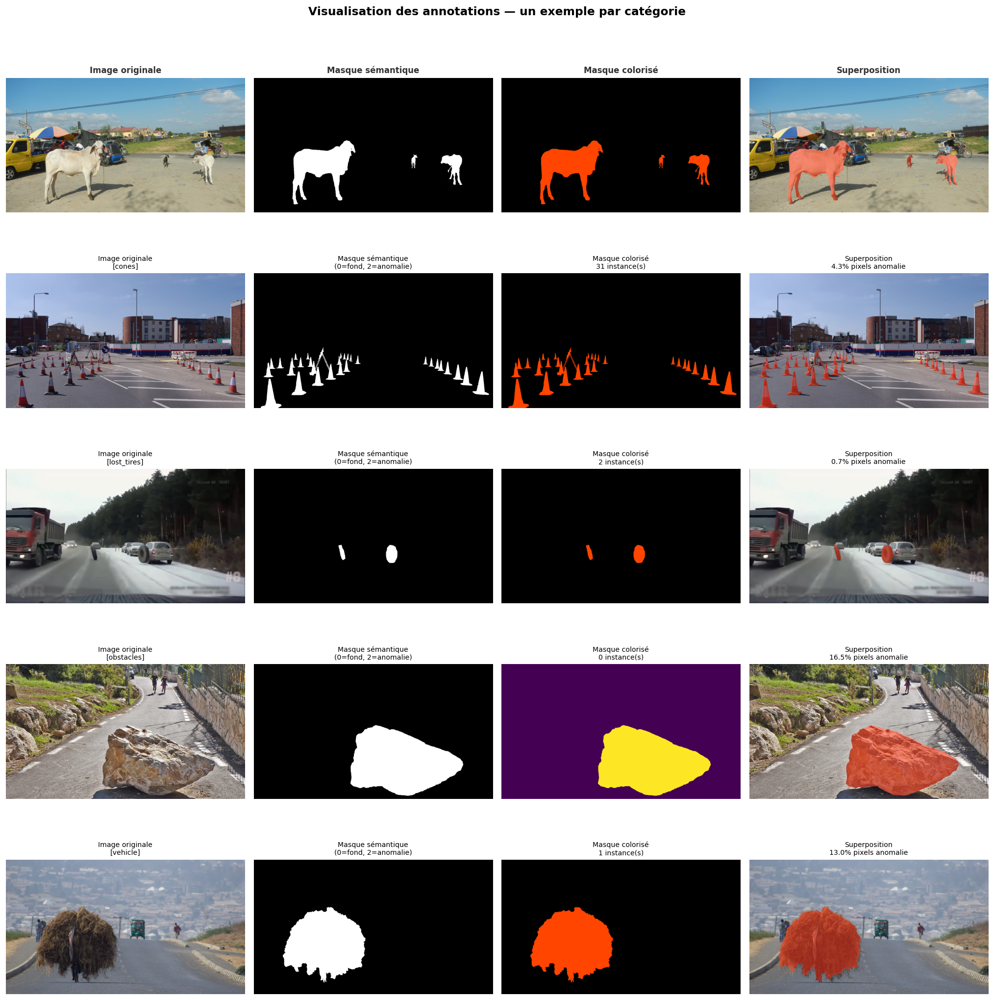

In [ ]:
# ----------------------------------------------------------------
#  Figure 2 — Un exemple par catégorie
# ----------------------------------------------------------------

# Sélection d'un représentant par catégorie
one_per_cat = {}
for s in samples:
    cat = s['category']
    if cat not in one_per_cat:
        one_per_cat[cat] = s

selected = list(one_per_cat.values())
n_rows   = len(selected)

fig, axes = plt.subplots(n_rows, 4, figsize=(17, 3.5 * n_rows), squeeze=False)
fig.suptitle(
    'Visualisation des annotations — un exemple par catégorie',
    fontsize=14, fontweight='bold', y=1.005
)

for i, s in enumerate(selected):
    visualize_sample(s, axes[i])
    # Étiquette de catégorie sur le bord gauche
    axes[i][0].set_ylabel(
        s['category'], fontsize=11, fontweight='bold',
        rotation=0, labelpad=55, va='center',
        color=list(PALETTE.values())[i % len(PALETTE)]
    )

# En-têtes des colonnes
col_titles = ['Image originale', 'Masque sémantique', 'Masque colorisé', 'Superposition']
for ax, ct in zip(axes[0], col_titles):
    ax.set_title(ct, fontsize=10, fontweight='bold', color='#333')

plt.tight_layout()
plt.show()

### 4.2 Zoom sur les instances individuelles

Pour chaque anomalie dans une image, le dataset fournit aussi un masque individuel (`instance_001_gc_mask.png`).  
Visualisons les instances isolées d'un exemple avec plusieurs objets.

Image sélectionnée : cones01_Beeston_MMB_A6_Middle_Street
Nombre d'instances : 31


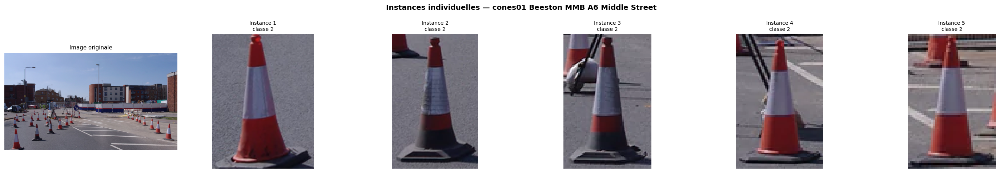

In [ ]:
# ----------------------------------------------------------------
#  Figure 3 — Instances individuelles (masques par objet)
# ----------------------------------------------------------------

# Sélection d'un échantillon avec plusieurs instances
multi = max(samples, key=lambda s: len(load_index(s).get('instances', [])))

img_rgb   = np.array(Image.open(multi['image_path']))
idx_data  = load_index(multi)
instances = idx_data['instances']

print(f"Image sélectionnée : {multi['name']}")
print(f"Nombre d'instances : {len(instances)}")

# Collecte des masques d'instances
instance_masks = []
for inst in instances:
    mask_path = multi['labels_dir'] / f"instance_{inst['id']:03d}_gc_mask.png"
    if mask_path.exists():
        instance_masks.append((inst, np.array(Image.open(mask_path))))

# Affichage
n_inst = len(instance_masks)
cols   = min(n_inst + 1, 5)  # image originale + masques
n_cols = min(n_inst + 1, 6)
fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 4), squeeze=False)
axes = axes[0]
fig.suptitle(
    f"Instances individuelles — {multi['name'].replace('_',' ')}",
    fontsize=12, fontweight='bold'
)

# Image originale
axes[0].imshow(img_rgb)
axes[0].set_title('Image originale', fontsize=9)
axes[0].axis('off')

# Masques d'instances avec crop
for i, (inst, mask) in enumerate(instance_masks[:5]):
    ax = axes[i + 1]
    # Crop sur le roi_rect de l'instance
    r = inst['roi_rect']
    col_min, row_min = r[0][0], r[0][1]
    col_max, row_max = r[1][0], r[1][1]
    crop_img  = img_rgb[row_min:row_max, col_min:col_max]
    crop_mask = mask[row_min:row_max, col_min:col_max]

    # Superposition du masque sur le crop
    overlay_crop = crop_img.copy()
    overlay_crop[crop_mask > 0] = (
        0.4 * overlay_crop[crop_mask > 0] + 0.6 * np.array([255, 60, 30])
    ).astype(np.uint8)

    ax.imshow(overlay_crop)
    ax.set_title(f"Instance {inst['id']}\nclasse {inst['cls']}", fontsize=8.5)
    ax.axis('off')

plt.tight_layout()
plt.show()

---
## 5. Analyse de la distribution des anomalies

### 5.1 Distribution du ratio d'anomalie par image

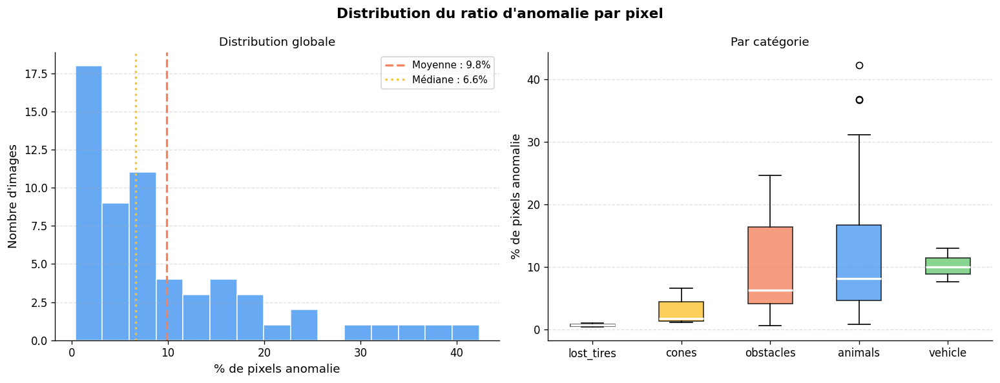


Statistiques du ratio d'anomalie :
  Minimum  : 0.37%
  Maximum  : 42.33%
  Moyenne  : 9.85%
  Médiane  : 6.62%
  Écart-type : 9.98%


In [ ]:
# ----------------------------------------------------------------
#  Figure 4 — Histogramme du ratio d'anomalie + boxplot par cat.
# ----------------------------------------------------------------

# Calcul des ratios par catégorie
cat_ratios = defaultdict(list)
for s, r in zip(samples, anomaly_ratios):
    cat_ratios[s['category']].append(r * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Distribution du ratio d'anomalie par pixel", fontsize=13, fontweight='bold')

# --- Histogramme global ---
axes[0].hist(
    [r * 100 for r in anomaly_ratios], bins=15,
    color='#4E9AF1', edgecolor='white', alpha=0.85
)
axes[0].axvline(
    np.mean(anomaly_ratios) * 100, color='#F4845F', linewidth=2,
    linestyle='--', label=f"Moyenne : {np.mean(anomaly_ratios)*100:.1f}%"
)
axes[0].axvline(
    np.median(anomaly_ratios) * 100, color='#F9C22E', linewidth=2,
    linestyle=':', label=f"Médiane : {np.median(anomaly_ratios)*100:.1f}%"
)
axes[0].set_xlabel("% de pixels anomalie", fontsize=11)
axes[0].set_ylabel("Nombre d'images", fontsize=11)
axes[0].set_title("Distribution globale", fontsize=11)
axes[0].legend(fontsize=9)
axes[0].spines[['top','right']].set_visible(False)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# --- Boxplot par catégorie ---
sorted_cats = sorted(cat_ratios.keys(), key=lambda c: np.median(cat_ratios[c]))
bp = axes[1].boxplot(
    [cat_ratios[c] for c in sorted_cats],
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2)
)
axes[1].set_xticklabels(sorted_cats)
for patch, cat in zip(bp['boxes'], sorted_cats):
    patch.set_facecolor(PALETTE.get(cat, '#888'))
    patch.set_alpha(0.8)

axes[1].set_ylabel("% de pixels anomalie", fontsize=11)
axes[1].set_title("Par catégorie", fontsize=11)
axes[1].spines[['top','right']].set_visible(False)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("\nStatistiques du ratio d'anomalie :")
print(f"  Minimum  : {min(anomaly_ratios)*100:.2f}%")
print(f"  Maximum  : {max(anomaly_ratios)*100:.2f}%")
print(f"  Moyenne  : {np.mean(anomaly_ratios)*100:.2f}%")
print(f"  Médiane  : {np.median(anomaly_ratios)*100:.2f}%")
print(f"  Écart-type : {np.std(anomaly_ratios)*100:.2f}%")

### 5.2 Distribution spatiale des anomalies

Où se situent typiquement les anomalies dans l'image ? La heatmap de densité permet de repérer les zones préférentielles (ex. centre de l'image, partie basse correspondant à la chaussée).

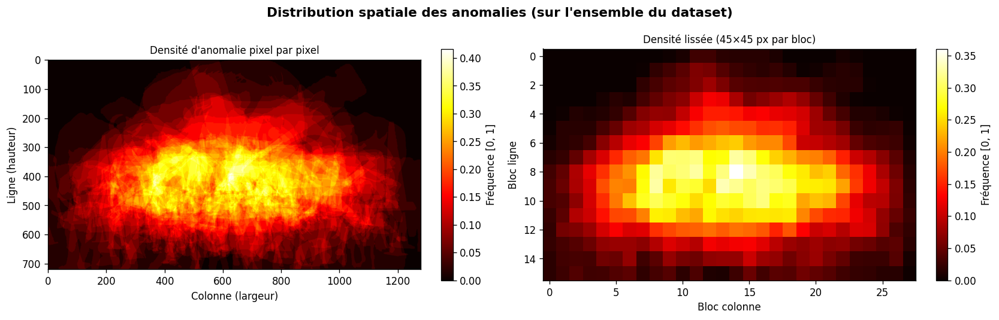


Observation : les anomalies sont concentrées dans la zone centrale-basse de l'image,
ce qui correspond à la surface de la route visible depuis le véhicule.


In [ ]:
# ----------------------------------------------------------------
#  Figure 5 — Heatmap de densité spatiale des anomalies
# ----------------------------------------------------------------

# Accumulation de tous les masques binaires
H, W   = 720, 1280  # résolution fixe du dataset
density = np.zeros((H, W), dtype=np.float32)

for s in samples:
    sem = np.array(Image.open(s['labels_dir'] / 'labels_semantic.png'))
    density += (sem == 2).astype(np.float32)

density_norm = density / len(samples)  # proportion d'images où le pixel est anomalie

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fig.suptitle(
    "Distribution spatiale des anomalies (sur l'ensemble du dataset)",
    fontsize=13, fontweight='bold'
)

# Heatmap brute
im1 = axes[0].imshow(density_norm, cmap='hot', vmin=0, vmax=density_norm.max())
axes[0].set_title("Densité d'anomalie pixel par pixel", fontsize=10)
axes[0].set_xlabel("Colonne (largeur)"); axes[0].set_ylabel("Ligne (hauteur)")
plt.colorbar(im1, ax=axes[0], fraction=0.03, label="Fréquence [0, 1]")

# Heatmap lissée (moyenne par blocs 45×45)
block = 45
H_b, W_b = H // block, W // block
density_blk = density_norm[:H_b*block, :W_b*block].reshape(H_b, block, W_b, block).mean(axis=(1,3))

im2 = axes[1].imshow(density_blk, cmap='hot', aspect='auto')
axes[1].set_title(f"Densité lissée ({block}×{block} px par bloc)", fontsize=10)
axes[1].set_xlabel("Bloc colonne"); axes[1].set_ylabel("Bloc ligne")
plt.colorbar(im2, ax=axes[1], fraction=0.03, label="Fréquence [0, 1]")

plt.tight_layout()
plt.show()
print("\nObservation : les anomalies sont concentrées dans la zone centrale-basse de l'image,")
print("ce qui correspond à la surface de la route visible depuis le véhicule.")

### 5.3 Analyse des bounding boxes d'instances

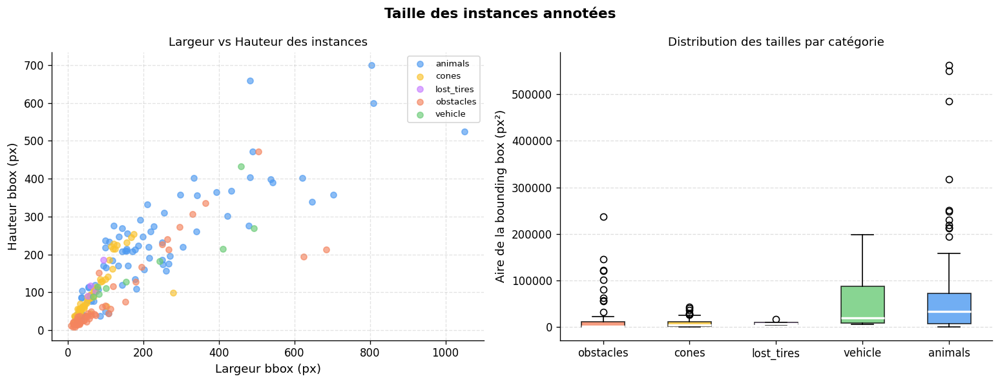


Instances totales analysées : 201
Aire moyenne  : 22111 px²
Largeur moy.  : 151 px  |  Hauteur moy. : 146 px


In [ ]:
# ----------------------------------------------------------------
#  Figure 6 — Taille des bounding boxes par catégorie
# ----------------------------------------------------------------

bb_areas   = defaultdict(list)  # {catégorie: [aire en px²]}
bb_widths  = []
bb_heights = []

for s in samples:
    idx = load_index(s)
    for inst in idx.get('instances', []):
        r = inst['roi_rect']
        w = r[1][0] - r[0][0]   # largeur
        h = r[1][1] - r[0][1]   # hauteur
        area = w * h
        bb_areas[s['category']].append(area)
        bb_widths.append(w)
        bb_heights.append(h)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Taille des instances annotées", fontsize=13, fontweight='bold')

# Scatter largeur × hauteur
cat_list = []
for s in samples:
    idx = load_index(s)
    for inst in idx.get('instances', []):
        cat_list.append(s['category'])

for cat in sorted(PALETTE.keys()):
    mask = [c == cat for c in cat_list]
    xs   = [bb_widths[i]  for i, m in enumerate(mask) if m]
    ys   = [bb_heights[i] for i, m in enumerate(mask) if m]
    if xs:
        axes[0].scatter(xs, ys, label=cat, color=PALETTE[cat], alpha=0.65, s=30)

axes[0].set_xlabel("Largeur bbox (px)", fontsize=11)
axes[0].set_ylabel("Hauteur bbox (px)", fontsize=11)
axes[0].set_title("Largeur vs Hauteur des instances", fontsize=11)
axes[0].legend(fontsize=8)
axes[0].spines[['top','right']].set_visible(False)
axes[0].grid(linestyle='--', alpha=0.35)

# Boxplot des aires
sorted_c = sorted(bb_areas.keys(), key=lambda c: np.median(bb_areas[c]))
bp2 = axes[1].boxplot(
    [bb_areas[c] for c in sorted_c],
    patch_artist=True,
    medianprops=dict(color='white', linewidth=2)
)
axes[1].set_xticklabels(sorted_c)
for patch, cat in zip(bp2['boxes'], sorted_c):
    patch.set_facecolor(PALETTE.get(cat, '#888'))
    patch.set_alpha(0.8)

axes[1].set_ylabel("Aire de la bounding box (px²)", fontsize=11)
axes[1].set_title("Distribution des tailles par catégorie", fontsize=11)
axes[1].spines[['top','right']].set_visible(False)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

total_bb = sum(len(v) for v in bb_areas.values())
print(f"\nInstances totales analysées : {total_bb}")
print(f"Aire moyenne  : {np.mean(bb_widths)*np.mean(bb_heights):.0f} px²")
print(f"Largeur moy.  : {np.mean(bb_widths):.0f} px  |  Hauteur moy. : {np.mean(bb_heights):.0f} px")

---
## 6. Analyse des canaux colorimétriques

Comparer la distribution des valeurs RGB entre les pixels normaux et les pixels anomalie peut révéler des différences exploitables par le modèle.

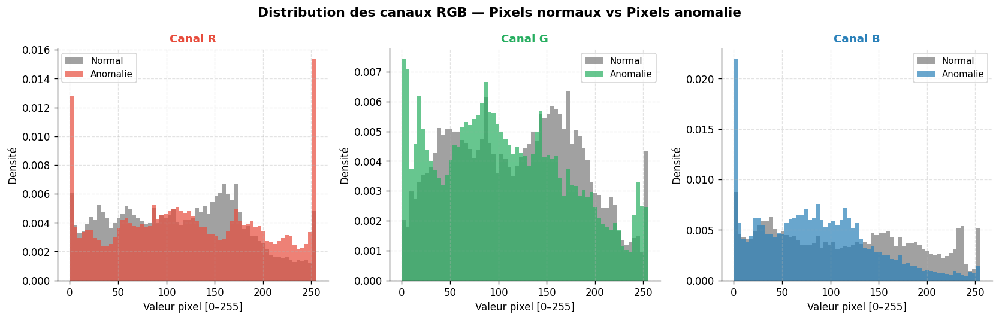

Canal R — Moy. normal : 114.0  |  Moy. anomalie : 125.7  |  Δ = +11.8
Canal G — Moy. normal : 119.6  |  Moy. anomalie : 106.8  |  Δ = -12.8
Canal B — Moy. normal : 114.4  |  Moy. anomalie : 84.5  |  Δ = -29.9


In [ ]:
# ----------------------------------------------------------------
#  Figure 7 — Histogrammes RGB : normal vs anomalie
# ----------------------------------------------------------------

# Échantillonnage sur 15 images pour limiter la mémoire
rng      = np.random.default_rng(42)
subset   = [samples[i] for i in rng.choice(len(samples), size=min(15, len(samples)), replace=False)]

pix_normal  = {c: [] for c in ['R','G','B']}
pix_anomaly = {c: [] for c in ['R','G','B']}
channel_names = ['R','G','B']

for s in subset:
    img  = np.array(Image.open(s['image_path']))
    sem  = np.array(Image.open(s['labels_dir'] / 'labels_semantic.png'))
    mask_anom = sem == 2
    mask_norm = sem == 0

    # Sous-échantillonnage pour ne pas surcharger la mémoire
    idx_n = np.argwhere(mask_norm)
    idx_a = np.argwhere(mask_anom)
    k_n   = min(2000, len(idx_n))
    k_a   = min(2000, len(idx_a))
    sel_n = rng.choice(len(idx_n), size=k_n, replace=False)
    sel_a = rng.choice(len(idx_a), size=k_a, replace=False)

    for ci, ch in enumerate(channel_names):
        pix_normal[ch].extend(img[idx_n[sel_n][:, 0], idx_n[sel_n][:, 1], ci].tolist())
        if k_a > 0:
            pix_anomaly[ch].extend(img[idx_a[sel_a][:, 0], idx_a[sel_a][:, 1], ci].tolist())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.suptitle(
    "Distribution des canaux RGB — Pixels normaux vs Pixels anomalie",
    fontsize=13, fontweight='bold'
)

ch_colors = {'R': '#E74C3C', 'G': '#27AE60', 'B': '#2980B9'}

for ax, ch in zip(axes, channel_names):
    bins = np.linspace(0, 255, 64)
    ax.hist(pix_normal[ch],  bins=bins, density=True, alpha=0.55,
            color='#555', label='Normal')
    ax.hist(pix_anomaly[ch], bins=bins, density=True, alpha=0.70,
            color=ch_colors[ch], label='Anomalie')
    ax.set_title(f"Canal {ch}", fontsize=11, color=ch_colors[ch], fontweight='bold')
    ax.set_xlabel("Valeur pixel [0–255]")
    ax.set_ylabel("Densité")
    ax.legend(fontsize=9)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

for ch in channel_names:
    mn = np.mean(pix_normal[ch])
    ma = np.mean(pix_anomaly[ch])
    print(f"Canal {ch} — Moy. normal : {mn:.1f}  |  Moy. anomalie : {ma:.1f}  |  Δ = {ma-mn:+.1f}")

---
## 7. Synthèse et observations pour la suite du projet

Cette cellule récapitule les observations clés et formule des recommandations concrètes.

In [ ]:
print("="*60)
print("   SYNTHÈSE — PARTIE 1 : EXPLORATION")
print("="*60)

print("""
📁 STRUCTURE DU DATASET
   • 60 images (1280×720 px, format WebP, RGB)
   • 5 catégories d'anomalies : animals, obstacles,
     cones, vehicle, lost_tires
   • 201 instances annotées au niveau pixel
   • 1 masque sémantique par image (0 = normal, 2 = anomalie)

⚠️  OBSERVATIONS IMPORTANTES
   1. DÉSÉQUILIBRE DES CLASSES
      → Les anomalies ne représentent que ~9.85% des pixels
      → Les modèles naïfs tendent à prédire "tout normal"
      → Remède : loss pondérée (weighted BCE), oversampling
        ou Focal Loss

   2. DÉSÉQUILIBRE DES CATÉGORIES
      → Animals = 52% des images, vehicle = 5%
      → Impact sur la généralisation du modèle
      → Remède : data augmentation ciblée

   3. DISTRIBUTION SPATIALE
      → Anomalies concentrées au centre-bas (chaussée)
      → Les architectures avec contexte global (attention)
        pourraient en bénéficier

   4. SIMILITUDE VISUELLE NORMAL / ANOMALIE
      → Les distributions RGB se chevauchent fortement
      → La texture et la forme sont plus discriminantes
        que la couleur seule → favorise les CNN profonds

🔜 PROCHAINES ÉTAPES (Partie 2)
   • Conversion WebP → PNG ou normalisation pour PyTorch
   • Split train / validation / test (ex. 70/15/15)
   • Data augmentation : flip, rotation, jitter colorimétrique
   • Construction du DataLoader avec masques binaires
     (0/1 après binarisation de la valeur 2 → 1)
""")
print("="*60)

   SYNTHÈSE — PARTIE 1 : EXPLORATION

📁 STRUCTURE DU DATASET
   • 60 images (1280×720 px, format WebP, RGB)
   • 5 catégories d'anomalies : animals, obstacles,
     cones, vehicle, lost_tires
   • 201 instances annotées au niveau pixel
   • 1 masque sémantique par image (0 = normal, 2 = anomalie)

⚠️  OBSERVATIONS IMPORTANTES
   1. DÉSÉQUILIBRE DES CLASSES
      → Les anomalies ne représentent que ~9.85% des pixels
      → Les modèles naïfs tendent à prédire "tout normal"
      → Remède : loss pondérée (weighted BCE), oversampling
        ou Focal Loss

   2. DÉSÉQUILIBRE DES CATÉGORIES
      → Animals = 52% des images, vehicle = 5%
      → Impact sur la généralisation du modèle
      → Remède : data augmentation ciblée

   3. DISTRIBUTION SPATIALE
      → Anomalies concentrées au centre-bas (chaussée)
      → Les architectures avec contexte global (attention)
        pourraient en bénéficier

   4. SIMILITUDE VISUELLE NORMAL / ANOMALIE
      → Les distributions RGB se chevauchent fort

---
*Notebook réalisé dans le cadre du module Deep Learning — Détection d'anomalies routières — RoadAnomaly dataset (Lis et al., ICCV 2019)*

---
# PARTIE 2 — Prétraitement et DataLoader

# Projet Deep Learning — Détection d'Anomalies Routières
## Partie 2 : Preprocessing & DataLoader PyTorch

**Objectif de cette partie :**  
Préparer le pipeline de données qui alimentera les modèles de la Partie 3.  
On construit :
1. Un **`Dataset` PyTorch** qui charge image + masque binaire
2. Un **split train/val/test** reproductible (70 / 15 / 15)
3. Les **transformations** (resize, normalisation, augmentation)
4. Les **DataLoaders** prêts pour l'entraînement
5. Une **vérification visuelle** du pipeline

---
**Structure du notebook :**
1. Imports et configuration
2. Classe `RoadAnomalyDataset`
3. Split train / val / test
4. Transformations et augmentation
5. DataLoaders
6. Vérification visuelle du pipeline
7. Analyse du déséquilibre de classes & calcul des poids

---
## 1. Imports et configuration

In [ ]:
import os
import re
import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Bibliothèques importées')
print(f'   PyTorch version : {torch.__version__}')
print(f'   Device          : {DEVICE}')

✅ Bibliothèques importées
   PyTorch version : 2.11.0+cu130
   Device          : cuda


### 1.1 Chemin vers le dataset

In [ ]:
# ============================================================
#  ADAPTEZ CE CHEMIN selon votre environnement
#  Exemple local  : Path("./RoadAnomaly")
#  Exemple Kaggle : Path("/kaggle/input/road-anomaly/RoadAnomaly")
# ============================================================
# DATASET_ROOT et FRAMES_DIR viennent de la cellule de configuration

assert DATASET_ROOT.exists(), f'❌ Dataset introuvable : {DATASET_ROOT}'
assert FRAMES_DIR.exists(),   f'❌ Dossier frames introuvable : {FRAMES_DIR}'

# Taille d'entrée pour les modèles (multiple de 32 pour U-Net)
IMG_HEIGHT = 256
IMG_WIDTH  = 512

print(f'✅ Dataset : {DATASET_ROOT.resolve()}')
print(f'   Taille de redimensionnement : {IMG_HEIGHT} × {IMG_WIDTH}')

✅ Dataset : /content/RoadAnomaly_data/RoadAnomaly
   Taille de redimensionnement : 256 × 512


---
## 2. Classe `RoadAnomalyDataset`

Un `Dataset` PyTorch doit implémenter :
- `__len__()` → nombre total d'échantillons
- `__getitem__(idx)` → retourne `(image_tensor, mask_tensor)` pour l'indice `idx`

**Binarisation du masque :**  
Le masque sémantique a des valeurs 0 (normal) et 2 (anomalie).  
On le convertit en masque binaire : `mask = (sem == 2).astype(float)` → 0.0 ou 1.0

**Normalisation de l'image :**  
On normalise avec les statistiques ImageNet (moyenne et écart-type par canal RGB)  
car les modèles pré-entraînés (ResNet, etc.) ont été entraînés sur ces valeurs.

In [ ]:
# Statistiques ImageNet pour la normalisation
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


class RoadAnomalyDataset(Dataset):
    """
    Dataset PyTorch pour RoadAnomaly.

    Retourne pour chaque indice :
        image : FloatTensor [3, H, W]  — valeurs normalisées (ImageNet stats)
        mask  : FloatTensor [1, H, W]  — binaire : 0 = normal, 1 = anomalie

    Paramètres
    ----------
    samples       : liste de dicts issus de collect_samples()
    img_size      : tuple (H, W) pour le redimensionnement
    augment       : bool — applique l'augmentation si True (train seulement)
    """

    def __init__(self, samples, img_size=(256, 512), augment=False):
        self.samples  = samples
        self.img_size = img_size      # (H, W)
        self.augment  = augment

        # Transformation de base : resize + ToTensor + Normalize
        self.img_transform = T.Compose([
            T.Resize(img_size, interpolation=T.InterpolationMode.BILINEAR),
            T.ToTensor(),                                     # [0,255] → [0,1]
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        ])

        # Pour le masque : resize avec NEAREST (pas d'interpolation)
        self.mask_resize = T.Resize(
            img_size,
            interpolation=T.InterpolationMode.NEAREST
        )

    # ------------------------------------------------------------------
    def __len__(self):
        return len(self.samples)

    # ------------------------------------------------------------------
    def __getitem__(self, idx):
        s = self.samples[idx]

        # --- Chargement ---
        img_pil = Image.open(s['image_path']).convert('RGB')
        sem_np  = np.array(Image.open(s['labels_dir'] / 'labels_semantic.png'))

        # --- Binarisation du masque (valeur 2 → 1, reste → 0) ---
        bin_mask = (sem_np == 2).astype(np.uint8) * 255   # PIL attend [0,255]
        mask_pil = Image.fromarray(bin_mask, mode='L')     # image en niveaux de gris

        # --- Augmentation (train seulement) ---
        if self.augment:
            img_pil, mask_pil = self._augment(img_pil, mask_pil)

        # --- Transformation de l'image ---
        img_tensor = self.img_transform(img_pil)           # FloatTensor [3, H, W]

        # --- Transformation du masque ---
        mask_pil   = self.mask_resize(mask_pil)
        mask_np    = np.array(mask_pil, dtype=np.float32) / 255.0   # → [0,1]
        mask_tensor = torch.from_numpy(mask_np).unsqueeze(0)        # [1, H, W]

        return img_tensor, mask_tensor

    # ------------------------------------------------------------------
    def _augment(self, img, mask):
        """
        Augmentations géométriques et colorimétriques.
        IMPORTANT : image et masque doivent subir exactement les MÊMES
        transformations géométriques (flip, rotation) pour rester alignés.
        Les transformations colorimétriques ne s'appliquent qu'à l'image.
        """
        # Flip horizontal aléatoire (p=0.5)
        if random.random() > 0.5:
            img  = TF.hflip(img)
            mask = TF.hflip(mask)

        # Rotation légère aléatoire ±10°
        if random.random() > 0.5:
            angle = random.uniform(-10, 10)
            img  = TF.rotate(img,  angle, interpolation=T.InterpolationMode.BILINEAR)
            mask = TF.rotate(mask, angle, interpolation=T.InterpolationMode.NEAREST)

        # Jitter colorimétrique (image seulement)
        if random.random() > 0.5:
            img = T.ColorJitter(
                brightness=0.3, contrast=0.3,
                saturation=0.2, hue=0.05
            )(img)

        # Flou gaussien léger (image seulement, p=0.3)
        if random.random() > 0.7:
            img = T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5))(img)

        return img, mask


print('✅ Classe RoadAnomalyDataset définie')

✅ Classe RoadAnomalyDataset définie


---
## 3. Collecte des échantillons & Split train / val / test

**Stratégie de split :**  
On effectue un **split stratifié par catégorie** pour garantir que chaque catégorie
(animals, cones, obstacles, vehicle, lost_tires) est représentée proportionnellement
dans les trois ensembles.

Proportions : **70% train / 15% val / 15% test**

In [ ]:
def collect_samples(frames_dir):
    """Collecte tous les échantillons valides (image + dossier .labels)."""
    samples = []
    for item in sorted(frames_dir.iterdir()):
        if item.suffix == '.webp':
            name       = item.stem
            labels_dir = frames_dir / (name + '.labels')
            cat_match  = re.match(r'([a-z]+)', name)
            if not cat_match:
                continue
            category = cat_match.group(1)
            if category == 'lost':
                category = 'lost_tires'
            if labels_dir.exists() and (labels_dir / 'labels_semantic.png').exists():
                samples.append({
                    'name'       : name,
                    'image_path' : item,
                    'labels_dir' : labels_dir,
                    'category'   : category
                })
    return samples


all_samples = collect_samples(FRAMES_DIR)
print(f'Échantillons totaux : {len(all_samples)}')

Échantillons totaux : 60


In [ ]:
def stratified_split(samples, train_ratio=0.70, val_ratio=0.15, seed=42):
    """
    Split stratifié par catégorie.
    Retourne trois listes : train_samples, val_samples, test_samples.
    """
    rng = random.Random(seed)

    # Grouper par catégorie
    by_cat = defaultdict(list)
    for s in samples:
        by_cat[s['category']].append(s)

    train_list, val_list, test_list = [], [], []

    for cat, cat_samples in by_cat.items():
        cat_samples = list(cat_samples)
        rng.shuffle(cat_samples)
        n      = len(cat_samples)
        n_tr   = max(1, int(n * train_ratio))
        n_val  = max(1, int(n * val_ratio))
        # Le reste va en test
        train_list.extend(cat_samples[:n_tr])
        val_list.extend(cat_samples[n_tr:n_tr + n_val])
        test_list.extend(cat_samples[n_tr + n_val:])

    return train_list, val_list, test_list


train_samples, val_samples, test_samples = stratified_split(all_samples, seed=SEED)

print(f'Train : {len(train_samples)} images')
print(f'Val   : {len(val_samples)} images')
print(f'Test  : {len(test_samples)} images')
print()

# Vérification : répartition par catégorie
all_cats = sorted(set(s['category'] for s in all_samples))
print(f'  {"Catégorie":<14} {"Total":>6}  {"Train":>6}  {"Val":>5}  {"Test":>5}')
print('  ' + '-'*42)
for cat in all_cats:
    t  = sum(1 for s in train_samples if s['category'] == cat)
    v  = sum(1 for s in val_samples   if s['category'] == cat)
    te = sum(1 for s in test_samples  if s['category'] == cat)
    tot = t + v + te
    print(f'  {cat:<14} {tot:>6}  {t:>6}  {v:>5}  {te:>5}')

Train : 40 images
Val   : 9 images
Test  : 11 images

  Catégorie       Total   Train    Val   Test
  ------------------------------------------
  animals            31      21      4      6
  cones               8       5      1      2
  lost_tires          3       2      1      0
  obstacles          15      10      2      3
  vehicle             3       2      1      0


---
## 4. Instanciation des Datasets avec transformations

**Règle d'or :**  
- `train_dataset` → `augment=True` (flip, rotation, jitter)
- `val_dataset` et `test_dataset` → `augment=False` (uniquement resize + normalisation)

L'augmentation ne s'applique qu'au train : on veut évaluer sur des images non-modifiées.

In [ ]:
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)   # (256, 512)

train_dataset = RoadAnomalyDataset(train_samples, img_size=IMG_SIZE, augment=True)
val_dataset   = RoadAnomalyDataset(val_samples,   img_size=IMG_SIZE, augment=False)
test_dataset  = RoadAnomalyDataset(test_samples,  img_size=IMG_SIZE, augment=False)

print(f'train_dataset : {len(train_dataset)} échantillons')
print(f'val_dataset   : {len(val_dataset)} échantillons')
print(f'test_dataset  : {len(test_dataset)} échantillons')

# Vérification des dimensions d'un tenseur
img_t, msk_t = train_dataset[0]
print()
print(f'Image tensor  : shape={img_t.shape}, dtype={img_t.dtype}')
print(f'Mask tensor   : shape={msk_t.shape}, dtype={msk_t.dtype}')
print(f'  Valeurs uniques du masque : {msk_t.unique().tolist()}')

train_dataset : 40 échantillons
val_dataset   : 9 échantillons
test_dataset  : 11 échantillons

Image tensor  : shape=torch.Size([3, 256, 512]), dtype=torch.float32
Mask tensor   : shape=torch.Size([1, 256, 512]), dtype=torch.float32
  Valeurs uniques du masque : [0.0, 1.0]


/tmp/ipykernel_772/746029225.py:53: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray(bin_mask, mode='L')     # image en niveaux de gris


---
## 5. Création des DataLoaders

Le `DataLoader` est le composant qui :
- **Bat les cartes** (`shuffle=True` pour le train)
- **Groupe les échantillons en batches** (`batch_size`)
- **Charge en parallèle** (`num_workers`)

**Choix du `batch_size` :**  
- 8 à 16 sur GPU (adapter selon la VRAM disponible)
- 4 sur CPU (entraînement plus lent)

In [ ]:
BATCH_SIZE  = 8
NUM_WORKERS = 0   # 0 = chargement dans le processus principal (compatibilité Windows)
                   # Mettre 2 ou 4 si vous êtes sur Linux / Kaggle pour plus de vitesse

train_loader = DataLoader(
    train_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,          # mélange à chaque époque
    num_workers = NUM_WORKERS,
    pin_memory  = DEVICE.type == 'cuda',   # accélère le transfert CPU→GPU
    drop_last   = True           # ignore le dernier batch incomplet
)

val_loader = DataLoader(
    val_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,         # pas de mélange : reproductibilité de l'évaluation
    num_workers = NUM_WORKERS,
    pin_memory  = DEVICE.type == 'cuda'
)

test_loader = DataLoader(
    test_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = DEVICE.type == 'cuda'
)

print(f'train_loader : {len(train_loader)} batches × {BATCH_SIZE} = {len(train_loader)*BATCH_SIZE} images/époque')
print(f'val_loader   : {len(val_loader)} batches')
print(f'test_loader  : {len(test_loader)} batches')

# Test : récupération d'un batch
imgs, masks = next(iter(train_loader))
print()
print(f'Batch images : {imgs.shape}   — FloatTensor [B, 3, H, W]')
print(f'Batch masks  : {masks.shape}  — FloatTensor [B, 1, H, W]')

train_loader : 5 batches × 8 = 40 images/époque
val_loader   : 2 batches
test_loader  : 2 batches


/tmp/ipykernel_772/746029225.py:53: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray(bin_mask, mode='L')     # image en niveaux de gris



Batch images : torch.Size([8, 3, 256, 512])   — FloatTensor [B, 3, H, W]
Batch masks  : torch.Size([8, 1, 256, 512])  — FloatTensor [B, 1, H, W]


---
## 6. Vérification visuelle du pipeline

Avant d'entraîner, il est **indispensable** de vérifier visuellement que :
1. L'image et le masque sont bien **alignés** après transformation
2. La **normalisation** est correcte (valeurs entre ~-2 et ~2)
3. L'**augmentation** ne brise pas l'alignement image/masque

Pour visualiser, on **dénormalise** l'image avant de l'afficher.

In [ ]:
def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """
    Inverse la normalisation ImageNet pour récupérer une image affichable.
    Entrée  : FloatTensor [3, H, W] normalisé
    Sortie  : ndarray [H, W, 3] uint8 dans [0, 255]
    """
    t = tensor.clone()
    for c, m, s in zip(range(3), mean, std):
        t[c] = t[c] * s + m          # x = (x_norm * std) + mean
    t = t.clamp(0, 1)                # sécurité
    return (t.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


print('✅ Fonction denormalize définie')

✅ Fonction denormalize définie


/tmp/ipykernel_772/746029225.py:53: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray(bin_mask, mode='L')     # image en niveaux de gris


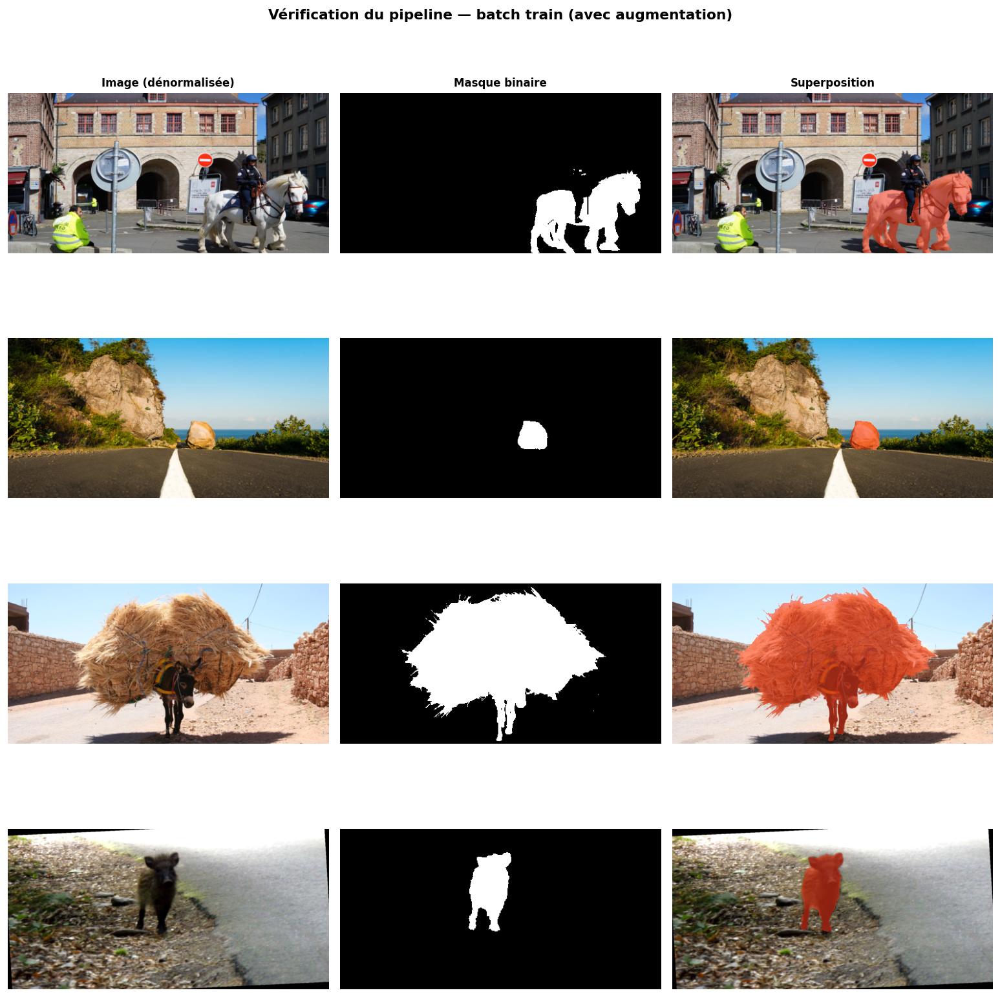


Si le masque rouge est bien aligné sur l'anomalie → le pipeline est correct ✅


In [ ]:
# ----------------------------------------------------------------
#  Figure 1 — Vérification du pipeline (8 exemples du batch)
# ----------------------------------------------------------------

imgs_b, masks_b = next(iter(train_loader))
n_show = min(4, len(imgs_b))

fig, axes = plt.subplots(n_show, 3, figsize=(13, 3.5 * n_show))
fig.suptitle(
    'Vérification du pipeline — batch train (avec augmentation)',
    fontsize=13, fontweight='bold'
)

col_titles = ['Image (dénormalisée)', 'Masque binaire', 'Superposition']
for j, ct in enumerate(col_titles):
    axes[0][j].set_title(ct, fontsize=10, fontweight='bold')

for i in range(n_show):
    img_np  = denormalize(imgs_b[i])
    mask_np = masks_b[i, 0].numpy()   # [H, W], valeurs 0 ou 1

    # Superposition
    overlay = img_np.copy()
    overlay[mask_np > 0.5] = (
        0.45 * overlay[mask_np > 0.5] +
        0.55 * np.array([255, 60, 30])
    ).astype(np.uint8)

    ratio = mask_np.mean() * 100

    axes[i][0].imshow(img_np)
    axes[i][0].set_ylabel(f'Ex. {i+1}\n{ratio:.1f}% anomalie', fontsize=9, rotation=0,
                           labelpad=60, va='center')
    axes[i][1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
    axes[i][2].imshow(overlay)
    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()
print('\nSi le masque rouge est bien aligné sur l\'anomalie → le pipeline est correct ✅')

/tmp/ipykernel_772/746029225.py:53: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  mask_pil = Image.fromarray(bin_mask, mode='L')     # image en niveaux de gris


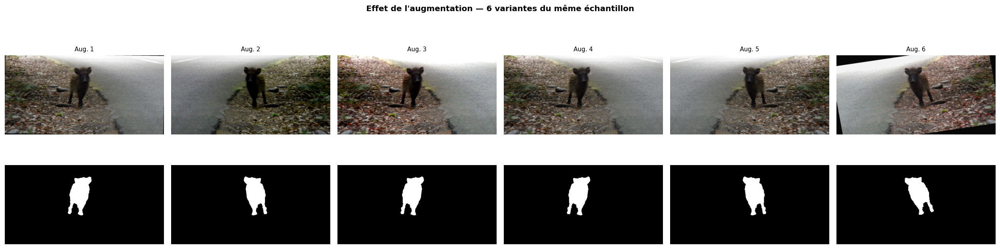

Observation : image et masque subissent exactement les mêmes transformations géométriques.


In [ ]:
# ----------------------------------------------------------------
#  Figure 2 — Effet de l'augmentation sur le même échantillon
#              (même image, 6 augmentations différentes)
# ----------------------------------------------------------------

# Créer un dataset augmenté sur 1 seul échantillon (train[0])
single_sample_ds = RoadAnomalyDataset([train_samples[0]], img_size=IMG_SIZE, augment=True)

n_aug = 6
fig, axes = plt.subplots(2, n_aug, figsize=(3.5 * n_aug, 6))
fig.suptitle(
    f'Effet de l\'augmentation — {n_aug} variantes du même échantillon',
    fontsize=12, fontweight='bold'
)

for k in range(n_aug):
    img_k, msk_k = single_sample_ds[0]  # chaque appel tire une augmentation aléatoire
    axes[0][k].imshow(denormalize(img_k))
    axes[0][k].set_title(f'Aug. {k+1}', fontsize=9)
    axes[0][k].axis('off')

    axes[1][k].imshow(msk_k[0].numpy(), cmap='gray', vmin=0, vmax=1)
    axes[1][k].axis('off')

axes[0][0].set_ylabel('Image', fontsize=10, fontweight='bold', rotation=0,
                       labelpad=42, va='center')
axes[1][0].set_ylabel('Masque', fontsize=10, fontweight='bold', rotation=0,
                       labelpad=42, va='center')

plt.tight_layout()
plt.show()
print('Observation : image et masque subissent exactement les mêmes transformations géométriques.')

---
## 7. Analyse du déséquilibre de classes & calcul des poids

Le dataset est fortement déséquilibré (~90% pixels normaux, ~10% anomalies).  
Pour compenser, on calcule un **poids de classe** utilisé dans la fonction de perte :

$$w_{anomalie} = \frac{N_{normal}}{N_{anomalie}}$$

Ce poids sera passé à `nn.BCEWithLogitsLoss(pos_weight=...)` en Partie 3.

In [ ]:
# ----------------------------------------------------------------
#  Calcul du ratio normal / anomalie sur le train set
# ----------------------------------------------------------------

total_normal  = 0
total_anomaly = 0

for s in train_samples:
    sem = np.array(Image.open(s['labels_dir'] / 'labels_semantic.png'))
    total_anomaly += (sem == 2).sum()
    total_normal  += (sem == 0).sum()

pos_weight_value = total_normal / total_anomaly

print(f'Train set :')
print(f'  Pixels normaux   : {total_normal:>12,}  ({100*total_normal/(total_normal+total_anomaly):.1f}%)')
print(f'  Pixels anomalie  : {total_anomaly:>12,}  ({100*total_anomaly/(total_normal+total_anomaly):.1f}%)')
print()
print(f'  pos_weight       : {pos_weight_value:.2f}')
print()
print('Ce poids sera utilisé dans BCEWithLogitsLoss(pos_weight=...) en Partie 3.')

# Tenseur prêt à l'emploi
POS_WEIGHT = torch.tensor([pos_weight_value], dtype=torch.float32).to(DEVICE)
print(f'POS_WEIGHT tensor : {POS_WEIGHT}')

Train set :
  Pixels normaux   :   33,523,705  (90.9%)
  Pixels anomalie  :    3,340,295  (9.1%)

  pos_weight       : 10.04

Ce poids sera utilisé dans BCEWithLogitsLoss(pos_weight=...) en Partie 3.
POS_WEIGHT tensor : tensor([10.0362], device='cuda:0')


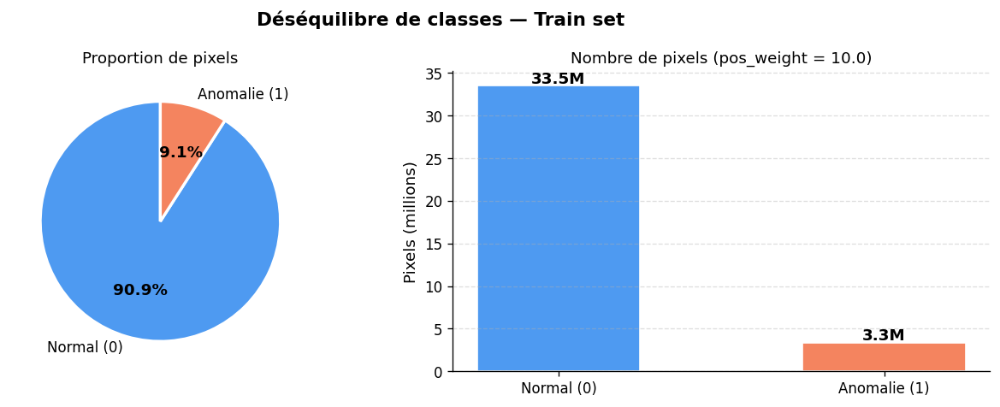


Interprétation : le poids pos_weight=10.0 signifie que
chaque pixel anomalie compte 10.0x plus qu'un pixel normal
dans le calcul de la loss → équilibre l'entraînement.


In [ ]:
# ----------------------------------------------------------------
#  Figure 3 — Visualisation du déséquilibre de classes
# ----------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle('Déséquilibre de classes — Train set', fontsize=13, fontweight='bold')

# Camembert
labels_pie = ['Normal (0)', 'Anomalie (1)']
values_pie = [total_normal, total_anomaly]
colors_pie = ['#4E9AF1', '#F4845F']
wedges, texts, autotexts = axes[0].pie(
    values_pie, labels=labels_pie, colors=colors_pie,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[0].set_title('Proportion de pixels', fontsize=11)

# Barplot avec pos_weight
bars = axes[1].bar(
    labels_pie,
    [total_normal / 1e6, total_anomaly / 1e6],
    color=colors_pie, edgecolor='white', width=0.5
)
for bar, val in zip(bars, [total_normal, total_anomaly]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{val/1e6:.1f}M',
        ha='center', fontsize=11, fontweight='bold'
    )
axes[1].set_ylabel('Pixels (millions)', fontsize=11)
axes[1].set_title(f'Nombre de pixels (pos_weight = {pos_weight_value:.1f})', fontsize=11)
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f'\nInterprétation : le poids pos_weight={pos_weight_value:.1f} signifie que')
print(f'chaque pixel anomalie compte {pos_weight_value:.1f}x plus qu\'un pixel normal')
print(f'dans le calcul de la loss → équilibre l\'entraînement.')

---
## 8. Récapitulatif — Variables exportées pour la Partie 3

Les éléments suivants seront réutilisés en Partie 3 (modèles) :

In [ ]:
print('=' * 60)
print('   RÉCAPITULATIF — PARTIE 2 : DATALOADER')
print('=' * 60)
print(f"""
📦 DATASETS
   train_dataset : {len(train_dataset)} images  (augmentation ON)
   val_dataset   : {len(val_dataset)} images  (augmentation OFF)
   test_dataset  : {len(test_dataset)} images  (augmentation OFF)

🔄 DATALOADERS
   train_loader  : batch_size={BATCH_SIZE}, shuffle=True
   val_loader    : batch_size={BATCH_SIZE}, shuffle=False
   test_loader   : batch_size={BATCH_SIZE}, shuffle=False

📐 FORMAT DES TENSEURS
   Image  : FloatTensor [B, 3, {IMG_HEIGHT}, {IMG_WIDTH}]  — normalisé ImageNet
   Masque : FloatTensor [B, 1, {IMG_HEIGHT}, {IMG_WIDTH}]  — 0.0/1.0 binaire

⚖️  GESTION DU DÉSÉQUILIBRE
   pos_weight = {pos_weight_value:.2f}
   Utilisation : criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)

🔧 AUGMENTATIONS (train uniquement)
   • Flip horizontal (p=0.5)
   • Rotation ±10° (p=0.5)
   • ColorJitter brightness/contrast/saturation (p=0.5)
   • GaussianBlur léger (p=0.3)

🔜 PROCHAINES ÉTAPES (Partie 3)
   • Implémenter U-Net (segmentation supervisée)
   • Implémenter ResNet50-based encoder-decoder
   • Implémenter Autoencoder (approche non-supervisée)
   • Entraînement avec BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
""")
print('=' * 60)

   RÉCAPITULATIF — PARTIE 2 : DATALOADER

📦 DATASETS
   train_dataset : 40 images  (augmentation ON)
   val_dataset   : 9 images  (augmentation OFF)
   test_dataset  : 11 images  (augmentation OFF)

🔄 DATALOADERS
   train_loader  : batch_size=8, shuffle=True
   val_loader    : batch_size=8, shuffle=False
   test_loader   : batch_size=8, shuffle=False

📐 FORMAT DES TENSEURS
   Image  : FloatTensor [B, 3, 256, 512]  — normalisé ImageNet
   Masque : FloatTensor [B, 1, 256, 512]  — 0.0/1.0 binaire

⚖️  GESTION DU DÉSÉQUILIBRE
   pos_weight = 10.04
   Utilisation : criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)

🔧 AUGMENTATIONS (train uniquement)
   • Flip horizontal (p=0.5)
   • Rotation ±10° (p=0.5)
   • ColorJitter brightness/contrast/saturation (p=0.5)
   • GaussianBlur léger (p=0.3)

🔜 PROCHAINES ÉTAPES (Partie 3)
   • Implémenter U-Net (segmentation supervisée)
   • Implémenter ResNet50-based encoder-decoder
   • Implémenter Autoencoder (approche non-supervisée)
   • Entraîne

---
*Notebook réalisé dans le cadre du module Deep Learning — Détection d'anomalies routières — RoadAnomaly dataset (Lis et al., ICCV 2019)*

---
# PARTIES 3, 4 ET 5 — Modèles, Évaluation, Analyse
*(cette section reprend le chargement des données de façon autonome : elle redéfinit `RoadAnomalyDataset` pour qu'il renvoie des images dans [0, 1], ce qu'exige Mask R-CNN)*

# Parties 3, 4 et 5 — Modèles, Évaluation, Analyse (version corrigée et unifiée)
## Détection d'anomalies routières — RoadAnomaly

Ce notebook **remplace** les anciennes Parties 3, 4 et 5. Il est autonome : il recharge le dataset, entraîne, évalue et analyse les trois modèles.

### Les 3 modèles (3 familles différentes)

| # | Modèle | Famille | Supervision | Idée |
|---|--------|---------|-------------|------|
| 1 | **U-Net** | CNN encodeur-décodeur (segmentation dense) | Supervisé (masques pixel) | Prédit directement une carte d'anomalie par pixel |
| 2 | **Autoencodeur convolutionnel** | Modèle génératif / reconstruction | **Non supervisé** (n'utilise pas les masques pour apprendre) | Une anomalie se reconstruit mal → l'erreur de reconstruction est le score |
| 3 | **Mask R-CNN** | Détecteur à **deux étapes** basé sur des régions (RPN + RoIAlign + têtes boîte/masque) | Supervisé (instances) | Détecte chaque objet anormal puis prédit son masque |

> **Honnêteté technique :** Mask R-CNN utilise un backbone convolutionnel (ResNet50-FPN), mais son pipeline (propositions de régions, classification, masque par instance) est une famille d'architecture distincte d'un réseau de segmentation dense comme U-Net. Ce n'est pas un RNN ni un Transformer. Si ton enseignant exige un RNN ou un Transformer, remplace seulement la classe du 3e modèle (voir la section « Pour changer de modèle »).

### Ce qui est corrigé par rapport aux anciennes parties
1. **Chargement des données** : les anciennes Parties 4/5 cherchaient `semantic.png` dans un mauvais dossier. Ici : `frames/<nom>.labels/labels_semantic.png`, comme en Partie 2.
2. **Un seul pipeline de données** pour les 3 modèles (plus de code recopié avec de petites différences).
3. **Autoencodeur** : le score d'anomalie est normalisé **globalement** (calibré sur la validation) et non image par image. La normalisation par image force chaque image à contenir une anomalie, ce qui fausse l'évaluation.
4. **Seuil de décision** choisi sur la **validation** pour chaque modèle (pas 0,5 imposé), puis appliqué une seule fois sur le test.
5. **Split stratifié** garantissant au moins 1 image de chaque catégorie en test.
6. **Analyse automatique** : les conclusions affichées sont calculées à partir des vrais résultats, pas écrites à l'avance.

---
## 0. Configuration des Parties 3-5

Aucun réglage à modifier : tout est configuré dans la **cellule de configuration en haut du notebook**.

In [ ]:
import os, re, json, time, random, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from PIL import Image
from scipy import ndimage as ndi
from sklearn.metrics import precision_recall_curve, auc

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

warnings.filterwarnings("ignore")

# ------------------------- À ADAPTER -------------------------
# -------------------------------------------------------------

OUT_DIR    = WORK_DIR / "outputs_345";  OUT_DIR.mkdir(exist_ok=True, parents=True)
MODELS_DIR = OUT_DIR / "weights";    MODELS_DIR.mkdir(exist_ok=True)

IMG_H, IMG_W = 256, 512          # multiples de 16 (nécessaire pour le U-Net)
SEED   = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS = {"unet": 40, "ae": 40, "maskrcnn": 15}
BATCH  = {"unet": 4,  "ae": 4,  "maskrcnn": 2}
if QUICK_TEST:
    EPOCHS = {k: 1 for k in EPOCHS}

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()

assert FRAMES_DIR.exists(), f"Dossier introuvable : {FRAMES_DIR.resolve()}"
print("Device     :", DEVICE)
print("Dataset    :", DATASET_ROOT.resolve())
print("Époques    :", EPOCHS)

Device     : cuda
Dataset    : /content/RoadAnomaly_data/RoadAnomaly
Époques    : {'unet': 40, 'ae': 40, 'maskrcnn': 15}


---
## 1. Données (identique à la Partie 2, avec corrections)

* Chaque image `X.webp` a un dossier `X.labels/` contenant `labels_semantic.png`.
* Binarisation : pixel de valeur **2** = anomalie (1), le reste = normal (0).
* Les images sont **redimensionnées en 256 × 512** (bilinéaire) et les masques avec **NEAREST** (pas de valeurs intermédiaires).
* Les images restent dans **[0, 1]**. La normalisation ImageNet est faite *à l'intérieur* des modèles qui en ont besoin : Mask R-CNN normalise tout seul, le U-Net le fait dans son `forward`, l'autoencodeur travaille directement sur [0, 1].

In [ ]:
def collect_samples(frames_dir):
    samples = []
    for item in sorted(frames_dir.iterdir()):
        if item.suffix != ".webp":
            continue
        name = item.stem
        labels_dir = frames_dir / (name + ".labels")
        m = re.match(r"([a-z]+)", name)
        if not m:
            continue
        cat = m.group(1)
        if cat == "lost":
            cat = "lost_tires"
        if (labels_dir / "labels_semantic.png").exists():
            samples.append({"name": name, "image_path": item, "labels_dir": labels_dir, "category": cat})
    return samples


def stratified_split(samples, train_r=0.70, val_r=0.15, seed=SEED):
    """Au moins 1 image par catégorie en val ET en test quand la catégorie a >= 3 images."""
    rng = random.Random(seed)
    by_cat = defaultdict(list)
    for s in samples:
        by_cat[s["category"]].append(s)
    tr, va, te = [], [], []
    for cat, items in sorted(by_cat.items()):
        items = list(items); rng.shuffle(items)
        n = len(items)
        if n >= 3:
            n_va = max(1, round(n * val_r)); n_te = max(1, round(n * (1 - train_r - val_r)))
        else:
            n_va, n_te = 0, 0
        n_tr = n - n_va - n_te
        tr += items[:n_tr]; va += items[n_tr:n_tr + n_va]; te += items[n_tr + n_va:]
    return tr, va, te


all_samples = collect_samples(FRAMES_DIR)
train_s, val_s, test_s = stratified_split(all_samples)
print(f"Total {len(all_samples)} | Train {len(train_s)} | Val {len(val_s)} | Test {len(test_s)}\n")
cats = sorted({s["category"] for s in all_samples})
print(f"{'Catégorie':<12}{'Total':>6}{'Train':>7}{'Val':>5}{'Test':>6}")
for c in cats:
    f = lambda L: sum(s["category"] == c for s in L)
    print(f"{c:<12}{f(all_samples):>6}{f(train_s):>7}{f(val_s):>5}{f(test_s):>6}")
assert len(all_samples) > 0, "Aucun échantillon trouvé : vérifie DATASET_ROOT"

Total 60 | Train 40 | Val 10 | Test 10

Catégorie    Total  Train  Val  Test
animals         31     21    5     5
cones            8      6    1     1
lost_tires       3      1    1     1
obstacles       15     11    2     2
vehicle          3      1    1     1


Pixels anomalie (train) : 9.44%  ->  pos_weight = 9.60


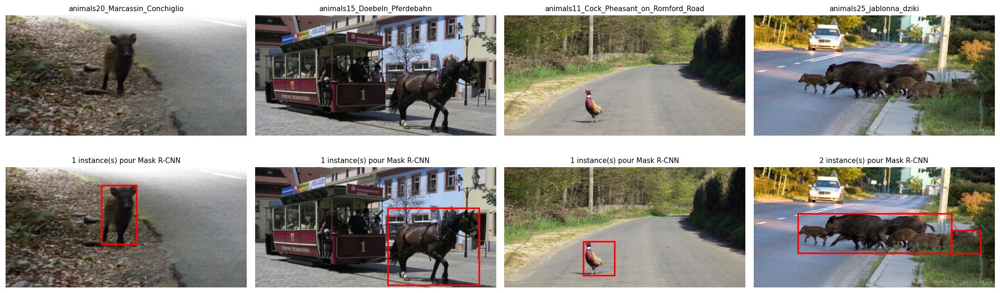

In [ ]:
class RoadAnomalyDataset(Dataset):
    """Retourne (image [3,H,W] dans [0,1], masque [1,H,W] binaire, index)."""
    def __init__(self, samples, augment=False):
        self.samples, self.augment = samples, augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        img = Image.open(s["image_path"]).convert("RGB").resize((IMG_W, IMG_H), Image.BILINEAR)
        sem = np.array(Image.open(s["labels_dir"] / "labels_semantic.png"))
        m = Image.fromarray(((sem == 2) * 255).astype(np.uint8), mode="L").resize((IMG_W, IMG_H), Image.NEAREST)
        x = TF.to_tensor(img)
        y = (TF.to_tensor(m) > 0.5).float()
        if self.augment:
            x, y = self._augment(x, y)
        return x, y, i

    @staticmethod
    def _augment(x, y):
        if random.random() < 0.5:                                   # flip horizontal (image + masque)
            x, y = TF.hflip(x), TF.hflip(y)
        if random.random() < 0.5:                                   # rotation légère (image + masque)
            a = random.uniform(-10, 10)
            x = TF.rotate(x, a, interpolation=InterpolationMode.BILINEAR)
            y = TF.rotate(y, a, interpolation=InterpolationMode.NEAREST)
        if random.random() < 0.5:                                   # couleur (image seulement)
            x = TF.adjust_brightness(x, random.uniform(0.75, 1.25))
            x = TF.adjust_contrast(x, random.uniform(0.75, 1.25)).clamp(0, 1)
        return x, y


def mask_to_target(y, min_area=30):
    """Masque binaire [1,H,W] -> cible Mask R-CNN (une instance par composante connexe)."""
    m = y[0].numpy() > 0.5
    lab, _ = ndi.label(m, structure=np.ones((3, 3)))
    boxes, masks = [], []
    for k, sl in enumerate(ndi.find_objects(lab), start=1):
        inst = lab == k
        if sl is None or inst.sum() < min_area:
            continue
        ys, xs = sl
        boxes.append([xs.start, ys.start, xs.stop, ys.stop]); masks.append(inst)
    if boxes:
        return {"boxes": torch.tensor(boxes, dtype=torch.float32),
                "labels": torch.ones(len(boxes), dtype=torch.int64),
                "masks": torch.from_numpy(np.stack(masks)).to(torch.uint8)}
    return {"boxes": torch.zeros((0, 4), dtype=torch.float32),
            "labels": torch.zeros((0,), dtype=torch.int64),
            "masks": torch.zeros((0, IMG_H, IMG_W), dtype=torch.uint8)}


class MaskRCNNDataset(Dataset):
    """Même données, mais la cible est un dict d'instances (boîtes, labels, masques)."""
    def __init__(self, samples, augment=False):
        self.base = RoadAnomalyDataset(samples, augment)
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        x, y, _ = self.base[i]
        return x, mask_to_target(y)


def det_collate(batch):
    return tuple(zip(*batch))


# --- Poids de classe pour la BCE (déséquilibre ~10:1) ---
tot_n = tot_a = 0
for x, y, _ in DataLoader(RoadAnomalyDataset(train_s), batch_size=8):
    tot_a += y.sum().item(); tot_n += (1 - y).sum().item()
pos_weight_value = tot_n / max(tot_a, 1)
POS_WEIGHT = torch.tensor([pos_weight_value], device=DEVICE)
print(f"Pixels anomalie (train) : {100 * tot_a / (tot_a + tot_n):.2f}%  ->  pos_weight = {pos_weight_value:.2f}")

# --- DataLoaders ---
g = torch.Generator().manual_seed(SEED)
dl_seg_train = DataLoader(RoadAnomalyDataset(train_s, augment=True), batch_size=BATCH["unet"], shuffle=True, generator=g, drop_last=len(train_s) > BATCH["unet"])
dl_seg_val   = DataLoader(RoadAnomalyDataset(val_s),   batch_size=BATCH["unet"])
dl_det_train = DataLoader(MaskRCNNDataset(train_s, augment=True), batch_size=BATCH["maskrcnn"], shuffle=True, collate_fn=det_collate, generator=g)
dl_det_val   = DataLoader(MaskRCNNDataset(val_s),   batch_size=BATCH["maskrcnn"], collate_fn=det_collate)

# Contrôle visuel : image, masque, instances extraites pour Mask R-CNN
ds_chk = MaskRCNNDataset(train_s[:4])
fig, ax = plt.subplots(2, 4, figsize=(18, 6), squeeze=False)
for j in range(min(4, len(ds_chk))):
    x, t = ds_chk[j]
    ax[0, j].imshow(x.permute(1, 2, 0)); ax[0, j].set_title(train_s[j]["name"], fontsize=9); ax[0, j].axis("off")
    ax[1, j].imshow(x.permute(1, 2, 0))
    for b in t["boxes"]:
        ax[1, j].add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2))
    ax[1, j].set_title(f"{len(t['boxes'])} instance(s) pour Mask R-CNN", fontsize=9); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig0_data_check.png", dpi=120); plt.show()

---
# PARTIE 3 — Les trois modèles

## 3.1 U-Net (CNN supervisé, from scratch)
Encodeur qui réduit la résolution (4 niveaux) → goulot d'étranglement → décodeur qui la restaure, avec des **skip connections** qui réinjectent les détails fins. Sortie : 1 canal de *logits* (une probabilité d'anomalie par pixel après sigmoïde).
Version allégée (32 canaux de base) pour rester entraînable sur 42 images.

## 3.2 Autoencodeur convolutionnel (non supervisé)
Il apprend à **reconstruire l'image**. Le goulot est volontairement étroit (pas de skip connections) : il apprend surtout l'apparence « normale » d'une route. À l'inférence, les zones mal reconstruites (objet inhabituel) ont une forte erreur → **score d'anomalie = erreur absolue de reconstruction, lissée**. Les masques ne servent jamais à l'entraînement (seulement à évaluer).

## 3.3 Mask R-CNN (détecteur à deux étapes)
ResNet50-FPN pré-entraîné COCO → **RPN** propose des régions → **RoIAlign** → têtes de classification/boîte et de **masque**. On remplace les têtes par des têtes à 2 classes (fond / anomalie). Les instances d'entraînement viennent des composantes connexes du masque. Pour comparer aux autres modèles, on fusionne les instances prédites en une carte par pixel : `max(score × masque)`.

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.b(x)


class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.e1, self.e2, self.e3, self.e4 = DoubleConv(3, c[0]), DoubleConv(c[0], c[1]), DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)
        self.bott = DoubleConv(c[3], c[4])
        self.u4, self.d4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), DoubleConv(c[4], c[3])
        self.u3, self.d3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), DoubleConv(c[3], c[2])
        self.u2, self.d2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), DoubleConv(c[2], c[1])
        self.u1, self.d1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), DoubleConv(c[1], c[0])
        self.out = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        x = (x - self.mean) / self.std
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bott(self.pool(e4))
        d = self.d4(torch.cat([self.u4(b), e4], 1))
        d = self.d3(torch.cat([self.u3(d), e3], 1))
        d = self.d2(torch.cat([self.u2(d), e2], 1))
        d = self.d1(torch.cat([self.u1(d), e1], 1))
        return self.out(d)                      # logits [B,1,H,W]


class ConvAutoencoder(nn.Module):
    """Entrée/sortie dans [0,1]. Pas de skip connection : le goulot force l'apprentissage du « normal »."""
    def __init__(self, code_ch=64):
        super().__init__()
        def down(i, o): return nn.Sequential(nn.Conv2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        def up(i, o):   return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), down(128, 256), nn.Conv2d(256, code_ch, 1))
        self.dec = nn.Sequential(nn.Conv2d(code_ch, 256, 1), up(256, 128), up(128, 64), up(64, 32),
                                 nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, x):
        return self.dec(self.enc(x))

    @torch.no_grad()
    def anomaly_score(self, x):
        err = (x - self(x)).abs().mean(1, keepdim=True)
        return F.avg_pool2d(err, 7, 1, 3)       # lissage spatial -> [B,1,H,W]


def build_maskrcnn(pretrained=True):
    kw = dict(min_size=IMG_H, max_size=IMG_W, box_score_thresh=0.05, box_detections_per_img=20)
    model = None
    if pretrained:
        try:
            model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT, **kw)
            print("Mask R-CNN : poids COCO chargés.")
        except Exception as e:
            print("Poids COCO indisponibles (", type(e).__name__, ") -> initialisation aléatoire.")
    if model is None:
        model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None, **kw)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, 2)
    in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, 2)
    return model


def n_params(m): return sum(p.numel() for p in m.parameters())

unet  = UNet().to(DEVICE)
ae    = ConvAutoencoder().to(DEVICE)
mrcnn = build_maskrcnn(USE_PRETRAINED_MASKRCNN).to(DEVICE)
print(f"U-Net        : {n_params(unet) / 1e6:6.2f} M paramètres")
print(f"Autoencodeur : {n_params(ae) / 1e6:6.2f} M paramètres")
print(f"Mask R-CNN   : {n_params(mrcnn) / 1e6:6.2f} M paramètres")
with torch.no_grad():
    xt = torch.rand(2, 3, IMG_H, IMG_W, device=DEVICE)
    print("Formes  U-Net:", tuple(unet.eval()(xt).shape), "| AE:", tuple(ae.eval()(xt).shape))

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 183MB/s]


Mask R-CNN : poids COCO chargés.
U-Net        :   7.76 M paramètres
Autoencodeur :   1.41 M paramètres
Mask R-CNN   :  43.92 M paramètres
Formes  U-Net: (2, 1, 256, 512) | AE: (2, 3, 256, 512)


## 3.4 Entraînement

Une seule fonction `fit` entraîne les trois modèles ; seule la façon de calculer la perte change (`step_fn`).

| Modèle | Perte | Optimiseur |
|--------|-------|-----------|
| U-Net | `BCEWithLogits(pos_weight)` + perte Dice | Adam 1e-3 |
| Autoencodeur | MSE de reconstruction (**sans masques**) | Adam 1e-3 |
| Mask R-CNN | somme des 5 pertes internes (RPN, boîte, masque…) | SGD 5e-3, momentum 0,9 |

On garde le **meilleur modèle selon la perte de validation** (sauvegardé dans `outputs_345/weights/`).

In [ ]:
def dice_loss(logits, y, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * y).sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + eps)).mean()

def step_unet(model, batch):
    x, y, _ = batch; x, y = x.to(DEVICE), y.to(DEVICE)
    logits = model(x)
    return F.binary_cross_entropy_with_logits(logits, y, pos_weight=POS_WEIGHT) + dice_loss(logits, y)

def step_ae(model, batch):
    x = batch[0].to(DEVICE)
    return F.mse_loss(model(x), x)                      # aucun masque utilisé

def step_maskrcnn(model, batch):
    imgs, targets = batch
    imgs = [i.to(DEVICE) for i in imgs]
    targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
    return sum(model(imgs, targets).values())


def fit(model, name, step_fn, dl_train, dl_val, epochs, optimizer, patience=12, val_train_mode=False):
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)
    hist, best, bad = {"train": [], "val": []}, float("inf"), 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tr = []
        for batch in dl_train:
            optimizer.zero_grad()
            loss = step_fn(model, batch); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step(); tr.append(loss.item())
        model.train() if val_train_mode else model.eval()     # Mask R-CNN ne renvoie ses pertes qu'en mode train (BN gelées -> sans effet)
        va = []
        with torch.no_grad():
            for batch in dl_val:
                va.append(step_fn(model, batch).item())
        tr_m, va_m = float(np.mean(tr)), float(np.mean(va))
        hist["train"].append(tr_m); hist["val"].append(va_m); sched.step(va_m)
        flag = ""
        if va_m < best:
            best, bad = va_m, 0
            torch.save(model.state_dict(), MODELS_DIR / f"best_{name}.pth"); flag = "  <- meilleur"
        else:
            bad += 1
        print(f"[{name}] epoch {ep:3d}/{epochs}  train={tr_m:.4f}  val={va_m:.4f}{flag}")
        if bad >= patience:
            print(f"[{name}] arrêt anticipé (patience {patience})"); break
    model.load_state_dict(torch.load(MODELS_DIR / f"best_{name}.pth", map_location=DEVICE))
    model.eval()
    hist["time_s"] = time.time() - t0
    print(f"[{name}] terminé en {hist['time_s'] / 60:.1f} min, meilleure val = {best:.4f}\n")
    return hist

HISTORY = {}

In [ ]:
set_seed()
HISTORY["U-Net"] = fit(unet, "unet", step_unet, dl_seg_train, dl_seg_val, EPOCHS["unet"],
                       torch.optim.Adam(unet.parameters(), lr=1e-3))

[unet] epoch   1/40  train=1.9930  val=1.9774  <- meilleur
[unet] epoch   2/40  train=1.8556  val=1.7792  <- meilleur
[unet] epoch   3/40  train=1.7928  val=1.8584
[unet] epoch   4/40  train=1.8203  val=1.5992  <- meilleur
[unet] epoch   5/40  train=1.7290  val=4.0393
[unet] epoch   6/40  train=1.7018  val=2.5085
[unet] epoch   7/40  train=1.6474  val=2.5032
[unet] epoch   8/40  train=1.7866  val=5.3904
[unet] epoch   9/40  train=1.6482  val=2.5427
[unet] epoch  10/40  train=1.5905  val=1.5469  <- meilleur
[unet] epoch  11/40  train=1.5532  val=1.5938
[unet] epoch  12/40  train=1.4925  val=1.8572
[unet] epoch  13/40  train=1.4651  val=1.8428
[unet] epoch  14/40  train=1.5413  val=1.9781
[unet] epoch  15/40  train=1.4298  val=1.8750
[unet] epoch  16/40  train=1.3712  val=1.5669
[unet] epoch  17/40  train=1.4230  val=1.6605
[unet] epoch  18/40  train=1.3546  val=1.7325
[unet] epoch  19/40  train=1.3610  val=1.7463
[unet] epoch  20/40  train=1.3149  val=1.7205
[unet] epoch  21/40  train=1

In [ ]:
set_seed()
dl_ae_train = DataLoader(RoadAnomalyDataset(train_s, augment=True), batch_size=BATCH["ae"], shuffle=True, drop_last=len(train_s) > BATCH["ae"])
HISTORY["Autoencoder"] = fit(ae, "ae", step_ae, dl_ae_train, dl_seg_val, EPOCHS["ae"],
                             torch.optim.Adam(ae.parameters(), lr=1e-3))

[ae] epoch   1/40  train=0.0526  val=0.0416  <- meilleur
[ae] epoch   2/40  train=0.0302  val=0.0226  <- meilleur
[ae] epoch   3/40  train=0.0169  val=0.0135  <- meilleur
[ae] epoch   4/40  train=0.0158  val=0.0133  <- meilleur
[ae] epoch   5/40  train=0.0189  val=0.0130  <- meilleur
[ae] epoch   6/40  train=0.0146  val=0.0120  <- meilleur
[ae] epoch   7/40  train=0.0145  val=0.0111  <- meilleur
[ae] epoch   8/40  train=0.0137  val=0.0105  <- meilleur
[ae] epoch   9/40  train=0.0156  val=0.0153
[ae] epoch  10/40  train=0.0148  val=0.0108
[ae] epoch  11/40  train=0.0142  val=0.0107
[ae] epoch  12/40  train=0.0150  val=0.0110
[ae] epoch  13/40  train=0.0132  val=0.0112
[ae] epoch  14/40  train=0.0121  val=0.0096  <- meilleur
[ae] epoch  15/40  train=0.0119  val=0.0089  <- meilleur
[ae] epoch  16/40  train=0.0132  val=0.0091
[ae] epoch  17/40  train=0.0127  val=0.0087  <- meilleur
[ae] epoch  18/40  train=0.0107  val=0.0086  <- meilleur
[ae] epoch  19/40  train=0.0112  val=0.0089
[ae] epo

In [ ]:
set_seed()
params = [p for p in mrcnn.parameters() if p.requires_grad]
HISTORY["Mask R-CNN"] = fit(mrcnn, "maskrcnn", step_maskrcnn, dl_det_train, dl_det_val, EPOCHS["maskrcnn"],
                            torch.optim.SGD(params, lr=5e-3, momentum=0.9, weight_decay=5e-4),
                            patience=8, val_train_mode=True)

[maskrcnn] epoch   1/15  train=1.3717  val=0.9371  <- meilleur
[maskrcnn] epoch   2/15  train=0.5865  val=1.0101
[maskrcnn] epoch   3/15  train=0.4806  val=0.7452  <- meilleur
[maskrcnn] epoch   4/15  train=0.4404  val=0.8918
[maskrcnn] epoch   5/15  train=0.3765  val=0.8473
[maskrcnn] epoch   6/15  train=0.3419  val=0.9366
[maskrcnn] epoch   7/15  train=0.3358  val=0.7575
[maskrcnn] epoch   8/15  train=0.3126  val=0.9788
[maskrcnn] epoch   9/15  train=0.3100  val=0.8940
[maskrcnn] epoch  10/15  train=0.2776  val=0.7947
[maskrcnn] epoch  11/15  train=0.2611  val=0.9081
[maskrcnn] arrêt anticipé (patience 8)
[maskrcnn] terminé en 1.2 min, meilleure val = 0.7452



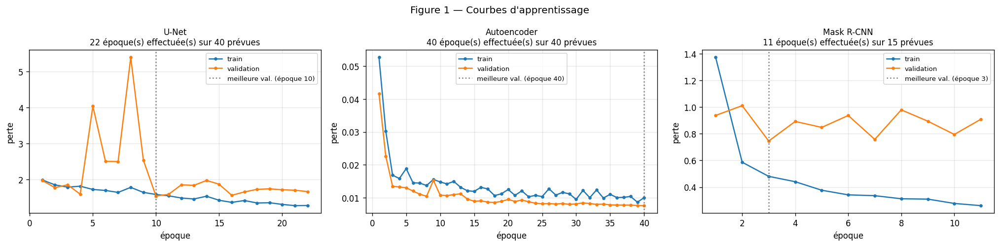

Époques effectuées :
  U-Net         22 / 40  (arrêt anticipé : la validation ne s'améliorait plus)
  Autoencoder   40 / 40
  Mask R-CNN    11 / 15  (arrêt anticipé : la validation ne s'améliorait plus)


In [ ]:
# Courbes d'apprentissage + vérification du nombre d'époques réellement effectuées
EP_KEY = {"U-Net": "unet", "Autoencoder": "ae", "Mask R-CNN": "maskrcnn"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), squeeze=False)
for a, (name, h) in zip(ax[0], HISTORY.items()):
    ep = np.arange(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", ms=3, label="train"); a.plot(ep, h["val"], "o-", ms=3, label="validation")
    best_ep = int(np.argmin(h["val"])) + 1
    a.axvline(best_ep, ls=":", c="gray", label=f"meilleure val. (époque {best_ep})")
    a.set_title(f"{name}\n{len(ep)} époque(s) effectuée(s) sur {EPOCHS[EP_KEY[name]]} prévues", fontsize=10)
    a.set_xlabel("époque"); a.set_ylabel("perte"); a.legend(fontsize=8); a.grid(alpha=.3)
fig.suptitle("Figure 1 — Courbes d'apprentissage"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig1_learning_curves.png", dpi=130); plt.show()

print("Époques effectuées :")
for name, h in HISTORY.items():
    done, plan = len(h["train"]), EPOCHS[EP_KEY[name]]
    note = "" if done == plan else "  (arrêt anticipé : la validation ne s'améliorait plus)" if done > 1 else ""
    print(f"  {name:<12} {done:>3} / {plan}{note}")
if QUICK_TEST:
    print("\nATTENTION : test rapide (1 époque) -> les courbes sont réduites à un point.")

---
# PARTIE 4 — Évaluation

## 4.1 Une carte de probabilité par modèle
Pour comparer des familles très différentes, chacune est ramenée à la **même sortie** : une carte `P[i, y, x] ∈ [0, 1]` (« probabilité d'anomalie » du pixel).

* **U-Net** : `sigmoid(logits)`.
* **Autoencodeur** : score d'erreur divisé par une constante `AE_SCALE` (99,9e percentile des scores de validation), puis tronqué à [0, 1]. La constante est **globale**, pas par image.
* **Mask R-CNN** : `max` sur les instances détectées de `score × masque`. Aucune détection → carte nulle.

## 4.2 Métriques (par image, puis moyenne)
Avec TP/FP/FN calculés pixel par pixel :
`IoU = TP / (TP+FP+FN)` · `Dice = 2TP / (2TP+FP+FN)` · `Précision = TP/(TP+FP)` · `Rappel = TP/(TP+FN)` · `F1`.
L'*accuracy* n'est **pas** utilisée : prédire « normal » partout donnerait ≈ 90 %.

## 4.3 Seuil de décision
Le seuil qui transforme `P` en masque binaire est choisi **sur la validation** (maximise l'IoU moyen), séparément pour chaque modèle, puis appliqué tel quel sur le test.

In [ ]:
@torch.no_grad()
def predict_probs(name, samples, ae_scale=1.0):
    """Retourne P [N,H,W] float32, G [N,H,W] uint8, temps moyen d'inférence par image (s)."""
    ds = RoadAnomalyDataset(samples)
    model = {"unet": unet, "ae": ae, "maskrcnn": mrcnn}[name].eval()
    P, G, t_tot = [], [], 0.0
    for i in range(len(ds)):
        x, y, _ = ds[i]
        xb = x.unsqueeze(0).to(DEVICE)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        if name == "unet":
            p = torch.sigmoid(model(xb))[0, 0]
        elif name == "ae":
            p = (model.anomaly_score(xb)[0, 0] / ae_scale).clamp(0, 1)
        else:
            out = model([xb[0]])[0]
            if len(out["scores"]):
                p = (out["scores"].view(-1, 1, 1) * out["masks"][:, 0]).max(0).values
            else:
                p = torch.zeros(IMG_H, IMG_W, device=DEVICE)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t_tot += time.time() - t0
        P.append(p.float().cpu().numpy()); G.append(y[0].numpy().astype(np.uint8))
    return np.stack(P), np.stack(G), t_tot / len(ds)


def compute_metrics(pred, gt, eps=1e-7):
    pred, gt = pred.astype(bool), gt.astype(bool)
    TP = (pred & gt).sum(); FP = (pred & ~gt).sum(); FN = (~pred & gt).sum()
    iou  = TP / (TP + FP + FN + eps)
    dice = 2 * TP / (2 * TP + FP + FN + eps)
    prec = TP / (TP + FP + eps); rec = TP / (TP + FN + eps)
    f1 = 2 * prec * rec / (prec + rec + eps)
    return {"IoU": float(iou), "Dice": float(dice), "Precision": float(prec), "Recall": float(rec), "F1": float(f1)}


def per_image_metrics(P, G, thr):
    return [compute_metrics(P[i] > thr, G[i]) for i in range(len(P))]


def mean_metrics(rows):
    return {k: float(np.mean([r[k] for r in rows])) for k in rows[0]}


def tune_threshold(P, G, grid=np.arange(0.05, 0.96, 0.05)):
    scores = [np.mean([r["IoU"] for r in per_image_metrics(P, G, t)]) for t in grid]
    return float(grid[int(np.argmax(scores))]), float(max(scores))


# ---- Prédictions validation puis test ----
MODEL_KEYS = {"U-Net": "unet", "Autoencoder": "ae", "Mask R-CNN": "maskrcnn"}

raw_val, _, _ = predict_probs("ae", val_s, ae_scale=1.0)
AE_SCALE = float(np.percentile(raw_val, 99.9)) + 1e-8
print(f"AE_SCALE (calibré sur la validation) = {AE_SCALE:.4f}")

VAL, TEST, THR, INFER_T = {}, {}, {}, {}
for label, key in MODEL_KEYS.items():
    VAL[label]  = predict_probs(key, val_s,  AE_SCALE)[:2]
    TEST[label] = predict_probs(key, test_s, AE_SCALE)[:2]
    INFER_T[label] = predict_probs(key, test_s[:3], AE_SCALE)[2]
    THR[label], v_iou = tune_threshold(*VAL[label])
    print(f"{label:<12} seuil choisi sur la validation = {THR[label]:.2f}  (IoU val = {v_iou:.3f})")

AE_SCALE (calibré sur la validation) = 0.2578
U-Net        seuil choisi sur la validation = 0.75  (IoU val = 0.303)
Autoencoder  seuil choisi sur la validation = 0.20  (IoU val = 0.105)
Mask R-CNN   seuil choisi sur la validation = 0.65  (IoU val = 0.608)


In [ ]:
# ---- Métriques sur le TEST, avec le seuil choisi en validation ----
RES, PER_IMG = {}, {}
for label in MODEL_KEYS:
    P, G = TEST[label]
    PER_IMG[label] = per_image_metrics(P, G, THR[label])
    RES[label] = mean_metrics(PER_IMG[label])

MET = ["IoU", "Dice", "Precision", "Recall", "F1"]
print(f"Ensemble de test : {len(test_s)} images\n")
print(f"{'Modèle':<14}" + "".join(f"{m:>11}" for m in MET) + f"{'seuil':>8}")
print("-" * 80)
for label, r in RES.items():
    print(f"{label:<14}" + "".join(f"{r[m]:>11.4f}" for m in MET) + f"{THR[label]:>8.2f}")

Ensemble de test : 10 images

Modèle                IoU       Dice  Precision     Recall         F1   seuil
--------------------------------------------------------------------------------
U-Net              0.3378     0.4616     0.4303     0.6837     0.4616    0.75
Autoencoder        0.1541     0.2468     0.1684     0.8579     0.2468    0.20
Mask R-CNN         0.5604     0.6662     0.7127     0.7075     0.6662    0.65


### Figure 2 — Comparaison globale

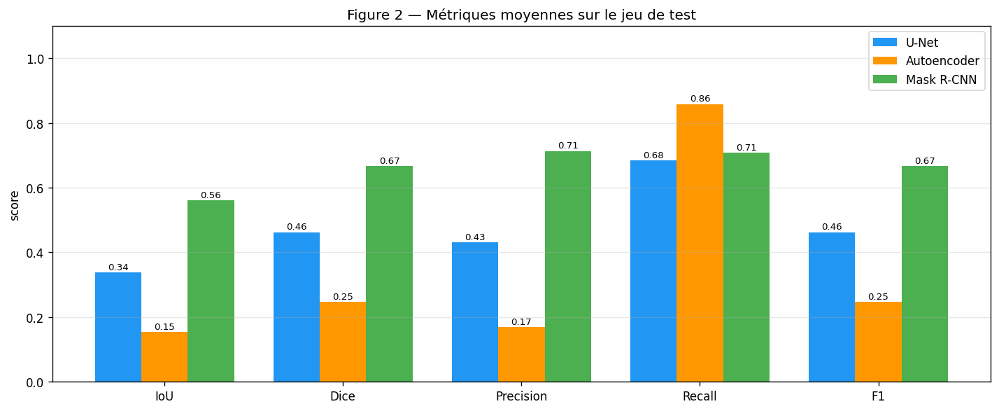

In [ ]:
COL = {"U-Net": "#2196F3", "Autoencoder": "#FF9800", "Mask R-CNN": "#4CAF50"}
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(MET)); w = 0.26
for i, (label, r) in enumerate(RES.items()):
    vals = [r[m] for m in MET]
    bars = ax.bar(x + (i - 1) * w, vals, w, label=label, color=COL[label])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(MET); ax.set_ylim(0, 1.1); ax.set_ylabel("score")
ax.set_title("Figure 2 — Métriques moyennes sur le jeu de test"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig2_metrics.png", dpi=130); plt.show()

### Figure 3 — Courbes Précision-Rappel (indépendantes du seuil)
La courbe PR est adaptée aux classes déséquilibrées. La ligne pointillée est le niveau d'un classifieur aléatoire (= proportion de pixels anomalie).

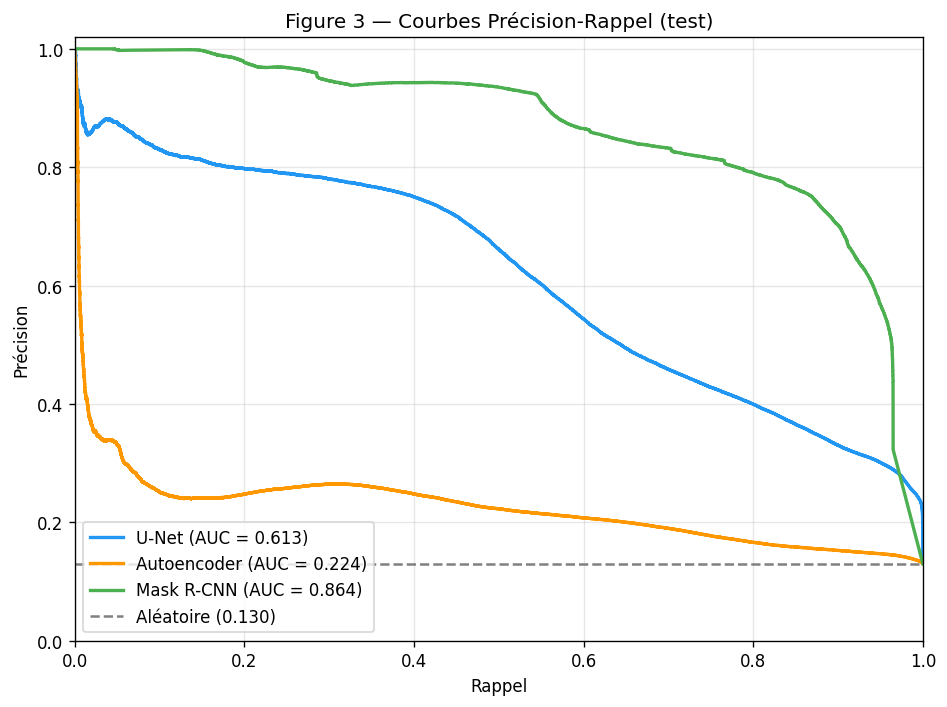

In [ ]:
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(8, 6))
PRAUC = {}
for label in MODEL_KEYS:
    P, G = TEST[label]
    p, g = P.ravel(), G.ravel()
    if len(p) > 600_000:
        idx = rng.choice(len(p), 600_000, replace=False); p, g = p[idx], g[idx]
    pr, rc, _ = precision_recall_curve(g, p)
    PRAUC[label] = float(auc(rc, pr))
    ax.plot(rc, pr, lw=2, color=COL[label], label=f"{label} (AUC = {PRAUC[label]:.3f})")
base = TEST["U-Net"][1].mean()
ax.axhline(base, ls="--", c="gray", label=f"Aléatoire ({base:.3f})")
ax.set_xlabel("Rappel"); ax.set_ylabel("Précision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Figure 3 — Courbes Précision-Rappel (test)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig3_pr_curves.png", dpi=130); plt.show()

### Figure 4 — IoU par catégorie d'anomalie
Attention : chaque catégorie n'a que 1 à quelques images en test, donc ces barres sont **indicatives**.

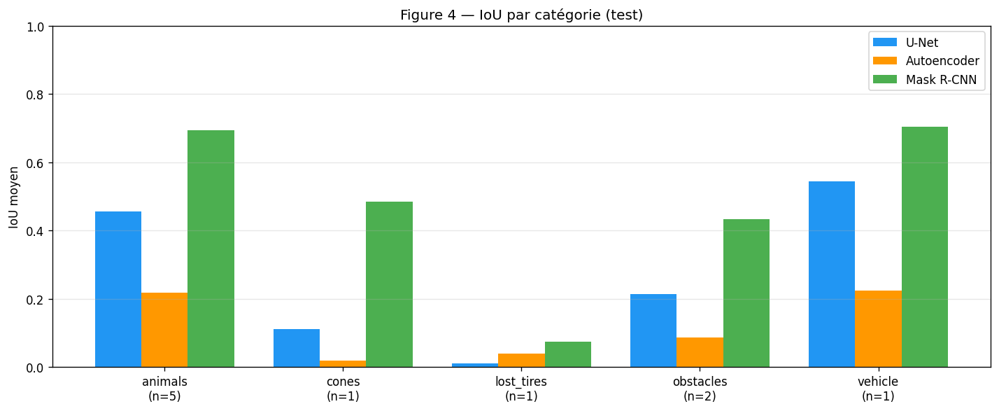

In [ ]:
test_cats = sorted({s["category"] for s in test_s})
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(test_cats)); w = 0.26
CAT_IOU = {}
for i, label in enumerate(MODEL_KEYS):
    vals = []
    for c in test_cats:
        v = [PER_IMG[label][k]["IoU"] for k, s in enumerate(test_s) if s["category"] == c]
        vals.append(float(np.mean(v)))
    CAT_IOU[label] = dict(zip(test_cats, vals))
    ax.bar(x + (i - 1) * w, vals, w, label=label, color=COL[label])
counts = [sum(s["category"] == c for s in test_s) for c in test_cats]
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(test_cats, counts)])
ax.set_ylim(0, 1); ax.set_ylabel("IoU moyen"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Figure 4 — IoU par catégorie (test)")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig4_iou_by_category.png", dpi=130); plt.show()

---
# PARTIE 5 — Analyse

## 5.1 Meilleures et pires prédictions
On classe les images de test par IoU moyen des trois modèles. Les colonnes montrent la prédiction de chaque modèle (rouge) superposée à l'image ; le contour vert est la vérité terrain.

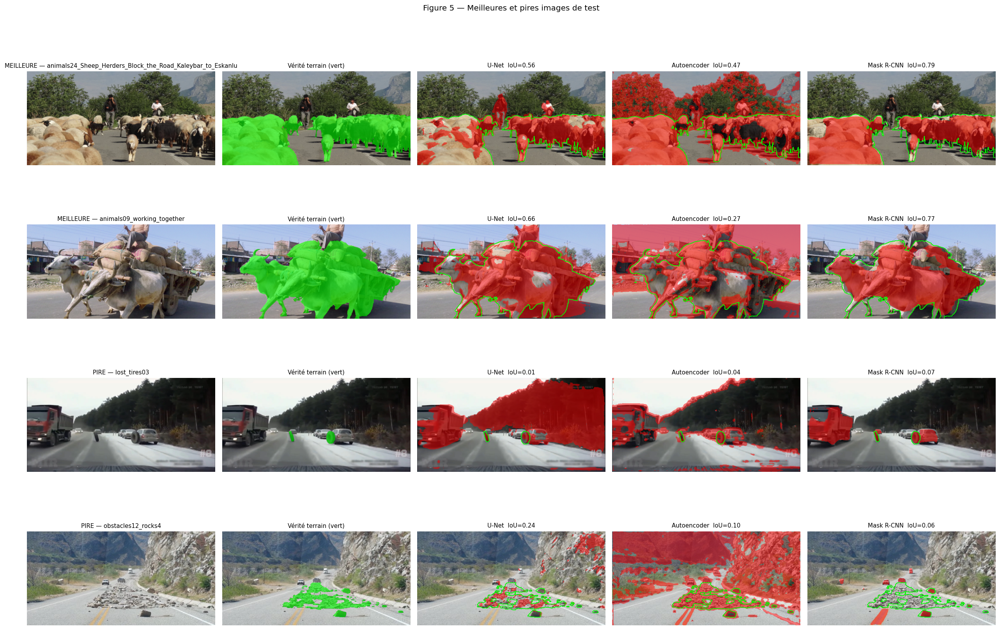

In [ ]:
def overlay(img, mask, color=(1, 0, 0), alpha=0.5):
    out = img.copy(); m = mask.astype(bool)
    for c in range(3):
        out[..., c][m] = out[..., c][m] * (1 - alpha) + color[c] * alpha
    return out

imgs_test = np.stack([RoadAnomalyDataset(test_s)[i][0].permute(1, 2, 0).numpy() for i in range(len(test_s))])
mean_iou_img = np.mean([[PER_IMG[l][i]["IoU"] for i in range(len(test_s))] for l in MODEL_KEYS], axis=0)
order = np.argsort(mean_iou_img)
n_show = min(2, len(test_s) // 2)
chosen = [("MEILLEURE", i) for i in order[::-1][:n_show]] + [("PIRE", i) for i in order[:n_show]]

fig, axes = plt.subplots(len(chosen), 5, figsize=(21, 3.6 * len(chosen)), squeeze=False)
for r, (tag, i) in enumerate(chosen):
    gt = TEST["U-Net"][1][i]
    axes[r, 0].imshow(imgs_test[i]); axes[r, 0].set_title(f"{tag} — {test_s[i]['name']}", fontsize=9)
    axes[r, 1].imshow(overlay(imgs_test[i], gt, (0, 1, 0), 0.6)); axes[r, 1].set_title("Vérité terrain (vert)", fontsize=9)
    for c, label in enumerate(MODEL_KEYS, start=2):
        pred = TEST[label][0][i] > THR[label]
        axes[r, c].imshow(overlay(imgs_test[i], pred))
        axes[r, c].contour(gt, levels=[0.5], colors="lime", linewidths=1)
        axes[r, c].set_title(f"{label}  IoU={PER_IMG[label][i]['IoU']:.2f}", fontsize=9)
    for a in axes[r]: a.axis("off")
fig.suptitle("Figure 5 — Meilleures et pires images de test", y=1.0)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig5_best_worst.png", dpi=110, bbox_inches="tight"); plt.show()

## 5.2 Cartes d'erreur (image médiane)
Noir = vrai négatif · **vert** = vrai positif · **rouge** = faux positif (fausse alarme) · **bleu** = faux négatif (anomalie ratée).

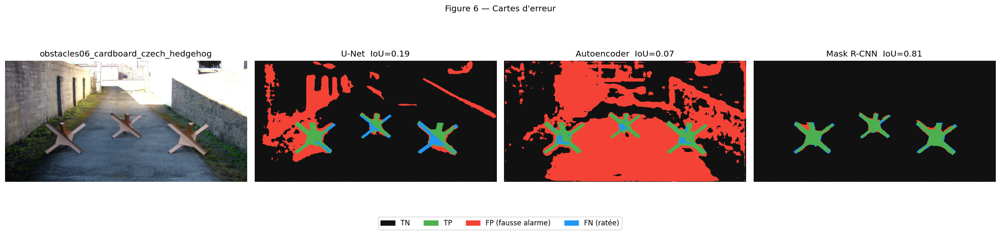

In [ ]:
med = int(order[len(order) // 2])
cm = ListedColormap(["#111111", "#F44336", "#2196F3", "#4CAF50"])   # TN, FP, FN, TP
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), squeeze=False)
axes[0, 0].imshow(imgs_test[med]); axes[0, 0].set_title(test_s[med]["name"]); axes[0, 0].axis("off")
gt = TEST["U-Net"][1][med].astype(bool)
for a, label in zip(axes[0, 1:], MODEL_KEYS):
    pr = TEST[label][0][med] > THR[label]
    e = np.zeros(pr.shape, int); e[pr & ~gt] = 1; e[~pr & gt] = 2; e[pr & gt] = 3
    a.imshow(e, cmap=cm, vmin=0, vmax=3); a.axis("off")
    a.set_title(f"{label}  IoU={PER_IMG[label][med]['IoU']:.2f}")
fig.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
           zip(["#111111", "#4CAF50", "#F44336", "#2196F3"], ["TN", "TP", "FP (fausse alarme)", "FN (ratée)"])],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Figure 6 — Cartes d'erreur"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig6_error_maps.png", dpi=120, bbox_inches="tight"); plt.show()

## 5.3 Distribution des scores et coût de calcul

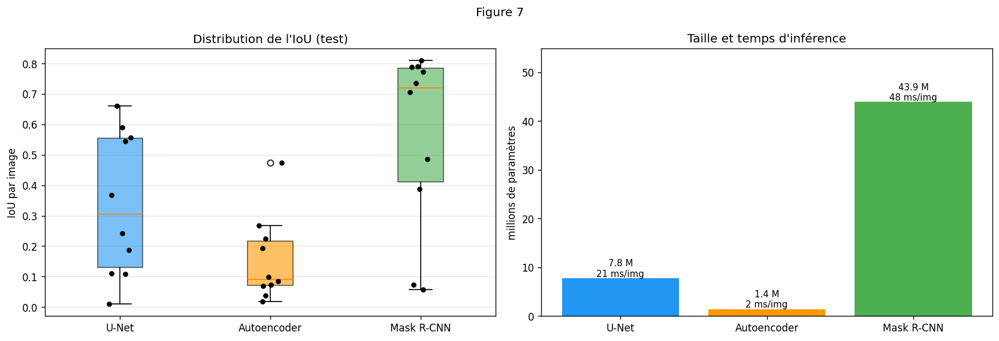

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), squeeze=False)
data = [[r["IoU"] for r in PER_IMG[l]] for l in MODEL_KEYS]
bp = ax[0, 0].boxplot(data, patch_artist=True)
ax[0, 0].set_xticks(range(1, len(MODEL_KEYS) + 1)); ax[0, 0].set_xticklabels(list(MODEL_KEYS))
for patch, l in zip(bp["boxes"], MODEL_KEYS): patch.set_facecolor(COL[l]); patch.set_alpha(.6)
for k, d in enumerate(data, 1):
    ax[0, 0].scatter(np.full(len(d), k) + np.random.uniform(-.08, .08, len(d)), d, c="k", s=18, zorder=3)
ax[0, 0].set_ylabel("IoU par image"); ax[0, 0].set_title("Distribution de l'IoU (test)"); ax[0, 0].grid(axis="y", alpha=.3)

labels = list(MODEL_KEYS)
params_m = [n_params(m) / 1e6 for m in (unet, ae, mrcnn)]
ax[0, 1].bar(labels, params_m, color=[COL[l] for l in labels])
for i, v in enumerate(params_m): ax[0, 1].text(i, v, f"{v:.1f} M\n{INFER_T[labels[i]] * 1000:.0f} ms/img", ha="center", va="bottom", fontsize=9)
ax[0, 1].set_ylabel("millions de paramètres"); ax[0, 1].set_title("Taille et temps d'inférence"); ax[0, 1].set_ylim(0, max(params_m) * 1.25)
fig.suptitle("Figure 7"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig7_distribution_cost.png", dpi=130); plt.show()

## 5.4 Tableau de synthèse et conclusions calculées automatiquement
Le texte ci-dessous est produit à partir de **tes résultats réels** : il change si les résultats changent.

In [ ]:
rank = sorted(RES, key=lambda l: RES[l]["IoU"], reverse=True)
best, worst = rank[0], rank[-1]

print("=" * 108)
print(f"{'Modèle':<14}{'IoU':>8}{'Dice':>8}{'Préc.':>8}{'Rappel':>8}{'F1':>8}{'PR-AUC':>9}{'Seuil':>7}{'Params(M)':>11}{'ms/img':>8}{'Train(min)':>12}")
print("-" * 108)
for l, m in zip(MODEL_KEYS, (unet, ae, mrcnn)):
    r = RES[l]
    print(f"{l:<14}{r['IoU']:>8.3f}{r['Dice']:>8.3f}{r['Precision']:>8.3f}{r['Recall']:>8.3f}{r['F1']:>8.3f}"
          f"{PRAUC[l]:>9.3f}{THR[l]:>7.2f}{n_params(m) / 1e6:>11.1f}{INFER_T[l] * 1000:>8.0f}{HISTORY[l]['time_s'] / 60:>12.1f}")
print("=" * 108)

if QUICK_TEST:
    print("ATTENTION : test rapide (1 époque) -> ces résultats ne sont PAS représentatifs.\n")
print(f"\nClassement par IoU : " + " > ".join(f"{l} ({RES[l]['IoU']:.3f})" for l in rank))
print(f"\n1) Meilleur modèle : {best} (IoU {RES[best]['IoU']:.3f}, F1 {RES[best]['F1']:.3f}, PR-AUC {PRAUC[best]:.3f}).")
gap = RES[best]["IoU"] - RES[rank[1]]["IoU"]
print(f"   Écart avec le 2e ({rank[1]}) : {gap:.3f} d'IoU" + (" -> écart faible, à interpréter avec prudence (seulement %d images de test)." % len(test_s) if gap < 0.05 else "."))

for l in MODEL_KEYS:
    r = RES[l]
    if r["Precision"] > r["Recall"] + 0.1:
        prof = "prudent : peu de fausses alarmes mais rate des anomalies (rappel faible)"
    elif r["Recall"] > r["Precision"] + 0.1:
        prof = "sur-détecte : trouve la plupart des anomalies mais produit des fausses alarmes (précision plus faible)"
    else:
        prof = "équilibré entre précision et rappel"
    print(f"2) {l} : {prof} (P={r['Precision']:.2f}, R={r['Recall']:.2f}).")

print(f"\n3) Pire modèle : {worst}.", end=" ")
if worst == "Autoencoder":
    print("Cohérent : il n'apprend jamais ce qu'est une anomalie, seulement ce qui est mal reconstruit, ce qui inclut aussi les textures complexes et les ombres.")
elif worst == "Mask R-CNN":
    print(f"Avec seulement {len(train_s)} images d'entraînement, la détection d'instances est difficile à entraîner : les têtes sont neuves et les petites anomalies sont souvent manquées.")
else:
    print("Le U-Net est entraîné from scratch sur très peu de données.")

low = [(test_s[i]["name"], mean_iou_img[i]) for i in order[:3]]
print("\n4) Images les plus difficiles (IoU moyen des 3 modèles) : " + ", ".join(f"{n} ({v:.2f})" for n, v in low))
cat_best = {c: max(MODEL_KEYS, key=lambda l: CAT_IOU[l][c]) for c in test_cats}
print("5) Meilleur modèle par catégorie (indicatif) : " + ", ".join(f"{c} -> {m}" for c, m in cat_best.items()))

json.dump({"test_metrics": RES, "pr_auc": PRAUC, "thresholds": THR, "ae_scale": AE_SCALE,
           "n_test": len(test_s), "iou_by_category": CAT_IOU,
           "train_time_s": {l: HISTORY[l]["time_s"] for l in HISTORY}},
          open(OUT_DIR / "results.json", "w"), indent=2)
print(f"\nRésultats enregistrés dans {OUT_DIR / 'results.json'} ; figures dans {OUT_DIR}")

Modèle             IoU    Dice   Préc.  Rappel      F1   PR-AUC  Seuil  Params(M)  ms/img  Train(min)
------------------------------------------------------------------------------------------------------------
U-Net            0.338   0.462   0.430   0.684   0.462    0.613   0.75        7.8      21         1.8
Autoencoder      0.154   0.247   0.168   0.858   0.247    0.224   0.20        1.4       2         1.5
Mask R-CNN       0.560   0.666   0.713   0.707   0.666    0.864   0.65       43.9      48         1.2

Classement par IoU : Mask R-CNN (0.560) > U-Net (0.338) > Autoencoder (0.154)

1) Meilleur modèle : Mask R-CNN (IoU 0.560, F1 0.666, PR-AUC 0.864).
   Écart avec le 2e (U-Net) : 0.223 d'IoU.
2) U-Net : sur-détecte : trouve la plupart des anomalies mais produit des fausses alarmes (précision plus faible) (P=0.43, R=0.68).
2) Autoencoder : sur-détecte : trouve la plupart des anomalies mais produit des fausses alarmes (précision plus faible) (P=0.17, R=0.86).
2) Mask R-CNN : équil

## 5.5 Limites et pistes d'amélioration (à intégrer à ton rapport)

**Limites**
* **60 images, 9 environ en test** : chaque métrique est bruitée ; une seule image peut déplacer la moyenne. Les résultats par catégorie reposent sur 1 à 3 images.
* **Déséquilibre** (~10 % de pixels anomalie) géré par `pos_weight` + Dice, mais les petites anomalies restent difficiles après réduction à 256 × 512.
* **Seuil choisi sur 9 images de validation** : peu stable.
* **Mask R-CNN** : les instances sont déduites des composantes connexes du masque (le dataset n'a pas de vraies boîtes) ; deux objets collés comptent comme un seul.
* **Autoencodeur** : entraîné sur toutes les images d'entraînement, y compris leurs anomalies (sans utiliser les masques) ; un entraînement uniquement sur routes sans anomalie serait plus propre mais le dataset n'en contient pas.

**Pistes**
* Validation croisée à 5 plis pour des chiffres plus stables.
* Davantage de données (FS-LostFound, SMIYC) ou anomalies synthétiques collées sur des scènes normales.
* Test-time augmentation (flip) et ensemble des modèles.
* Autres familles si exigé : SegFormer (Transformer), ReNet/ConvLSTM (RNN).

## Pour changer de modèle
Le 3e modèle est interchangeable : il suffit de fournir (1) une classe de modèle, (2) une fonction `step_xxx` pour la perte, (3) une branche dans `predict_probs` qui retourne une carte [0, 1]. Tout le reste (métriques, seuil, figures, analyse) fonctionne sans modification.

---
# PARTIE 6 — Complément de l'objectif 1 : la segmentation vue *par objet*

**Question posée : combien d'objets anormaux, et où sont-ils ?**

Les Parties 3-5 évaluaient la segmentation **pixel par pixel**. Ici, on regarde la même sortie de **Mask R-CNN** *objet par objet* (boîtes, comptage), ce qui complète l'objectif 1 et fournit les boîtes dont la Partie 7 a besoin pour nommer les objets. On ne regarde plus des pixels mais des **objets** : chaque objet anormal est une instance avec une boîte, un masque et un score de confiance. Le modèle naturel est **Mask R-CNN**, car il détecte d'abord les objets puis segmente chacun.

* **Vérité terrain** : une instance par composante connexe du masque binaire (même règle que pour l'entraînement ; deux objets qui se touchent comptent donc pour un seul).
* **Appariement** : une détection est un *vrai positif* si son masque recouvre une instance de la vérité terrain avec IoU ≥ 0,5 (appariement glouton, par score décroissant).
* **Métriques** : précision, rappel et F1 *au niveau des objets*, AP50 (aire sous la courbe précision-rappel des détections), et erreur absolue moyenne sur le **comptage** d'objets par image.
* **Seuil de score** : choisi sur la **validation** (il maximise le F1), puis appliqué sur le test.

In [ ]:
import torchvision.ops as tv_ops

@torch.no_grad()
def mrcnn_instances(x, score_thr=0.05, mask_thr=0.5):
    """Détections de Mask R-CNN pour une image x [3,H,W] dans [0,1]."""
    out = mrcnn.eval()([x.to(DEVICE)])[0]
    keep = out["scores"] >= score_thr
    return {"boxes": out["boxes"][keep].cpu(), "scores": out["scores"][keep].cpu(),
            "masks": (out["masks"][keep][:, 0] > mask_thr).cpu()}

def mask_iou_matrix(A, B):
    A = A.flatten(1).float(); B = B.flatten(1).float()
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return inter / union.clamp(min=1)

def match_instances(pred, gt_masks, iou_thr=0.5):
    """Appariement glouton par score décroissant. Retourne (paires (i_pred, j_gt), tp[bool] par détection)."""
    n = len(pred["scores"])
    tp = torch.zeros(n, dtype=torch.bool); pairs = []
    if n == 0 or len(gt_masks) == 0:
        return pairs, tp
    ious = mask_iou_matrix(pred["masks"], gt_masks)
    used = set()
    for i in torch.argsort(pred["scores"], descending=True).tolist():
        cand = ious[i].clone()
        for u in used: cand[u] = -1
        j = int(torch.argmax(cand))
        if cand[j] >= iou_thr:
            used.add(j); tp[i] = True; pairs.append((i, j))
    return pairs, tp

def run_detection(samples):
    ds = RoadAnomalyDataset(samples); rows = []
    for i, s in enumerate(samples):
        x, y, _ = ds[i]
        rows.append({"s": s, "x": x, "y": y, "gt": mask_to_target(y), "pred": mrcnn_instances(x)})
    return rows

def subset(pred, thr):
    k = pred["scores"] >= thr
    return {a: b[k] for a, b in pred.items()}

def eval_detection(rows, thr):
    TP = FP = FN = 0; cnt_err = []
    for r in rows:
        pk = subset(r["pred"], thr); gtm = r["gt"]["masks"].bool()
        _, tp = match_instances(pk, gtm)
        t = int(tp.sum()); TP += t; FP += len(tp) - t; FN += len(gtm) - t
        cnt_err.append(abs(len(pk["scores"]) - len(gtm)))
    P = TP / max(TP + FP, 1); R = TP / max(TP + FN, 1); F1 = 2 * P * R / max(P + R, 1e-9)
    return {"precision": P, "recall": R, "F1": F1, "TP": TP, "FP": FP, "FN": FN, "MAE_comptage": float(np.mean(cnt_err))}

def ap50(rows):
    sc, tpl, n_gt = [], [], 0
    for r in rows:
        gtm = r["gt"]["masks"].bool(); n_gt += len(gtm)
        _, tp = match_instances(r["pred"], gtm)
        sc += r["pred"]["scores"].tolist(); tpl += tp.tolist()
    if not sc or n_gt == 0: return 0.0
    o = np.argsort(-np.array(sc)); tpa = np.array(tpl)[o]
    ctp = np.cumsum(tpa); cfp = np.cumsum(~tpa)
    prec = ctp / (ctp + cfp); rec = ctp / n_gt
    return float(np.sum(np.diff(np.concatenate([[0], rec])) * prec))

det_val  = run_detection(val_s)
det_test = run_detection(test_s)

grid = np.arange(0.05, 0.96, 0.05)
f1_val = [eval_detection(det_val, t)["F1"] for t in grid]
DET_THR = float(grid[int(np.argmax(f1_val))])
print(f"Seuil de score choisi sur la validation : {DET_THR:.2f}  (F1 objets = {max(f1_val):.3f})")

DET_RES = eval_detection(det_test, DET_THR); DET_RES["AP50"] = ap50(det_test)
print("\nTEST — détection d'objets (Mask R-CNN)")
for k in ["precision", "recall", "F1", "AP50", "MAE_comptage", "TP", "FP", "FN"]:
    v = DET_RES[k]; print(f"  {k:<14} {v:.3f}" if isinstance(v, float) else f"  {k:<14} {v}")
print("\nPar image : objets réels -> objets détectés")
for r in det_test:
    print(f"  {r['s']['name']:<32} {len(r['gt']['masks']):>3} -> {int((r['pred']['scores'] >= DET_THR).sum()):>3}")

Seuil de score choisi sur la validation : 0.75  (F1 objets = 0.511)

TEST — détection d'objets (Mask R-CNN)
  precision      0.700
  recall         0.600
  F1             0.646
  AP50           0.654
  MAE_comptage   0.900
  TP             21
  FP             9
  FN             14

Par image : objets réels -> objets détectés
  animals09_working_together         1 ->   1
  animals24_Sheep_Herders_Block_the_Road_Kaleybar_to_Eskanlu   2 ->   2
  animals01_Guiguinto_railway_station_Calves   3 ->   3
  animals04_17_animal_casualties_so_far_in_2006   3 ->   2
  animals21_On_The_Road_to_Gondar_Ethiopia   2 ->   4
  cones05_Corner_of_Kingsley_Park    5 ->   3
  lost_tires03                       2 ->   2
  obstacles06_cardboard_czech_hedgehog   3 ->   3
  obstacles12_rocks4                10 ->   6
  vehicle02_Broadmoor_Cones_Skidloader   4 ->   4


### Figure 8 — Détections de Mask R-CNN sur le test
Vert : objets de la vérité terrain. Rouge : détections (avec le score). Un trait épais rouge indique un vrai positif (IoU ≥ 0,5).

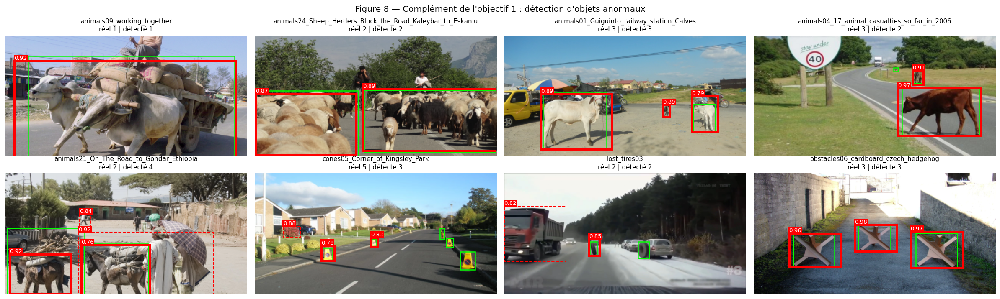

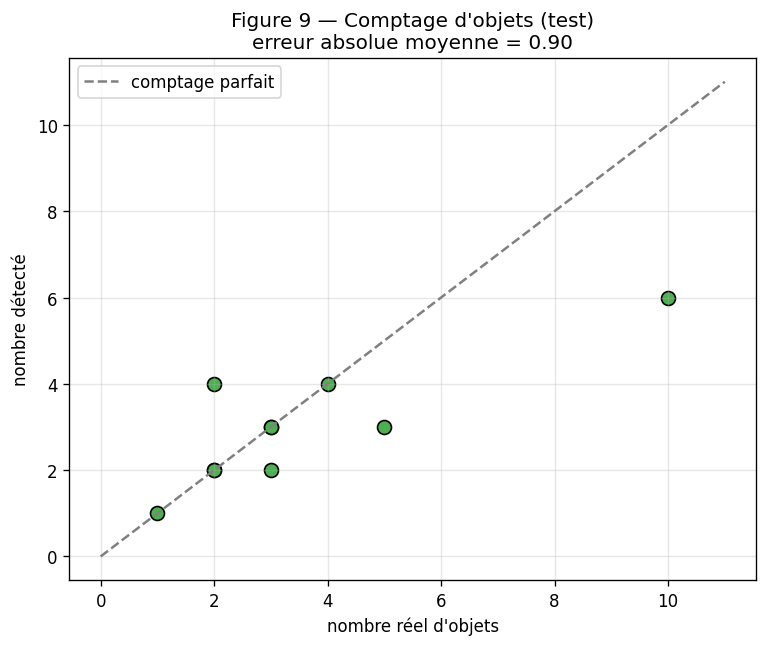

In [ ]:
n_show = min(8, len(det_test))
fig, axes = plt.subplots(2, 4, figsize=(20, 6.2), squeeze=False)
for a in axes.ravel(): a.axis("off")
for a, r in zip(axes.ravel(), det_test[:n_show]):
    a.imshow(r["x"].permute(1, 2, 0))
    for b in r["gt"]["boxes"]:
        a.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=1.5))
    pk = subset(r["pred"], DET_THR); _, tp = match_instances(pk, r["gt"]["masks"].bool())
    for b, sc, ok in zip(pk["boxes"], pk["scores"], tp):
        a.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=3 if ok else 1.2, ls="-" if ok else "--"))
        a.text(b[0], max(b[1] - 3, 8), f"{sc:.2f}", color="white", fontsize=8, bbox=dict(fc="red", ec="none", pad=1))
    a.set_title(f"{r['s']['name']}\nréel {len(r['gt']['masks'])} | détecté {len(pk['scores'])}", fontsize=9)
fig.suptitle("Figure 8 — Complément de l'objectif 1 : détection d'objets anormaux"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig8_detection.png", dpi=130); plt.show()

# Figure 9 — comptage
cnt_gt   = [len(r["gt"]["masks"]) for r in det_test]
cnt_pred = [int((r["pred"]["scores"] >= DET_THR).sum()) for r in det_test]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
mx = max(cnt_gt + cnt_pred + [1]) + 1
ax.plot([0, mx], [0, mx], "--", c="gray", label="comptage parfait")
ax.scatter(cnt_gt, cnt_pred, s=70, c="#4CAF50", edgecolor="k")
ax.set_xlabel("nombre réel d'objets"); ax.set_ylabel("nombre détecté"); ax.legend(); ax.grid(alpha=.3)
ax.set_title(f"Figure 9 — Comptage d'objets (test)\nerreur absolue moyenne = {DET_RES['MAE_comptage']:.2f}")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig9_counting.png", dpi=130); plt.show()

---
# PARTIE 7 — Objectif 2 : CLASSIFIER l'anomalie (catégorie et nom)

**Question posée : de quel type d'anomalie s'agit-il ?**

C'est une tâche de **classification**, différente de la segmentation (qui dit *où*, pas *quoi*). Deux approches complémentaires :

| Sous-partie | Approche | Sortie | Pourquoi |
|---|---|---|---|
| **7.1** | **Classifieur supervisé** : ResNet-18 pré-entraîné sur ImageNet, affiné sur nos images (*apprentissage par transfert*) | une des 5 catégories : animals, obstacles, cones, lost_tires, vehicle | exploite nos étiquettes ; c'est la méthode demandée par le sujet (CNN + transfert) |
| **7.2** | **BLIP** (questions-réponses sur image) sur chaque objet détecté | un **nom écrit librement** par le modèle : chien, vache, valise... | nos données ne contiennent pas les noms précis ; BLIP n'a **aucune liste de noms prédéfinie** |
| **7.3** | Comparaison des deux | exactitude au niveau des catégories | voir ce que chaque approche apporte |

**Précautions (peu de données).** 60 images, dont 52 % d'animaux : (1) poids de classe dans la perte ; (2) on rapporte l'**exactitude** *et* le **F1 macro** (moyenne du F1 de chaque classe, qui ne se laisse pas gonfler par la classe majoritaire) ; (3) on compare à la **référence « classe majoritaire »** ; (4) comme 10 images de test sont très peu, on ajoute une **validation croisée en 3 plis** sur les 60 images.

## 7.1 Classifieur supervisé (ResNet-18, apprentissage par transfert)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, r2_score
from sklearn.model_selection import StratifiedKFold
from scipy.stats import spearmanr

CATS5   = ["animals", "obstacles", "cones", "lost_tires", "vehicle"]
CAT_IDX = {c: i for i, c in enumerate(CATS5)}

# Proportion de pixels anormaux de chaque image (sert à la régression de la Partie 8)
RATIO = {}
for s in all_samples:
    RATIO[s["name"]] = float((np.array(Image.open(s["labels_dir"] / "labels_semantic.png")) == 2).mean())

class ImgDS(Dataset):
    """Image entière -> (x, cible). task='cls' : indice de catégorie ; task='reg' : log(proportion) normalisé."""
    def __init__(self, samples, task, augment=False, mu=0.0, sd=1.0):
        self.samples, self.task, self.augment, self.mu, self.sd = samples, task, augment, mu, sd
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        s = self.samples[i]
        x = TF.to_tensor(Image.open(s["image_path"]).convert("RGB").resize((IMG_W, IMG_H), Image.BILINEAR))
        if self.augment:                                    # transformations qui ne changent ni la catégorie ni la proportion
            if random.random() < 0.5: x = TF.hflip(x)
            if random.random() < 0.5:
                x = TF.adjust_contrast(TF.adjust_brightness(x, random.uniform(0.75, 1.25)), random.uniform(0.75, 1.25)).clamp(0, 1)
        if self.task == "cls": return x, CAT_IDX[s["category"]]
        return x, torch.tensor((np.log(RATIO[s["name"]]) - self.mu) / self.sd, dtype=torch.float32)

class Normalized(nn.Module):
    def __init__(self, net):
        super().__init__(); self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return self.net((x - self.mean) / self.std)

_WARNED = [False]
def make_resnet(n_out):
    from torchvision.models import resnet18, ResNet18_Weights
    try:
        m = resnet18(weights=ResNet18_Weights.DEFAULT); src = "poids ImageNet"
    except Exception as e:
        m = resnet18(weights=None); src = "initialisation ALÉATOIRE (poids ImageNet indisponibles : active Internet)"
    if not _WARNED[0]: print("ResNet-18 :", src); _WARNED[0] = True
    m.fc = nn.Linear(m.fc.in_features, n_out)
    return Normalized(m), src

def train_resnet(task, tr, va=None, epochs=30, lr=3e-4, bs=8, seed=SEED, mu=0.0, sd=1.0):
    """Entraîne un ResNet-18. Avec va : garde le meilleur point de contrôle (perte de validation). Sans va : `epochs` fixes."""
    set_seed(seed); model, _ = make_resnet(len(CATS5) if task == "cls" else 1); model.to(DEVICE)
    dl  = DataLoader(ImgDS(tr, task, True, mu, sd), batch_size=bs, shuffle=True, drop_last=len(tr) > bs)
    dlv = DataLoader(ImgDS(va, task, False, mu, sd), batch_size=bs) if va else None
    if task == "cls":
        cnt = np.bincount([CAT_IDX[s["category"]] for s in tr], minlength=len(CATS5)).astype(float)
        w = torch.tensor(1.0 / np.maximum(cnt, 1), dtype=torch.float32); w = (w / w.sum() * len(CATS5)).to(DEVICE)
        crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
    else:
        crit = nn.SmoothL1Loss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = {"train": [], "val": []}; best = (1e9, None, epochs)
    def run(loader, train):
        model.train(train); tot = n = 0
        with torch.set_grad_enabled(train):
            for x, t in loader:
                x, t = x.to(DEVICE), t.to(DEVICE)
                out = model(x); out = out if task == "cls" else out[:, 0]
                loss = crit(out, t)
                if train: opt.zero_grad(); loss.backward(); opt.step()
                tot += loss.item() * len(x); n += len(x)
        return tot / max(n, 1)
    for ep in range(1, epochs + 1):
        hist["train"].append(run(dl, True))
        if dlv:
            hist["val"].append(run(dlv, False))
            if hist["val"][-1] < best[0]: best = (hist["val"][-1], {k: v.detach().clone() for k, v in model.state_dict().items()}, ep)
    if dlv and best[1] is not None: model.load_state_dict(best[1])
    return model.eval(), hist, best[2]

@torch.no_grad()
def predict_resnet(model, samples, task, mu=0.0, sd=1.0):
    model.eval(); outs = []
    for x, _ in DataLoader(ImgDS(samples, task, False, mu, sd), batch_size=8): outs.append(model(x.to(DEVICE)).cpu())
    o = torch.cat(outs)
    return o.softmax(-1).numpy() if task == "cls" else np.clip(np.exp(o[:, 0].numpy() * sd + mu), 1e-4, 1.0)

# ---------------- Entraînement sur le découpage 40 / 10 / 10 ----------------
EP_CLS = 3 if QUICK_TEST else 30
clf, h_clf, best_ep_clf = train_resnet("cls", train_s, val_s, EP_CLS)
Pc = predict_resnet(clf, test_s, "cls")
y_true_c = np.array([CAT_IDX[s["category"]] for s in test_s]); y_pred_c = Pc.argmax(1)
major = np.bincount([CAT_IDX[s["category"]] for s in train_s]).argmax()
CLS_RES = {"acc": float(accuracy_score(y_true_c, y_pred_c)),
           "f1_macro": float(f1_score(y_true_c, y_pred_c, average="macro", labels=range(len(CATS5)), zero_division=0)),
           "baseline_acc": float(np.mean(y_true_c == major)), "meilleure_epoque": best_ep_clf}

# ---------------- Validation croisée en 3 plis (60 images) ----------------
y_all = np.array([CAT_IDX[s["category"]] for s in all_samples])
cv_pred = np.zeros(len(all_samples), dtype=int); cv_base = np.zeros(len(all_samples), dtype=int)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
for k, (tr_i, te_i) in enumerate(skf.split(np.zeros(len(y_all)), y_all)):
    m_k, _, _ = train_resnet("cls", [all_samples[i] for i in tr_i], None, epochs=max(best_ep_clf, 5))
    cv_pred[te_i] = predict_resnet(m_k, [all_samples[i] for i in te_i], "cls").argmax(1)
    cv_base[te_i] = np.bincount(y_all[tr_i]).argmax()
    print(f"  pli {k + 1}/3 : exactitude {np.mean(cv_pred[te_i] == y_all[te_i]):.3f}")
CLS_RES.update({"cv_acc": float(accuracy_score(y_all, cv_pred)),
                "cv_f1_macro": float(f1_score(y_all, cv_pred, average="macro", labels=range(len(CATS5)), zero_division=0)),
                "cv_baseline_acc": float(accuracy_score(y_all, cv_base))})

print(f"\nClassifieur ResNet-18 — meilleure époque : {best_ep_clf} / {EP_CLS}")
print(f"{'':<34}{'exactitude':>11}{'F1 macro':>10}")
print(f"{'Test (10 images)':<34}{CLS_RES['acc']:>11.3f}{CLS_RES['f1_macro']:>10.3f}")
print(f"{'  référence : classe majoritaire':<34}{CLS_RES['baseline_acc']:>11.3f}")
print(f"{'Validation croisée 3 plis (60 img.)':<34}{CLS_RES['cv_acc']:>11.3f}{CLS_RES['cv_f1_macro']:>10.3f}")
print(f"{'  référence : classe majoritaire':<34}{CLS_RES['cv_baseline_acc']:>11.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 225MB/s]


ResNet-18 : poids ImageNet
  pli 1/3 : exactitude 0.700
  pli 2/3 : exactitude 0.850
  pli 3/3 : exactitude 0.900

Classifieur ResNet-18 — meilleure époque : 10 / 30
                                   exactitude  F1 macro
Test (10 images)                        0.900     0.733
  référence : classe majoritaire        0.500
Validation croisée 3 plis (60 img.)      0.817     0.687
  référence : classe majoritaire        0.517


### Figure 10 — Classifieur supervisé : apprentissage et matrices de confusion
Gauche : perte d'entraînement et de validation. Centre : matrice de confusion sur le test (10 images). Droite : sur les 60 images en validation croisée (plus fiable). Lignes = catégorie réelle, colonnes = catégorie prédite.

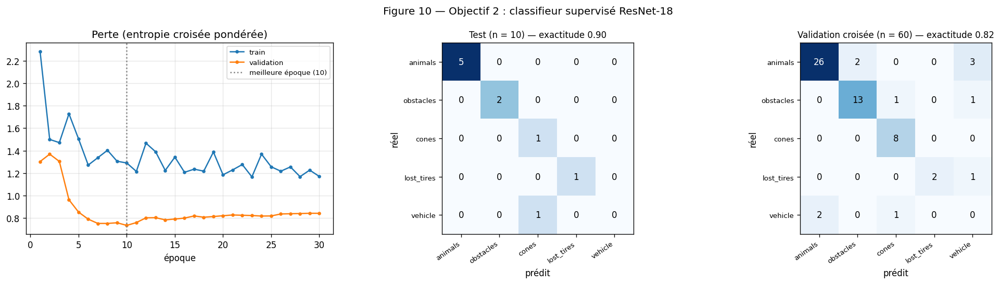

In [ ]:
def plot_cm(ax, yt, yp, title):
    M = confusion_matrix(yt, yp, labels=range(len(CATS5)))
    ax.imshow(M, cmap="Blues"); ax.set_xticks(range(len(CATS5))); ax.set_xticklabels(CATS5, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(CATS5))); ax.set_yticklabels(CATS5, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > max(M.max() / 2, 1) else "black")
    ax.set_title(title, fontsize=10); ax.set_xlabel("prédit"); ax.set_ylabel("réel")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ep = np.arange(1, len(h_clf["train"]) + 1)
ax[0].plot(ep, h_clf["train"], "o-", ms=3, label="train"); ax[0].plot(ep, h_clf["val"], "o-", ms=3, label="validation")
ax[0].axvline(best_ep_clf, ls=":", c="gray", label=f"meilleure époque ({best_ep_clf})")
ax[0].set_title("Perte (entropie croisée pondérée)"); ax[0].set_xlabel("époque"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
plot_cm(ax[1], y_true_c, y_pred_c, f"Test (n = {len(test_s)}) — exactitude {CLS_RES['acc']:.2f}")
plot_cm(ax[2], y_all, cv_pred, f"Validation croisée (n = {len(y_all)}) — exactitude {CLS_RES['cv_acc']:.2f}")
fig.suptitle("Figure 10 — Objectif 2 : classifieur supervisé ResNet-18"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig10_classifier.png", dpi=130); plt.show()

## 7.2 Donner le nom de l'objet, librement (BLIP, vocabulaire ouvert)

**Question posée : qu'est-ce que c'est ? (un chien ? une vache ? une valise ? un cône ?)**

Le jeu de données ne fournit que **5 catégories** : il ne dit pas « chien » ou « vache ». Il faut donc un modèle qui **connaît déjà des milliers de types d'objets**. On utilise **BLIP** (Li et al., 2022, *Salesforce/blip-vqa-base*), un modèle de questions-réponses sur image. Contrairement à un classifieur ou à CLIP, **il n'y a aucune liste de noms prédéfinie** : le modèle regarde l'objet et **écrit lui-même** la réponse (« cow », « rock », « suitcase »...) à la question *« what is the main object in this picture? »*.

**Chaîne complète (segmentation → détection → nom)** : Mask R-CNN détecte l'objet → on découpe l'objet dans l'image d'origine (haute résolution, avec 15 % de contexte) → BLIP écrit son nom.

**Évaluation.** La vérité terrain ne contient que les catégories. Le nom écrit par le modèle est donc rattaché à une catégorie par des règles de mots (chien, vache, mouton... → *animals* ; voiture, camion... → *vehicle* ; cône → *cones* ; pneu, roue → *lost_tires* ; personne, route, ciel... → *autre* ; le reste → *obstacles*), et on mesure l'exactitude au niveau de la **catégorie**. Deux mesures :
1. sur les **objets réels** (découpés avec la vérité terrain) : mesure la reconnaissance seule ;
2. sur les **objets détectés** par Mask R-CNN : mesure la chaîne complète.

La **confiance** affichée est la probabilité que le modèle attribue à sa propre réponse.

**Sans Internet / sans BLIP** : le notebook essaie BLIP (poids Hugging Face, environ 1,5 Go), puis un classifieur ImageNet de torchvision (mille classes seulement, ni cônes ni pneus), puis saute la partie si aucun poids n'est disponible. Colab fonctionne directement ; active *Internet* sur Kaggle.

In [ ]:
CATS_ALL = CATS5 + ["autre"]

# Règles de mots pour rattacher un nom LIBRE (écrit par le modèle) à l'une des 5 catégories du jeu de données.
W_TIRE   = {"tire", "tyre", "wheel", "rim"}
W_CONE   = {"cone", "bollard", "pylon"}
W_VEH    = {"car", "truck", "van", "bus", "motorcycle", "motorbike", "bicycle", "bike", "scooter", "tractor", "trailer", "ambulance", "taxi",
            "jeep", "suv", "pickup", "lorry", "bulldozer", "excavator", "vehicle", "minibus", "rickshaw", "carriage", "wagon", "train", "tram",
            "caravan", "camper", "limousine", "sedan", "cab", "truck"}
W_ANIMAL = {"dog", "puppy", "cow", "bull", "ox", "oxen", "cattle", "calf", "buffalo", "bison", "yak", "horse", "pony", "mule", "donkey", "sheep", "lamb",
            "ram", "goat", "pig", "hog", "boar", "deer", "elk", "moose", "antelope", "gazelle", "camel", "llama", "alpaca", "cat", "kitten", "bird",
            "duck", "goose", "chicken", "hen", "rooster", "turkey", "owl", "eagle", "crow", "pigeon", "swan", "peacock", "ostrich", "penguin",
            "elephant", "zebra", "giraffe", "bear", "wolf", "fox", "rabbit", "hare", "squirrel", "monkey", "ape", "gorilla", "kangaroo", "lion",
            "tiger", "leopard", "cheetah", "hyena", "rhino", "rhinoceros", "hippo", "hippopotamus", "crocodile", "alligator", "snake", "lizard",
            "turtle", "tortoise", "frog", "hedgehog", "badger", "animal", "herd", "flock", "livestock", "otter", "seal", "baboon", "coyote",
            "jackal", "raccoon", "mouse", "rat", "dingo", "bat", "cub", "foal", "kid", "fawn"}
W_OTHER  = {"person", "people", "man", "woman", "men", "women", "boy", "girl", "child", "children", "driver", "rider", "pedestrian", "road",
            "street", "highway", "sky", "tree", "grass", "building", "house", "mountain", "cloud", "field", "bush", "forest", "pole", "sign", "sun"}

def name_to_category(text):
    """Réponse libre du modèle -> catégorie. Pneus et cônes sont testés d'abord (« car tire » = un pneu, pas une voiture),
    puis le premier mot reconnu décide ; 'obstacles' par défaut."""
    words = [w.strip(".,;:!?()\"'").lower() for w in str(text).replace("-", " ").split()]
    forms = [{w, w[:-1] if w.endswith("s") else w, w[:-2] if w.endswith("es") else w} for w in words]
    if any(f & W_TIRE for f in forms): return "lost_tires"
    if any(f & W_CONE for f in forms): return "cones"
    for f in forms:
        if f & W_VEH:    return "vehicle"
        if f & W_ANIMAL: return "animals"
        if f & W_OTHER:  return "autre"
    return "obstacles"

def load_recognizer():
    """Retourne {'name', 'predict(pil_list)->[dict]', 'prob_of(pil_list, key)->tensor'} ou None."""
    # --- 1) BLIP : questions-réponses sur image, réponse LIBRE (aucune liste de noms) ---
    try:
        from transformers import BlipProcessor, BlipForQuestionAnswering
        mname = "Salesforce/blip-vqa-base"
        proc = BlipProcessor.from_pretrained(mname); blip = BlipForQuestionAnswering.from_pretrained(mname).to(DEVICE).eval()
        QUESTION = "what is the main object in this picture?"
        pad_id = blip.config.text_config.pad_token_id
        @torch.no_grad()
        def ask(pils, steps=8):
            inp = proc(images=list(pils), text=[QUESTION] * len(pils), return_tensors="pt", padding=True).to(DEVICE)
            out = blip.generate(**inp, max_new_tokens=steps, output_scores=True, return_dict_in_generate=True)
            seqs = out.sequences
            return seqs, out.scores
        @torch.no_grad()
        def predict(pil_list):
            res = []
            for i in range(0, len(pil_list), 8):
                chunk = pil_list[i:i + 8]; seqs, scores = ask(chunk)
                try:
                    ts = blip.text_decoder.compute_transition_scores(seqs, scores, normalize_logits=True).cpu()
                    keep = (seqs[:, 1:] != pad_id).cpu().float()
                    conf = torch.exp((ts * keep).sum(1)).tolist()
                except Exception:
                    conf = [float("nan")] * len(chunk)
                for s, c in zip(seqs, conf):
                    txt = proc.decode(s, skip_special_tokens=True).strip() or "?"
                    res.append({"key": int(s[1]) if len(s) > 1 else 0, "nom": txt, "cat": name_to_category(txt), "prob": float(c)})
            return res
        @torch.no_grad()
        def prob_of(pil_list, key):
            out = []
            for i in range(0, len(pil_list), 16):
                chunk = pil_list[i:i + 16]
                inp = proc(images=list(chunk), text=[QUESTION] * len(chunk), return_tensors="pt", padding=True).to(DEVICE)
                o = blip.generate(**inp, max_new_tokens=1, output_scores=True, return_dict_in_generate=True)
                out.append(o.scores[0].softmax(-1)[:, key].cpu())
            return torch.cat(out)
        print("Reconnaissance : BLIP VQA (vocabulaire ouvert) chargé.")
        return {"name": "BLIP VQA (vocabulaire ouvert)", "predict": predict, "prob_of": prob_of}
    except Exception as e:
        print("BLIP indisponible (", type(e).__name__, ") -> essai avec ImageNet.")
    # --- 2) Repli : classifieur ImageNet de torchvision (1000 classes seulement) ---
    try:
        from torchvision.models import resnet50, ResNet50_Weights
        w = ResNet50_Weights.DEFAULT; net = resnet50(weights=w).to(DEVICE).eval(); names = w.meta["categories"]; tf = w.transforms()
        def cat_of(k):
            return "animals" if k <= 397 else name_to_category(names[k])
        @torch.no_grad()
        def probs(pil_list):
            return net(torch.stack([tf(im) for im in pil_list]).to(DEVICE)).softmax(-1).cpu()
        def predict(pil_list):
            P = probs(pil_list); p, k = P.max(1)
            return [{"key": int(ki), "nom": names[int(ki)], "cat": cat_of(int(ki)), "prob": float(pi)} for pi, ki in zip(p, k)]
        print("Reconnaissance : repli ImageNet (ResNet-50). Seulement 1000 noms possibles, ni cônes ni pneus : résultats limités.")
        return {"name": "ResNet-50 ImageNet (repli)", "predict": predict, "prob_of": lambda pl, key: probs(pl)[:, key]}
    except Exception as e:
        print("ImageNet indisponible (", type(e).__name__, ").")
    return None

RECOG = load_recognizer()
if RECOG is None:
    print("\nAucun modèle de reconnaissance disponible : la Partie 7.2 et la fin de la Partie 9 sont ignorées. "
          "Active Internet (Kaggle) ou utilise Colab, puis relance cette cellule.")

preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.54GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/788 [00:00<?, ?it/s]

Reconnaissance : BLIP VQA (vocabulaire ouvert) chargé.


In [ ]:
def crop_object(s, box, margin=0.15, min_side=48):
    """Découpe l'objet dans l'image d'origine (haute résolution). box est en coordonnées 256x512.
    Retourne (crop PIL, (x0,y0,x1,y1) en coordonnées 256x512 réellement utilisées)."""
    img = Image.open(s["image_path"]).convert("RGB"); W0, H0 = img.size
    sx, sy = W0 / IMG_W, H0 / IMG_H
    x0, y0, x1, y1 = [float(v) for v in box]
    bw, bh = x1 - x0, y1 - y0
    X0, Y0 = max(0.0, x0 - margin * bw), max(0.0, y0 - margin * bh)
    X1, Y1 = min(float(IMG_W), x1 + margin * bw), min(float(IMG_H), y1 + margin * bh)
    crop = img.crop((int(X0 * sx), int(Y0 * sy), max(int(X1 * sx), int(X0 * sx) + min_side), max(int(Y1 * sy), int(Y0 * sy) + min_side)))
    return crop, (X0, Y0, X1, Y1)

def recognize_rows(rows, thr, use_gt):
    """Nomme chaque objet. use_gt=True : objets réels ; False : objets détectés (seuil thr)."""
    out = []
    for r in rows:
        if use_gt:
            boxes = r["gt"]["boxes"]; scores = [1.0] * len(boxes); tpflags = [True] * len(boxes)
        else:
            pk = subset(r["pred"], thr); boxes = pk["boxes"]; scores = pk["scores"].tolist()
            _, tp = match_instances(pk, r["gt"]["masks"].bool()); tpflags = tp.tolist()
        if len(boxes) == 0: continue
        crops = [crop_object(r["s"], b)[0] for b in boxes]
        preds = RECOG["predict"](crops)
        for b, sc, ok, p in zip(boxes, scores, tpflags, preds):
            out.append({"image": r["s"]["name"], "category": r["s"]["category"], "box": b, "det_score": sc, "tp": ok, **p,
                        "correct": p["cat"] == r["s"]["category"]})
    return out

if RECOG is not None:
    REC_GT  = recognize_rows(det_test, DET_THR, use_gt=True)
    REC_DET = recognize_rows(det_test, DET_THR, use_gt=False)
    acc = lambda L: float(np.mean([o["correct"] for o in L])) if L else float("nan")
    REC_RES = {"modele": RECOG["name"], "acc_objets_reels": acc(REC_GT), "n_objets_reels": len(REC_GT),
               "acc_objets_detectes_tp": acc([o for o in REC_DET if o["tp"]]), "n_detectes_tp": sum(o["tp"] for o in REC_DET),
               "acc_objets_detectes_tous": acc(REC_DET), "n_detectes": len(REC_DET)}
    print(f"Modèle de reconnaissance : {RECOG['name']}")
    print(f"  Exactitude de catégorie — objets réels (reconnaissance seule)   : {REC_RES['acc_objets_reels']:.3f}  (n = {REC_RES['n_objets_reels']})")
    print(f"  Exactitude de catégorie — détections correctes (chaîne 1→2→3)    : {REC_RES['acc_objets_detectes_tp']:.3f}  (n = {REC_RES['n_detectes_tp']})")
    print(f"  Exactitude de catégorie — toutes les détections (avec fausses alarmes) : {REC_RES['acc_objets_detectes_tous']:.3f}  (n = {REC_RES['n_detectes']})")
    print("\nNoms les plus fréquents par catégorie (objets réels) :")
    for c in CATS5:
        names_c = [o["nom"] for o in REC_GT if o["category"] == c]
        if names_c:
            vals, cnt = np.unique(names_c, return_counts=True); o = np.argsort(-cnt)[:4]
            print(f"  {c:<11}", ", ".join(f"{vals[i]} ({cnt[i]})" for i in o))

Modèle de reconnaissance : BLIP VQA (vocabulaire ouvert)
  Exactitude de catégorie — objets réels (reconnaissance seule)   : 0.714  (n = 35)
  Exactitude de catégorie — détections correctes (chaîne 1→2→3)    : 0.762  (n = 21)
  Exactitude de catégorie — toutes les détections (avec fausses alarmes) : 0.633  (n = 30)

Noms les plus fréquents par catégorie (objets réels) :
  animals     cow (3), dog (2), donkey (2), elephant (1)
  obstacles   car (2), plane (2), sculpture (2), bear (1)
  cones       cone (3), caution cone (1), traffic light (1)
  lost_tires  car (1), suitcase (1)
  vehicle     cone (2), bulldozer (1), orange cone (1)


### Figure 11 — Les objets détectés avec leur nom
Chaque boîte porte le nom donné par le modèle de reconnaissance et sa probabilité. Titre vert : la catégorie du nom correspond à la catégorie de l'image ; rouge : elle ne correspond pas.

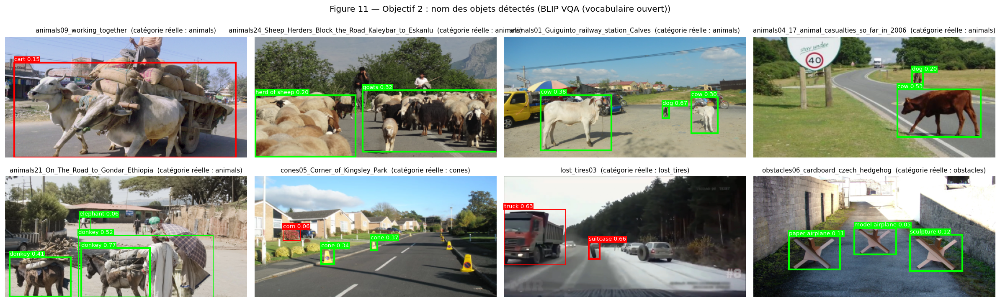

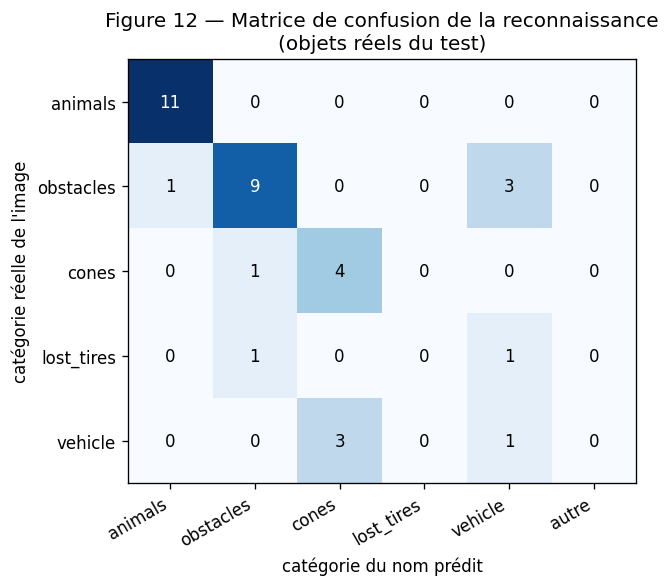

In [ ]:
if RECOG is not None and REC_DET:
    by_img = defaultdict(list)
    for o in REC_DET: by_img[o["image"]].append(o)
    names_show = [r["s"]["name"] for r in det_test if r["s"]["name"] in by_img][:8]
    fig, axes = plt.subplots(2, 4, figsize=(20, 6.4), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, nm in zip(axes.ravel(), names_show):
        r = next(r for r in det_test if r["s"]["name"] == nm); a.imshow(r["x"].permute(1, 2, 0))
        for o in by_img[nm]:
            b = o["box"]; col = "lime" if o["correct"] else "red"
            a.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=col, lw=2.5 if o["tp"] else 1.2))
            a.text(b[0], max(b[1] - 3, 8), f"{o['nom']} {o['prob']:.2f}", color="white", fontsize=8, bbox=dict(fc=col, ec="none", pad=1))
        a.set_title(f"{nm}  (catégorie réelle : {r['s']['category']})", fontsize=9)
    fig.suptitle(f"Figure 11 — Objectif 2 : nom des objets détectés ({RECOG['name']})"); plt.tight_layout()
    plt.savefig(OUT_DIR / "fig11_recognition.png", dpi=130); plt.show()

    # Figure 12 — matrice de confusion (objets réels)
    M = np.zeros((len(CATS5), len(CATS_ALL)), dtype=int)
    for o in REC_GT: M[CATS5.index(o["category"]), CATS_ALL.index(o["cat"])] += 1
    fig, ax = plt.subplots(figsize=(7.5, 5))
    im = ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(len(CATS_ALL))); ax.set_xticklabels(CATS_ALL, rotation=30, ha="right")
    ax.set_yticks(range(len(CATS5))); ax.set_yticklabels(CATS5)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xlabel("catégorie du nom prédit"); ax.set_ylabel("catégorie réelle de l'image")
    ax.set_title("Figure 12 — Matrice de confusion de la reconnaissance\n(objets réels du test)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "fig12_confusion.png", dpi=130); plt.show()

## 7.3 Comparaison des deux approches de classification
Les deux méthodes ne répondent pas exactement à la même question, d'où deux niveaux de comparaison, tous deux au niveau des **catégories** (la seule vérité terrain disponible) :
* **ResNet-18** : prédit directement la catégorie de l'**image entière**.
* **BLIP** : nomme chaque **objet** ; la catégorie de l'image est le vote majoritaire des catégories déduites de ses noms (les mots « route, ciel, personne... » sont ignorés). Deux variantes : objets *réels* (mesure la reconnaissance seule) et objets *détectés* par Mask R-CNN (chaîne complète).

In [ ]:
def image_level_vote(rec_list, names):
    pred = {}
    for nm in names:
        cats = [o["cat"] for o in rec_list if o["image"] == nm and o["cat"] != "autre"]
        pred[nm] = max(set(cats), key=cats.count) if cats else "autre"
    return pred

CLS_TABLE = [("Référence : classe majoritaire", CLS_RES["baseline_acc"], None),
             ("ResNet-18 supervisé (test)", CLS_RES["acc"], CLS_RES["f1_macro"]),
             ("ResNet-18 supervisé (validation croisée, 60 img.)", CLS_RES["cv_acc"], CLS_RES["cv_f1_macro"])]
if RECOG is not None:
    names_t = [s["name"] for s in test_s]; truth = {s["name"]: s["category"] for s in test_s}
    for lab, L in [("BLIP, objets réels (test)", REC_GT), ("BLIP, objets détectés par Mask R-CNN (test)", REC_DET)]:
        pv = image_level_vote(L, names_t)
        yt_ = [CAT_IDX[truth[n]] for n in names_t]; yp_ = [CAT_IDX.get(pv[n], -1) for n in names_t]
        CLS_TABLE.append((lab, float(np.mean(np.array(yt_) == np.array(yp_))),
                          float(f1_score(yt_, yp_, average="macro", labels=range(len(CATS5)), zero_division=0))))
CLS_RES["comparaison"] = [{"methode": a, "exactitude": b, "f1_macro": c} for a, b, c in CLS_TABLE]
print(f"{'Méthode':<54}{'exactitude':>11}{'F1 macro':>10}")
for a, b, c in CLS_TABLE: print(f"{a:<54}{b:>11.3f}{('%.3f' % c) if c is not None else '':>10}")
print("\nRemarque : le test ne compte que 10 images ; la validation croisée (60 images) est la mesure la plus fiable pour le ResNet.")

Méthode                                                exactitude  F1 macro
Référence : classe majoritaire                              0.500          
ResNet-18 supervisé (test)                                  0.900     0.733
ResNet-18 supervisé (validation croisée, 60 img.)           0.817     0.687
BLIP, objets réels (test)                                   0.800     0.493
BLIP, objets détectés par Mask R-CNN (test)                 0.600     0.391

Remarque : le test ne compte que 10 images ; la validation croisée (60 images) est la mesure la plus fiable pour le ResNet.


---
# PARTIE 8 — Objectif 3 : QUANTIFIER la gravité (régression)

**Question posée : quelle part de l'image l'anomalie occupe-t-elle ?**

C'est une tâche de **régression** : la sortie n'est plus une classe ni un masque, mais **un nombre**. Pour un véhicule autonome, une grande anomalie est plus dangereuse (plus difficile à éviter, plus proche) qu'un petit objet au loin. Nous définissons donc la **gravité** par la **proportion de pixels anormaux** de l'image (de 0,4 % à 42 % dans ce jeu). C'est une définition volontairement simple : elle ne tient compte ni de la position ni de la distance.

On compare trois façons de l'estimer :
1. **Régression directe** : un ResNet-18 pré-entraîné prédit le nombre à partir de l'image, sans produire de masque. On prédit le *logarithme* de la proportion (les valeurs couvrent plus d'un ordre de grandeur) avec une perte de Huber.
2. **Via la segmentation** : on compte la part de pixels marqués par U-Net, l'autoencodeur ou Mask R-CNN (Objectif 1), sans entraînement supplémentaire.
3. **Référence** : prédire toujours la médiane des images d'entraînement.

**Métriques** : MAE et RMSE (en points de pourcentage de l'image), R² (1 = parfait, 0 = pas mieux que la moyenne, négatif = pire), corrélation de rang de Spearman, et **niveau de gravité** (petite < 5 %, moyenne 5-15 %, grande > 15 %). Validation croisée en 3 plis pour la régression directe.

In [ ]:
EP_REG = 3 if QUICK_TEST else 40
lr_tr = np.log([RATIO[s["name"]] for s in train_s]); MU, SD = float(lr_tr.mean()), float(lr_tr.std() + 1e-6)
reg, h_reg, best_ep_reg = train_resnet("reg", train_s, val_s, EP_REG, mu=MU, sd=SD)

y_true_r = np.array([RATIO[s["name"]] for s in test_s])
BINS = [0.05, 0.15]; BIN_NAMES = ["petite (< 5 %)", "moyenne (5-15 %)", "grande (> 15 %)"]
EST = {"Régression directe (ResNet-18)": predict_resnet(reg, test_s, "reg", MU, SD)}
for label in MODEL_KEYS:
    P_, _ = TEST[label]; EST[f"Via segmentation : {label}"] = np.clip((P_ > THR[label]).mean((1, 2)), 1e-4, 1)
EST["Référence : médiane du train"] = np.full(len(test_s), float(np.median([RATIO[s["name"]] for s in train_s])))

def reg_metrics(yt, yp):
    sp = spearmanr(yt, yp).correlation if np.std(yp) > 0 and len(yt) > 2 else float("nan")
    return {"MAE_pts": float(100 * np.mean(np.abs(yt - yp))), "RMSE_pts": float(100 * np.sqrt(np.mean((yt - yp) ** 2))),
            "R2": float(r2_score(yt, yp)), "Spearman": float(sp),
            "niveau_acc": float(np.mean(np.digitize(yt, BINS) == np.digitize(yp, BINS)))}

REG_RES = {k: reg_metrics(y_true_r, v) for k, v in EST.items()}

# Validation croisée 3 plis (régression directe vs référence)
y_ratio_all = np.array([RATIO[s["name"]] for s in all_samples])
cv_reg = np.zeros(len(all_samples)); cv_med = np.zeros(len(all_samples))
for k, (tr_i, te_i) in enumerate(skf.split(np.zeros(len(y_all)), y_all)):
    l_ = np.log(y_ratio_all[tr_i]); mu_k, sd_k = float(l_.mean()), float(l_.std() + 1e-6)
    m_k, _, _ = train_resnet("reg", [all_samples[i] for i in tr_i], None, epochs=max(best_ep_reg, 5), mu=mu_k, sd=sd_k)
    cv_reg[te_i] = predict_resnet(m_k, [all_samples[i] for i in te_i], "reg", mu_k, sd_k)
    cv_med[te_i] = np.median(y_ratio_all[tr_i])
REG_RES["CV : régression directe"] = reg_metrics(y_ratio_all, cv_reg)
REG_RES["CV : référence médiane"]  = reg_metrics(y_ratio_all, cv_med)

print(f"Régression — meilleure époque : {best_ep_reg} / {EP_REG}\n")
print(f"{'Estimateur':<42}{'MAE (pts)':>10}{'RMSE':>8}{'R²':>8}{'Spearman':>10}{'niveau':>8}")
for k, r in REG_RES.items():
    print(f"{k:<42}{r['MAE_pts']:>10.2f}{r['RMSE_pts']:>8.2f}{r['R2']:>8.2f}{r['Spearman']:>10.2f}{r['niveau_acc']:>8.2f}")
print("\nMAE en points de pourcentage de l'image (ex. 3,0 = l'estimation se trompe de 3 % de l'image en moyenne).")

Régression — meilleure époque : 23 / 40

Estimateur                                 MAE (pts)    RMSE      R²  Spearman  niveau
Régression directe (ResNet-18)                  7.29   12.50    0.19      0.64    0.70
Via segmentation : U-Net                       10.88   16.71   -0.45      0.24    0.70
Via segmentation : Autoencoder                 43.57   47.54  -10.74      0.52    0.30
Via segmentation : Mask R-CNN                   3.64    4.81    0.88      0.73    0.80
Référence : médiane du train                    9.18   15.21   -0.20       nan    0.40
CV : régression directe                         5.93    8.62    0.25      0.49    0.50
CV : référence médiane                          7.48   10.87   -0.19     -0.24    0.35

MAE en points de pourcentage de l'image (ex. 3,0 = l'estimation se trompe de 3 % de l'image en moyenne).


### Figure 13 — Régression : proportion de l'image occupée par l'anomalie
Gauche : valeur réelle contre valeur estimée sur le test (la diagonale = estimation parfaite). Centre : régression directe en validation croisée (60 images). Droite : erreur absolue moyenne (plus bas = mieux).

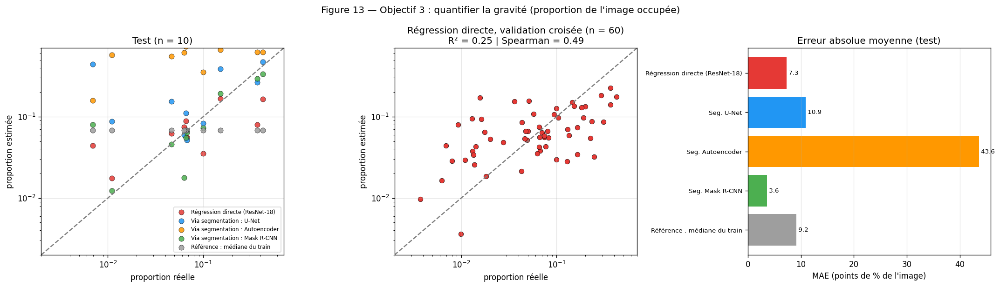

In [ ]:
colors = ["#E53935", "#2196F3", "#FF9800", "#4CAF50", "#9E9E9E"]
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
lim = (0.002, 0.7)
ax[0].plot(lim, lim, "--", c="gray")
for (k, v), c in zip(EST.items(), colors): ax[0].scatter(y_true_r, v, s=45, c=c, edgecolor="k", lw=.4, label=k, alpha=.85)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("proportion réelle"); ax[0].set_ylabel("proportion estimée"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[0].set_title(f"Test (n = {len(test_s)})")
ax[1].plot(lim, lim, "--", c="gray"); ax[1].scatter(y_ratio_all, cv_reg, s=40, c="#E53935", edgecolor="k", lw=.4)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlim(lim); ax[1].set_ylim(lim); ax[1].grid(alpha=.3)
ax[1].set_xlabel("proportion réelle"); ax[1].set_ylabel("proportion estimée")
ax[1].set_title(f"Régression directe, validation croisée (n = {len(y_all)})\nR² = {REG_RES['CV : régression directe']['R2']:.2f} | Spearman = {REG_RES['CV : régression directe']['Spearman']:.2f}")
names_b = list(EST.keys()); mae_b = [REG_RES[k]["MAE_pts"] for k in names_b]
ax[2].barh(range(len(names_b)), mae_b, color=colors); ax[2].set_yticks(range(len(names_b)))
ax[2].set_yticklabels([n.replace("Via segmentation : ", "Seg. ") for n in names_b], fontsize=8); ax[2].invert_yaxis()
for i, v in enumerate(mae_b): ax[2].text(v, i, f" {v:.1f}", va="center", fontsize=8)
ax[2].set_xlabel("MAE (points de % de l'image)"); ax[2].set_title("Erreur absolue moyenne (test)"); ax[2].grid(axis="x", alpha=.3)
fig.suptitle("Figure 13 — Objectif 3 : quantifier la gravité (proportion de l'image occupée)"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig13_regression.png", dpi=130); plt.show()

---
# PARTIE 9 — XAI : expliquer les décisions des modèles

**Question posée : pourquoi le modèle a-t-il décidé cela ? Regarde-t-il le bon endroit ?**

Un modèle peut avoir un bon score en regardant la mauvaise chose (le fond, une ombre). L'**IA explicable (XAI)** produit des **cartes de chaleur** qui montrent quelles zones de l'image ont influencé la décision. Une méthode adaptée est utilisée pour chaque famille de modèles :

| Modèle (objectif) | Méthode XAI | Principe |
|---|---|---|
| **U-Net** (Obj. 1 · segmentation) | **Seg-Grad-CAM** | Les gradients de la sortie « anomalie » par rapport aux cartes de caractéristiques du décodeur indiquent quelles caractéristiques ont poussé à la décision. |
| **Autoencodeur** (Obj. 1 · segmentation) | **Erreur de reconstruction** + **saliency par gradient** | Explication *intrinsèque* : l'erreur est le score lui-même. Le gradient du score par rapport aux pixels de l'image montre ce qui l'influence. |
| **Mask R-CNN** (Obj. 1 · segmentation par objet) | **RISE** (boîte noire) | On masque aléatoirement l'image des centaines de fois et on mesure l'effet sur le score de l'objet détecté : les pixels qui comptent sont ceux dont le masquage fait chuter le score. |
| **BLIP** (Obj. 2 · nom libre) | **Occlusion** | On cache successivement des zones de l'objet et on mesure la baisse de probabilité du premier mot de la réponse. |
| **ResNet-18 classifieur** (Obj. 2) et **régresseur** (Obj. 3) | **Grad-CAM** | Gradient du score de la classe prédite (ou du nombre prédit) par rapport à la dernière couche convolutive. |

**Évaluation quantitative.** Une belle carte ne prouve rien ; on la mesure de deux façons :
* **Concentration (« energy pointing game »)** : part de la carte de chaleur qui tombe sur les pixels réellement anormaux. À comparer avec la part de l'image qu'ils occupent (le hasard).
* **Fidélité (suppression)** : on efface les 20 % de pixels que l'explication juge les plus importants et on regarde de combien le score du modèle sur la zone anormale chute, par rapport à l'effacement de 20 % de pixels **au hasard**. Une explication fidèle fait chuter le score plus que le hasard.

In [ ]:
N_XAI  = 3 if QUICK_TEST else len(test_s)      # nombre d'images de test expliquées
N_RISE = 40 if QUICK_TEST else 250            # nombre de masques aléatoires pour RISE
test_ds = RoadAnomalyDataset(test_s)

def norm01(h):
    h = h - h.min()
    return h / h.max().clamp(min=1e-8) if torch.is_tensor(h) else h / max(h.max(), 1e-8)

# ---------- U-Net : Seg-Grad-CAM ----------
def gradcam_unet(x, layer):
    store = {}
    def fwd_hook(m, i, o): o.retain_grad(); store["a"] = o
    hd = layer.register_forward_hook(fwd_hook)
    unet.eval(); unet.zero_grad()
    logits = unet(x[None].to(DEVICE))
    target = (torch.sigmoid(logits) > THR["U-Net"]).float()
    if target.sum() < 1:                                   # rien détecté : on explique les pixels les plus « anormaux »
        target = (logits >= torch.quantile(logits.flatten(), 0.95)).float()
    (logits * target).sum().div(target.sum()).backward()
    hd.remove()
    a = store["a"]; w = a.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True)).detach()
    cam = F.interpolate(cam, (IMG_H, IMG_W), mode="bilinear", align_corners=False)[0, 0]
    return norm01(cam).cpu()

# ---------- Autoencodeur : erreur + saliency ----------
def ae_explain(x):
    ae.eval(); xb = x[None].to(DEVICE).clone().requires_grad_(True)
    rec = ae(xb); err = (xb - rec).abs().mean(1, keepdim=True)
    score = F.avg_pool2d(err, 7, 1, 3).mean()
    ae.zero_grad(); score.backward()
    sal = xb.grad.abs().max(1, keepdim=True).values
    sal = F.avg_pool2d(sal, 9, 1, 4)[0, 0].cpu()
    err_map = F.avg_pool2d(err.detach(), 7, 1, 3)[0, 0].cpu()
    return norm01(err_map), norm01(sal), rec.detach()[0].cpu()

# ---------- Mask R-CNN : RISE ----------
@torch.no_grad()
def rise_maskrcnn(x, target_box, n=N_RISE, cells=(8, 16), p=0.5, batch=16, seed=0):
    g = torch.Generator().manual_seed(seed)
    M = F.interpolate((torch.rand(n, 1, *cells, generator=g) < p).float(), (IMG_H, IMG_W), mode="bilinear", align_corners=False)
    sal = torch.zeros(IMG_H, IMG_W); tb = target_box.view(1, 4).float()
    mrcnn.eval()
    for i in range(0, n, batch):
        mb = M[i:i + batch]
        outs = mrcnn([(x * m).to(DEVICE) for m in mb])
        for m, o in zip(mb, outs):
            s = 0.0
            if len(o["boxes"]):
                iou = tv_ops.box_iou(o["boxes"].cpu(), tb)[:, 0]
                s = float((o["scores"].cpu() * iou).max())
            sal += s * m[0]
    return norm01(sal / (n * p))

# ---------- Cartes de probabilité d'un modèle (pour la fidélité) ----------
@torch.no_grad()
def prob_map(name, x):
    xb = x[None].to(DEVICE)
    if name == "unet":
        return torch.sigmoid(unet.eval()(xb))[0, 0].cpu()
    out = mrcnn.eval()([xb[0]])[0]
    if len(out["scores"]):
        return (out["scores"].view(-1, 1, 1) * out["masks"][:, 0]).max(0).values.cpu()
    return torch.zeros(IMG_H, IMG_W)

def deletion_drop(name, x, heat, gt, frac=0.2, n_rand=3, seed=0):
    """Score moyen sur la zone anormale : après effacement des frac% pixels les plus importants vs au hasard."""
    gtb = gt.bool(); base = float(prob_map(name, x)[gtb].mean())
    k = int(frac * heat.numel())
    def erase(idx):
        xe = x.clone().view(3, -1); xe[:, idx] = 0.5
        return float(prob_map(name, xe.view(3, IMG_H, IMG_W))[gtb].mean())
    top = erase(torch.topk(heat.flatten(), k).indices)
    g = torch.Generator().manual_seed(seed)
    rnd = float(np.mean([erase(torch.randperm(heat.numel(), generator=g)[:k]) for _ in range(n_rand)]))
    return base, top, rnd

def energy_in_mask(heat, gt):
    h = heat.clamp(min=0); gtb = gt.bool()
    return float(h[gtb].sum() / h.sum().clamp(min=1e-8)), float(gtb.float().mean()), bool(gtb.flatten()[int(h.argmax())])

XAI = {"U-Net (Grad-CAM)": [], "AE erreur": [], "AE saliency": [], "Mask R-CNN (RISE)": []}
DEL = {"U-Net (Grad-CAM)": [], "Mask R-CNN (RISE)": []}
XAI_VIS = []
t0 = time.time()
for i in range(N_XAI):
    x, y, _ = test_ds[i]; gt = y[0]; name = test_s[i]["name"]
    cam = gradcam_unet(x, unet.d4)
    err_map, sal, rec = ae_explain(x)
    det = det_test[i]["pred"]; pk = subset(det, DET_THR)
    if len(pk["scores"]) == 0: pk = subset(det, 0.0)
    rise = None
    if len(pk["scores"]):
        top = int(torch.argmax(pk["scores"])); rise = rise_maskrcnn(x, pk["boxes"][top])
    for key, h in [("U-Net (Grad-CAM)", cam), ("AE erreur", err_map), ("AE saliency", sal), ("Mask R-CNN (RISE)", rise)]:
        if h is not None: XAI[key].append(energy_in_mask(h, gt))
    DEL["U-Net (Grad-CAM)"].append(deletion_drop("unet", x, cam, gt))
    if rise is not None: DEL["Mask R-CNN (RISE)"].append(deletion_drop("maskrcnn", x, rise, gt))
    XAI_VIS.append({"name": name, "x": x, "gt": gt, "cam": cam, "err": err_map, "sal": sal, "rec": rec, "rise": rise,
                    "p_unet": prob_map("unet", x)})
    print(f"  XAI {i + 1}/{N_XAI}  {name}  ({time.time() - t0:.0f}s)")

  XAI 1/10  animals09_working_together  (9s)
  XAI 2/10  animals24_Sheep_Herders_Block_the_Road_Kaleybar_to_Eskanlu  (18s)
  XAI 3/10  animals01_Guiguinto_railway_station_Calves  (27s)
  XAI 4/10  animals04_17_animal_casualties_so_far_in_2006  (36s)
  XAI 5/10  animals21_On_The_Road_to_Gondar_Ethiopia  (45s)
  XAI 6/10  cones05_Corner_of_Kingsley_Park  (54s)
  XAI 7/10  lost_tires03  (63s)
  XAI 8/10  obstacles06_cardboard_czech_hedgehog  (72s)
  XAI 9/10  obstacles12_rocks4  (81s)
  XAI 10/10  vehicle02_Broadmoor_Cones_Skidloader  (90s)


### Figure 14 — Explications des modèles de localisation et de détection
Colonnes : image avec la vérité terrain (contour vert) · prédiction du U-Net · Seg-Grad-CAM (U-Net) · erreur de reconstruction (autoencodeur) · saliency par gradient (autoencodeur) · RISE (Mask R-CNN). Plus la zone est chaude (jaune/rouge), plus elle a influencé la décision.

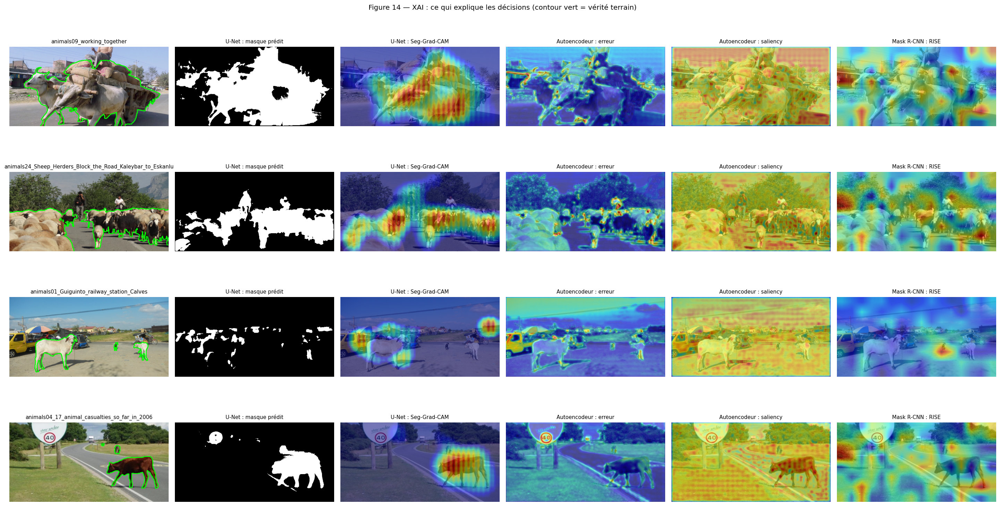

In [ ]:
def show_heat(a, img, heat, title):
    a.imshow(img); a.imshow(heat, cmap="jet", alpha=0.5, vmin=0, vmax=1); a.set_title(title, fontsize=9); a.axis("off")

n_fig = min(4, len(XAI_VIS))
fig, axes = plt.subplots(n_fig, 6, figsize=(24, 3.3 * n_fig), squeeze=False)
for r, v in zip(axes, XAI_VIS[:n_fig]):
    img = v["x"].permute(1, 2, 0).numpy()
    r[0].imshow(img); r[0].contour(v["gt"].numpy(), levels=[0.5], colors="lime", linewidths=1.5); r[0].set_title(v["name"], fontsize=9); r[0].axis("off")
    r[1].imshow(v["p_unet"].numpy() > THR["U-Net"], cmap="gray"); r[1].set_title("U-Net : masque prédit", fontsize=9); r[1].axis("off")
    show_heat(r[2], img, v["cam"].numpy(), "U-Net : Seg-Grad-CAM")
    show_heat(r[3], img, v["err"].numpy(), "Autoencodeur : erreur")
    show_heat(r[4], img, v["sal"].numpy(), "Autoencodeur : saliency")
    if v["rise"] is not None: show_heat(r[5], img, v["rise"].numpy(), "Mask R-CNN : RISE")
    else: r[5].set_title("Mask R-CNN : aucune détection", fontsize=9); r[5].axis("off")
fig.suptitle("Figure 14 — XAI : ce qui explique les décisions (contour vert = vérité terrain)"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig14_xai_maps.png", dpi=120); plt.show()

### Figure 15 — XAI du classifieur et du régresseur (Objectifs 2 et 3) : Grad-CAM
Pour le ResNet-18, on utilise **Grad-CAM** sur la dernière couche convolutive : le gradient du score de la classe prédite (classifieur) ou du nombre prédit (régresseur) indique quelles zones l'ont fait monter. Les deux dernières colonnes montrent la même méthode pour les deux têtes : si le classifieur regarde bien l'objet anormal, la carte s'y concentre ; un modèle qui regarde le fond (route, ciel) aurait de bons scores pour de mauvaises raisons.

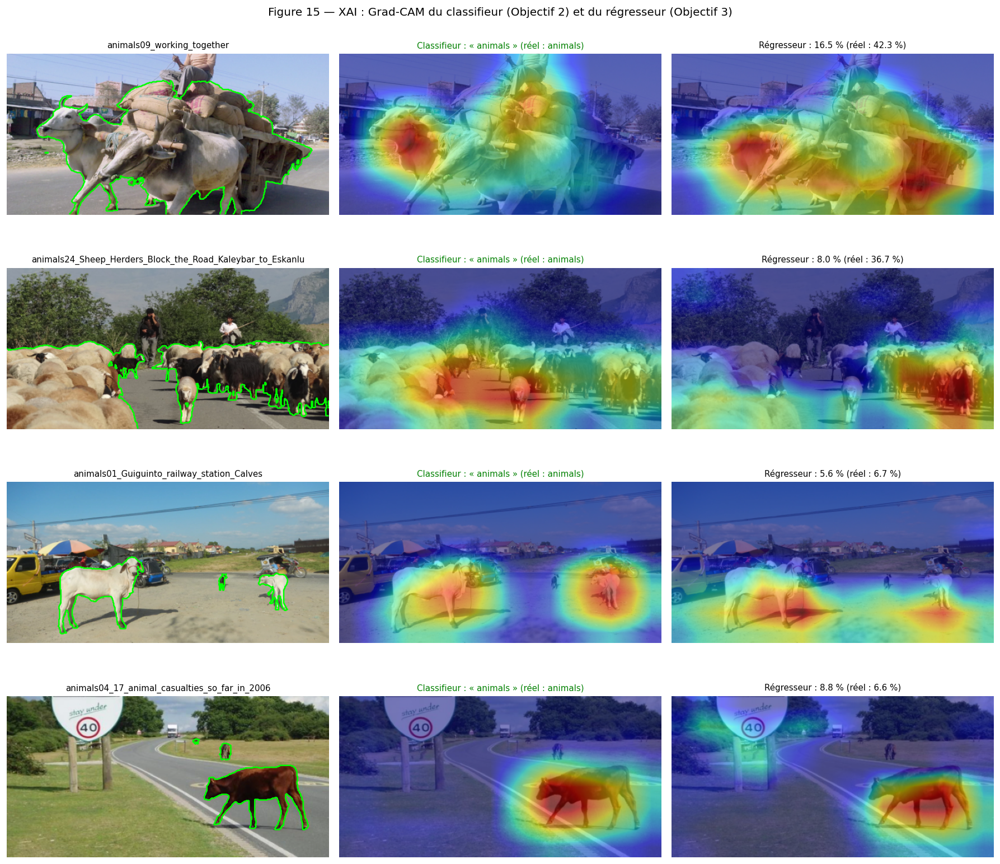

In [ ]:
def gradcam_resnet(model, x, task, cls_idx=None):
    store = {}
    def fh(m, i, o): o.retain_grad(); store["a"] = o
    hd = model.net.layer4.register_forward_hook(fh); model.eval(); model.zero_grad()
    out = model(x[None].to(DEVICE))
    k = int(out.argmax(1)) if (task == "cls" and cls_idx is None) else cls_idx
    (out[0, k] if task == "cls" else out[0, 0]).backward(); hd.remove()
    a = store["a"]; w = a.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True)).detach()
    return norm01(F.interpolate(cam, (IMG_H, IMG_W), mode="bilinear", align_corners=False)[0, 0]).cpu()

@torch.no_grad()
def cls_prob_fn(k):
    return lambda xx: float(clf.eval()(xx[None].to(DEVICE)).softmax(-1)[0, k])
@torch.no_grad()
def reg_val_fn():
    return lambda xx: float(np.clip(np.exp(float(reg.eval()(xx[None].to(DEVICE))[0, 0]) * SD + MU), 1e-4, 1))

def deletion_generic(fn, x, heat, frac=0.2, n_rand=3, seed=0):
    base = fn(x); k = int(frac * heat.numel())
    def erase(idx):
        xe = x.clone().view(3, -1); xe[:, idx] = 0.5
        return fn(xe.view(3, IMG_H, IMG_W))
    top = erase(torch.topk(heat.flatten(), k).indices)
    g = torch.Generator().manual_seed(seed)
    rnd = float(np.mean([erase(torch.randperm(heat.numel(), generator=g)[:k]) for _ in range(n_rand)]))
    return base, top, rnd

XAI["Classifieur (Grad-CAM)"] = []; XAI["Régresseur (Grad-CAM)"] = []
DEL["Classifieur (Grad-CAM)"] = []; DEL["Régresseur (Grad-CAM)"] = []
CAM_VIS = []
for i in range(N_XAI):
    x, y, _ = test_ds[i]; gt = y[0]
    k_pred = int(Pc[i].argmax())
    cam_c = gradcam_resnet(clf, x, "cls"); cam_r = gradcam_resnet(reg, x, "reg")
    XAI["Classifieur (Grad-CAM)"].append(energy_in_mask(cam_c, gt)); XAI["Régresseur (Grad-CAM)"].append(energy_in_mask(cam_r, gt))
    with torch.no_grad():
        DEL["Classifieur (Grad-CAM)"].append(deletion_generic(cls_prob_fn(k_pred), x, cam_c))
        DEL["Régresseur (Grad-CAM)"].append(deletion_generic(reg_val_fn(), x, cam_r))
    CAM_VIS.append({"name": test_s[i]["name"], "x": x, "gt": gt, "cam_c": cam_c, "cam_r": cam_r, "pred": CATS5[k_pred],
                    "true": test_s[i]["category"], "r_pred": float(EST["Régression directe (ResNet-18)"][i]), "r_true": float(y_true_r[i])})

n_fig = min(4, len(CAM_VIS))
fig, axes = plt.subplots(n_fig, 3, figsize=(15, 3.4 * n_fig), squeeze=False)
for r_, v in zip(axes, CAM_VIS[:n_fig]):
    img = v["x"].permute(1, 2, 0).numpy()
    r_[0].imshow(img); r_[0].contour(v["gt"].numpy(), levels=[0.5], colors="lime", linewidths=1.5); r_[0].set_title(v["name"], fontsize=9); r_[0].axis("off")
    ok = v["pred"] == v["true"]
    show_heat(r_[1], img, v["cam_c"].numpy(), f"Classifieur : « {v['pred']} » (réel : {v['true']})")
    r_[1].title.set_color("green" if ok else "red")
    show_heat(r_[2], img, v["cam_r"].numpy(), f"Régresseur : {100 * v['r_pred']:.1f} % (réel : {100 * v['r_true']:.1f} %)")
fig.suptitle("Figure 15 — XAI : Grad-CAM du classifieur (Objectif 2) et du régresseur (Objectif 3)"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig15_xai_cls_reg.png", dpi=120); plt.show()

### Figure 16 — Évaluation quantitative des explications

Méthode                énergie dans l anomalie  part de l image (hasard)  rapport  pointing game
U-Net (Grad-CAM)                         0.293                     0.130     2.25           0.50
AE erreur                                0.172                     0.130     1.32           0.50
AE saliency                              0.131                     0.130     1.00           0.40
Mask R-CNN (RISE)                        0.136                     0.130     1.05           0.10
Classifieur (Grad-CAM)                   0.256                     0.130     1.97           0.30
Régresseur (Grad-CAM)                    0.234                     0.130     1.80           0.40


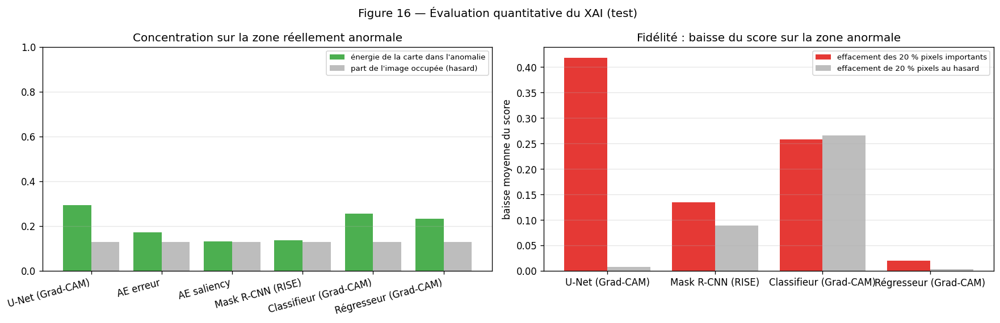

In [ ]:
rows_x = []
for k, L in XAI.items():
    if not L: continue
    en = np.array([a for a, _, _ in L]); ar = np.array([b for _, b, _ in L]); hit = np.array([c for _, _, c in L])
    rows_x.append((k, en.mean(), ar.mean(), en.mean() / max(ar.mean(), 1e-8), hit.mean()))
print(f"{'Méthode':<22}{'énergie dans l anomalie':>24}{'part de l image (hasard)':>26}{'rapport':>9}{'pointing game':>15}")
for k, e, a, r_, h in rows_x:
    print(f"{k:<22}{e:>24.3f}{a:>26.3f}{r_:>9.2f}{h:>15.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
labs = [r_[0] for r_ in rows_x]; xx = np.arange(len(labs))
axes[0].bar(xx - 0.2, [r_[1] for r_ in rows_x], 0.4, label="énergie de la carte dans l'anomalie", color="#4CAF50")
axes[0].bar(xx + 0.2, [r_[2] for r_ in rows_x], 0.4, label="part de l'image occupée (hasard)", color="#BDBDBD")
axes[0].set_xticks(xx); axes[0].set_xticklabels(labs, rotation=15, ha="right"); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)
axes[0].set_title("Concentration sur la zone réellement anormale"); axes[0].grid(axis="y", alpha=.3)

dl = [(k, np.array(v)) for k, v in DEL.items() if v]
xx2 = np.arange(len(dl))
axes[1].bar(xx2 - 0.2, [(v[:, 0] - v[:, 1]).mean() for _, v in dl], 0.4, label="effacement des 20 % pixels importants", color="#E53935")
axes[1].bar(xx2 + 0.2, [(v[:, 0] - v[:, 2]).mean() for _, v in dl], 0.4, label="effacement de 20 % pixels au hasard", color="#BDBDBD")
axes[1].set_xticks(xx2); axes[1].set_xticklabels([k for k, _ in dl]); axes[1].legend(fontsize=8)
axes[1].set_title("Fidélité : baisse du score sur la zone anormale"); axes[1].set_ylabel("baisse moyenne du score"); axes[1].grid(axis="y", alpha=.3)
fig.suptitle("Figure 16 — Évaluation quantitative du XAI (test)"); plt.tight_layout()
plt.savefig(OUT_DIR / "fig16_xai_quant.png", dpi=130); plt.show()
XAI_RES = {k: {"energie": e, "aire": a, "rapport": r_, "pointing": h} for k, e, a, r_, h in rows_x}
XAI_DEL = {k: {"baisse_importants": float((v[:, 0] - v[:, 1]).mean()), "baisse_hasard": float((v[:, 0] - v[:, 2]).mean())} for k, v in dl}

### Figure 17 — XAI du nom donné par BLIP (Objectif 2) : pourquoi ce nom ?
Pour chaque objet, on masque tour à tour une zone de l'image et on mesure la baisse de la probabilité du nom prédit. Zones chaudes = zones qui justifient le nom.

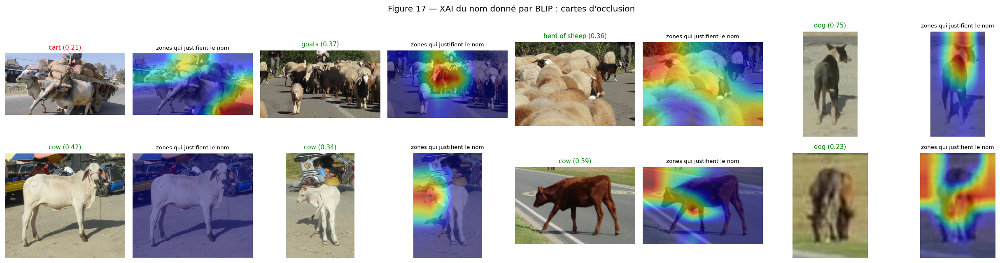

Importance moyenne des cartes d'occlusion : centre = 0.336 | bords = 0.215 (le centre du recadrage contient l'objet)


In [ ]:
@torch.no_grad()
def occlusion_map(crop, key, grid=6, win=2):
    """Baisse de probabilité du nom `key` quand une fenêtre (win x win cases) est grisée. Retourne une carte [h,w] normalisée."""
    W, H = crop.size; base = float(RECOG["prob_of"]([crop], key)[0])
    heat = np.zeros((grid, grid)); cnt = np.zeros((grid, grid)); ims, pos = [], []
    for i in range(grid - win + 1):
        for j in range(grid - win + 1):
            im = crop.copy(); x0, x1 = int(j * W / grid), int((j + win) * W / grid); y0, y1 = int(i * H / grid), int((i + win) * H / grid)
            im.paste((128, 128, 128), (x0, y0, x1, y1)); ims.append(im); pos.append((i, j))
    pr = RECOG["prob_of"](ims, key)
    for (i, j), p in zip(pos, pr):
        heat[i:i + win, j:j + win] += base - float(p); cnt[i:i + win, j:j + win] += 1
    heat = np.clip(heat / np.maximum(cnt, 1), 0, None)
    heat = np.array(Image.fromarray(heat.astype(np.float32)).resize((W, H), Image.BILINEAR))
    return heat / max(heat.max(), 1e-8), base

OCC = []
if RECOG is not None and REC_DET:
    cand = [o for o in REC_DET if o["tp"]][:8] or REC_DET[:8]
    n_c = len(cand); cols = min(4, n_c); rows_n = int(np.ceil(n_c / cols))
    fig, axes = plt.subplots(rows_n, cols * 2, figsize=(5.2 * cols, 2.7 * rows_n), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for k, o in enumerate(cand):
        s = next(r["s"] for r in det_test if r["s"]["name"] == o["image"])
        crop, _ = crop_object(s, o["box"]); heat, base = occlusion_map(crop, o["key"])
        a1, a2 = axes[k // cols, 2 * (k % cols)], axes[k // cols, 2 * (k % cols) + 1]
        a1.imshow(crop); a1.set_title(f"{o['nom']} ({base:.2f})", fontsize=9, color="green" if o["correct"] else "red")
        a2.imshow(crop); a2.imshow(heat, cmap="jet", alpha=0.5); a2.set_title("zones qui justifient le nom", fontsize=8)
        OCC.append({"nom": o["nom"], "prob": base, "centre": float(heat[heat.shape[0] // 4: 3 * heat.shape[0] // 4, heat.shape[1] // 4: 3 * heat.shape[1] // 4].mean()),
                    "bords": float(np.concatenate([heat[:heat.shape[0] // 4].ravel(), heat[3 * heat.shape[0] // 4:].ravel()]).mean())})
    fig.suptitle("Figure 17 — XAI du nom donné par BLIP : cartes d'occlusion"); plt.tight_layout()
    plt.savefig(OUT_DIR / "fig17_xai_recognition.png", dpi=130); plt.show()
    print("Importance moyenne des cartes d'occlusion : centre =", f"{np.mean([o['centre'] for o in OCC]):.3f}",
          "| bords =", f"{np.mean([o['bords'] for o in OCC]):.3f}", "(le centre du recadrage contient l'objet)")

---
# SYNTHÈSE — Les trois objectifs et le XAI

In [ ]:
SUMMARY = {"objectif1_segmentation": {k: RES[k] | {"PR_AUC": PRAUC[k], "seuil": THR[k]} for k in RES},
           "objectif1_complement_detection": DET_RES,
           "objectif2_classification": CLS_RES,
           "objectif2_nom_blip": REC_RES if RECOG is not None else None,
           "objectif3_regression": REG_RES,
           "xai_concentration": XAI_RES, "xai_fidelite": XAI_DEL}
with open(OUT_DIR / "results_objectives.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, indent=2, ensure_ascii=False, default=float)

print("=" * 80)
print("OBJECTIF 1 — SEGMENTATION (où sont les pixels anormaux ?)  [test]")
for k, r in RES.items(): print(f"  {k:<13} IoU {r['IoU']:.3f} | F1 {r['F1']:.3f} | PR-AUC {PRAUC[k]:.3f}")
print(f"  (complément, Mask R-CNN par objet : précision {DET_RES['precision']:.2f}, rappel {DET_RES['recall']:.2f}, AP50 {DET_RES['AP50']:.2f}, erreur de comptage {DET_RES['MAE_comptage']:.2f})")
print("\nOBJECTIF 2 — CLASSIFICATION (de quel type d'anomalie s'agit-il ?)")
print(f"  ResNet-18 : exactitude {CLS_RES['acc']:.2f} / F1 macro {CLS_RES['f1_macro']:.2f} (test) ; "
      f"{CLS_RES['cv_acc']:.2f} / {CLS_RES['cv_f1_macro']:.2f} (validation croisée) ; référence classe majoritaire {CLS_RES['cv_baseline_acc']:.2f}")
if RECOG is not None:
    print(f"  {REC_RES['modele']} (nom libre) : catégorie déduite correcte pour {100 * REC_RES['acc_objets_reels']:.0f} % des objets réels, "
          f"{100 * REC_RES['acc_objets_detectes_tp']:.0f} % des objets correctement détectés")
else:
    print("  BLIP : non évalué (aucun modèle de reconnaissance disponible)")
print("\nOBJECTIF 3 — RÉGRESSION (quelle part de l'image l'anomalie occupe-t-elle ?)")
d = REG_RES["Régression directe (ResNet-18)"]; bsl = REG_RES["Référence : médiane du train"]
print(f"  ResNet-18 direct : MAE {d['MAE_pts']:.1f} pts, R² {d['R2']:.2f}, Spearman {d['Spearman']:.2f} (test) ; référence médiane : MAE {bsl['MAE_pts']:.1f} pts")
cvd, cvb = REG_RES["CV : régression directe"], REG_RES["CV : référence médiane"]
print(f"  Validation croisée : MAE {cvd['MAE_pts']:.1f} pts, R² {cvd['R2']:.2f}, Spearman {cvd['Spearman']:.2f} ; référence médiane : MAE {cvb['MAE_pts']:.1f} pts")
print("\nXAI — les modèles regardent-ils la bonne zone ?")
for k, v in XAI_RES.items():
    verdict = "mieux que le hasard" if v["rapport"] > 1.2 else "proche du hasard"
    print(f"  {k:<24} {100 * v['energie']:.0f} % de l'énergie dans l'anomalie pour {100 * v['aire']:.0f} % de l'image (x{v['rapport']:.1f}) -> {verdict}")
for k, v in XAI_DEL.items():
    verdict = "fidèle" if v["baisse_importants"] > v["baisse_hasard"] * 1.2 else "pas plus fidèle que le hasard"
    print(f"  {k:<24} baisse : {v['baisse_importants']:.3f} (pixels importants) contre {v['baisse_hasard']:.3f} (hasard) -> {verdict}")
print("=" * 80)
print("Résultats enregistrés dans", OUT_DIR / "results_objectives.json")

OBJECTIF 1 — SEGMENTATION (où sont les pixels anormaux ?)  [test]
  U-Net         IoU 0.338 | F1 0.462 | PR-AUC 0.613
  Autoencoder   IoU 0.154 | F1 0.247 | PR-AUC 0.224
  Mask R-CNN    IoU 0.560 | F1 0.666 | PR-AUC 0.864
  (complément, Mask R-CNN par objet : précision 0.70, rappel 0.60, AP50 0.65, erreur de comptage 0.90)

OBJECTIF 2 — CLASSIFICATION (de quel type d'anomalie s'agit-il ?)
  ResNet-18 : exactitude 0.90 / F1 macro 0.73 (test) ; 0.82 / 0.69 (validation croisée) ; référence classe majoritaire 0.52
  BLIP VQA (vocabulaire ouvert) (nom libre) : catégorie déduite correcte pour 71 % des objets réels, 76 % des objets correctement détectés

OBJECTIF 3 — RÉGRESSION (quelle part de l'image l'anomalie occupe-t-elle ?)
  ResNet-18 direct : MAE 7.3 pts, R² 0.19, Spearman 0.64 (test) ; référence médiane : MAE 9.2 pts
  Validation croisée : MAE 5.9 pts, R² 0.25, Spearman 0.49 ; référence médiane : MAE 7.5 pts

XAI — les modèles regardent-ils la bonne zone ?
  U-Net (Grad-CAM)         2

### Limites à citer dans le rapport
* **Segmentation / détection** : les instances de référence viennent des composantes connexes du masque ; deux objets qui se touchent comptent pour un seul. Le test contient 10 images.
* **Classification** : 60 images, 5 catégories très déséquilibrées (lost_tires et vehicle : 3 images chacune) ; c'est pourquoi on donne le F1 macro, la référence « classe majoritaire » et une validation croisée. Le classifieur voit l'image entière : il peut s'appuyer sur le décor (campagne pour les animaux) plutôt que sur l'objet ; le Grad-CAM (Figure 15) permet de le vérifier. BLIP n'a pas été entraîné sur ce jeu et peut se tromper (réponse trop générique, objet confondu) ; la vérité terrain ne contient pas les noms précis (chien ou vache ne peut pas être vérifié, seulement la catégorie déduite par des règles de mots). L'évaluation dépend donc de ces règles. Les personnes présentes dans les images « animals » ne sont pas annotées comme anomalie.
* **Régression** : la « gravité » est définie par la seule surface occupée ; elle ignore la position (sur la route ou non), la distance et le type d'objet. Avec 60 images, le R² est instable.
* **XAI** : les cartes sont des *approximations* du raisonnement du modèle. Grad-CAM est de basse résolution ; RISE dépend du nombre de masques ; l'occlusion dépend de la taille de la fenêtre. Les mesures de concentration et de fidélité reposent sur 10 images.
* **Références** : Selvaraju et al. 2017 (Grad-CAM, ICCV) ; Petsiuk et al. 2018 (RISE, BMVC) ; Li et al. 2022 (BLIP, ICML) ; Zeiler & Fergus 2014 (occlusion, ECCV) ; He et al. 2016 (ResNet, CVPR).

---
# PARTIE 10 — Export des modèles pour l'application de démonstration

L'**application de démonstration est un projet séparé** (`app.py`, fourni à part). Elle permet de tester le projet sur n'importe quelle image avec trois onglets : **Segmentation**, **Classification** et **Gravité**. Pour fonctionner, elle a besoin des modèles entraînés ici : cette cellule les sauvegarde dans `outputs_345/weights/` avec le fichier de configuration `app_config.json` (seuils, constantes de normalisation). Tout est ensuite téléchargé dans l'archive `outputs_345.zip`.

Les modèles exportés sont ceux de l'entraînement complet de ce notebook.

In [ ]:
import json
torch.save(clf.state_dict(), MODELS_DIR / "clf_resnet18.pth")      # classifieur ResNet-18 (Objectif 2)
torch.save(reg.state_dict(), MODELS_DIR / "reg_resnet18.pth")      # régresseur ResNet-18 (Objectif 3)
with open(OUT_DIR / "app_config.json", "w") as f:
    json.dump({"THR": THR, "DET_THR": DET_THR, "AE_SCALE": AE_SCALE, "MU": MU, "SD": SD}, f, indent=2)
print("Export pour l'application dans", OUT_DIR.resolve())
for p in sorted(MODELS_DIR.glob("*.pth")): print(f"  weights/{p.name:<22} {p.stat().st_size / 1e6:7.1f} Mo")
print("  app_config.json")

Export pour l'application dans /content/outputs_345
  weights/best_ae.pth                5.7 Mo
  weights/best_maskrcnn.pth        176.2 Mo
  weights/best_unet.pth             31.1 Mo
  weights/clf_resnet18.pth          44.8 Mo
  weights/reg_resnet18.pth          44.8 Mo
  app_config.json


---
## Fin : archive à télécharger

In [ ]:
archive = shutil.make_archive(str(WORK_DIR / "outputs_345"), "zip", str(OUT_DIR))
print("Archive créée :", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)                  # télécharge l'archive sur ton PC
else:
    print("Sur Kaggle : onglet 'Output' (panneau de droite) -> télécharge outputs_345.zip")
if QUICK_TEST:
    print("\nRappel : test rapide (1 époque). Relance sans la variable RA_QUICK_TEST pour l'entraînement complet.")

Archive créée : /content/outputs_345.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>